# GEVE single-cell transcriptomics: manuscript figures and tables

This notebook reproduces the single-cell RNA-seq figures of the manuscript (Figures 2 and 3, Figures S2 and S3,
Appendix Figures 3–10) and Supplementary Tables S1–S8. It starts from the QC-filtered AnnData objects
(GEO GSE347098 and Zenodo; see `README.md`).

**Lytic/latent modules.** This version re-derives the lytic and latent GEVE gene modules
from the **506 canonical GEVE genes**. The 22 relic loci in the GTF are excluded. The steps are:
- Appendix Figure 9: detection-rate comparison, Active GEVE Expressing Cells vs High-GEVE.
- Appendix Figure 10: Ward clustering of the 39 High-GEVE cells.
- Module definition: the two k = 2 gene clusters become the lytic and latent modules.

Every downstream figure uses these modules.

**Inputs** (place in `adata/`, or set `GEVE_ADATA_DIR`):
- `adata_all_qc.h5ad`: QC-filtered cells, all genes, raw counts
- `adata_hi4_hvg_geve_umap.h5ad`: GEVE > 4 cells with UMAP and `cluster_hi4`

**Outputs**: `figures/`, `tables/`


In [1]:
# -- CONFIG: repository paths --
import os
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

BASE      = Path.cwd()                      # repository root (run the notebook from here)
ADATA_DIR = Path(os.environ.get('GEVE_ADATA_DIR', BASE / 'adata'))
FIG_DIR   = BASE / 'figures'
TABLE_DIR = BASE / 'tables'
VIRION_CSV = BASE / 'data' / 'virion_proteome' / 'GEVE_virion_proteins_ErazoGarcia2025.csv'
FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

for _f in ['adata_all_qc.h5ad', 'adata_hi4_hvg_geve_umap.h5ad']:
    assert (ADATA_DIR / _f).exists(), f'Missing {ADATA_DIR / _f} (see README: GEO GSE347098 / Zenodo)'
print('Repository :', BASE.name)
print('AnnData dir:', ADATA_DIR.relative_to(BASE) if ADATA_DIR.is_relative_to(BASE) else ADATA_DIR)


Repository : Git folder
AnnData dir: adata


## GEVE gene annotation (506 canonical genes)

Builds `gdf_track`, the per-gene table used throughout the notebook. It holds coordinates, the BVP/DVP cluster, 6mA marks, introns, the NCLDV late-promoter motif (FIMO q < 0.05), NCLDV marker/Pfam/GVOG annotation and virion structural proteins (mapped by coordinate from Erazo-Garcia et al. 2025, Data S1/S5; derived table in `data/virion_proteome/`).

**Source**: `GEVE_manuscript_figures.ipynb`

**File**: — (no figure; values used downstream)


In [2]:
# -- COMPUTE: GEVE genome annotation + epigenetic/promoter data (annotation used by Fig 2, S2, S9–S11) --
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.patches import Polygon
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')

FIG_DIR.mkdir(exist_ok=True)

# Gene annotation
ANNO_PATH = BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx'
gdf_track = pd.read_excel(ANNO_PATH)
gdf_track = gdf_track.rename(columns={'Unnamed: 0': 'gene_num'})
gdf_track = gdf_track.sort_values('gene_num').reset_index(drop=True)
gdf_track.loc[gdf_track['strand'] == 'g', 'strand'] = '+'

# TIR coordinates
TIR1_START, TIR1_END = 2_023_526, 2_038_329
TIR2_START, TIR2_END = 2_629_749, 2_640_528
n_genes_track = len(gdf_track)
coding_span   = gdf_track['end'].max() - gdf_track['start'].min()
bp_per_unit   = coding_span / n_genes_track
tir1_units_t  = (TIR1_END - TIR1_START) / bp_per_unit
tir2_units_t  = (TIR2_END - TIR2_START) / bp_per_unit

BVP_COLOR_T  = '#F6D03C'
DVP_COLOR_T  = '#E1594D'
UNC_COLOR_T  = '#cccccc'
TIR_COLOR_T  = '#c8b99a'

gdf_track['color'] = gdf_track['cluster'].map(
    lambda c: BVP_COLOR_T if c == 'BVP' else (DVP_COLOR_T if c == 'DVP' else UNC_COLOR_T)
)
# Introns = host-type (spliceosomal) introns only. The MCP gene (GEVEv2_329) carries a group IC1
# self-splicing intron, so it is excluded from the intron set (61 genes) in every figure and table.
SELF_SPLICING_INTRON_GENES = {'GEVEv2_329'}
gdf_track['has_introns'] = (gdf_track['introns'] == 'yes') & ~gdf_track['gene'].isin(SELF_SPLICING_INTRON_GENES)

# 6mA gene set from curated annotation (GEVEv2_full_ano sheet, mod_6mA column)
_anno_6mA = pd.read_excel(ANNO_PATH, sheet_name='GEVEv2_full_ano')
_6mA_genes = set(_anno_6mA.loc[_anno_6mA['mod_6mA'] == 'yes', 'gene'])
gdf_track['has_6mA'] = gdf_track['gene'].isin(_6mA_genes)

PROM_FILE = BASE / 'data' / 'GEVE_promoters' / 'late_promoter_fimo_q05.txt'
with open(PROM_FILE) as fh:
    late_prom_genes_t = set(line.strip() for line in fh if line.strip())
gdf_track['has_late_prom'] = gdf_track['gene'].isin(late_prom_genes_t)
# Virion proteome (Erazo-Garcia et al. 2025 Data S5 -> mapped to GEVEv2 via genomic coordinates)
_vr       = pd.read_csv(VIRION_CSV)   # derived from Data S1 (viralrecall_anno) + Data S5 (filt_data)
_virion_acc  = set(_vr.loc[_vr['detected_in_virion_proteome'], 'protein_ids'])
_start_map   = {int(r['start_in_complete_contig_536']): r['protein_ids'] for _, r in _vr.iterrows()}
_end_map     = {int(r['end_in_complete_contig_536']):   r['protein_ids'] for _, r in _vr.iterrows()}
gdf_track['_pacc'] = gdf_track['start'].apply(lambda s: _start_map.get(int(s)))
_nm = gdf_track['_pacc'].isna()
gdf_track.loc[_nm, '_pacc'] = gdf_track.loc[_nm, 'end'].apply(lambda e: _end_map.get(int(e)))
gdf_track['has_virion_prot'] = gdf_track['_pacc'].isin(_virion_acc)
gdf_track = gdf_track.drop(columns=['_pacc'])

print(f"Genes: {n_genes_track}  BVP: {(gdf_track['cluster']=='BVP').sum()}  "
      f"DVP: {(gdf_track['cluster']=='DVP').sum()}  "
      f"Unclassified: {(~gdf_track['cluster'].isin(['BVP', 'DVP'])).sum()}")
print(f"Introns: {gdf_track['has_introns'].sum()}  6mA: {gdf_track['has_6mA'].sum()}  "
      f"Late prom: {gdf_track['has_late_prom'].sum()}  "
      f"Virion proteins: {gdf_track['has_virion_prot'].sum()}")


Genes: 506  BVP: 24  DVP: 157  Unclassified: 325
Introns: 61  6mA: 53  Late prom: 105  Virion proteins: 42


## Figure S2. Pairwise co-occurrence among six binary GEVE genomic features (BVP, DVP, 6mA, Introns, NCLDV Promoter, Virion Proteins) across 506 annotated GEVE genes

Pairwise Fisher exact tests between the six binary GEVE gene features (14 pairs), shown as an UpSet-style plot.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/FigS2_feature_cooccurrence_upset.png`, `.pdf`, `.svg`


In [3]:
# -- COMPUTE: pairwise Fisher's exact tests for GEVE binary features (Figure S2, Supplementary Table 5) --
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact, false_discovery_control
from itertools import combinations

gdf_s = pd.read_excel(BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx')
gdf_s = gdf_s.rename(columns={'Unnamed: 0': 'gene_num'})
gdf_s.loc[gdf_s['strand'] == 'g', 'strand'] = '+'

_anno_6mA_s = pd.read_excel(BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx', sheet_name='GEVEv2_full_ano')
_6mA_genes_s = set(_anno_6mA_s.loc[_anno_6mA_s['mod_6mA'] == 'yes', 'gene'])
gdf_s['has_6mA']     = gdf_s['gene'].isin(_6mA_genes_s)
gdf_s['has_introns'] = (gdf_s['introns'] == 'yes') & ~gdf_s['gene'].isin(SELF_SPLICING_INTRON_GENES)  # spliceosomal only (MCP excluded; see c003)
gdf_s['is_BVP']      = gdf_s['cluster'] == 'BVP'
gdf_s['is_DVP']      = gdf_s['cluster'] == 'DVP'

with open(BASE / 'data' / 'GEVE_promoters' / 'late_promoter_fimo_q05.txt') as fh:
    _prom_genes = set(line.strip() for line in fh if line.strip())
gdf_s['has_ncldv']        = gdf_s['gene'].isin(_prom_genes)
# Virion proteome (Erazo-Garcia et al. 2025 Data S5 -> mapped to GEVEv2 via genomic coordinates)
_vr       = pd.read_csv(VIRION_CSV)   # derived from Data S1 (viralrecall_anno) + Data S5 (filt_data)
_virion_acc  = set(_vr.loc[_vr['detected_in_virion_proteome'], 'protein_ids'])
_start_map   = {int(r['start_in_complete_contig_536']): r['protein_ids'] for _, r in _vr.iterrows()}
_end_map     = {int(r['end_in_complete_contig_536']):   r['protein_ids'] for _, r in _vr.iterrows()}
gdf_s['_pacc'] = gdf_s['start'].apply(lambda s: _start_map.get(int(s)))
_nm = gdf_s['_pacc'].isna()
gdf_s.loc[_nm, '_pacc'] = gdf_s.loc[_nm, 'end'].apply(lambda e: _end_map.get(int(e)))
gdf_s['has_virion_prot'] = gdf_s['_pacc'].isin(_virion_acc)
gdf_s = gdf_s.drop(columns=['_pacc'])

n_genes_s = len(gdf_s)

feat_labels = ['BVP', 'DVP', '6mA', 'Introns', 'NCLDV\nPromoter', 'Virion\nProteins']
feat_vecs   = [
    gdf_s['is_BVP'],
    gdf_s['is_DVP'],
    gdf_s['has_6mA'],
    gdf_s['has_introns'],
    gdf_s['has_ncldv'],
    gdf_s['has_virion_prot'],
]
feat_counts = [v.sum() for v in feat_vecs]

EXCLUDE = {('BVP', 'DVP'), ('DVP', 'BVP')}

nf = len(feat_labels)
OR_mat  = np.full((nf, nf), np.nan)
p_mat   = np.full((nf, nf), np.nan)
obs_mat = np.full((nf, nf), np.nan)
exp_mat = np.full((nf, nf), np.nan)

pairs_for_fdr = []
for i, j in combinations(range(nf), 2):
    la, lb = feat_labels[i].replace('\n', ' '), feat_labels[j].replace('\n', ' ')
    if (la, lb) in EXCLUDE or (lb, la) in EXCLUDE:
        continue
    va, vb = feat_vecs[i], feat_vecs[j]
    both   = (va & vb).sum()
    a_only = (va & ~vb).sum()
    b_only = (~va & vb).sum()
    nei    = (~va & ~vb).sum()
    exp    = va.sum() * vb.sum() / n_genes_s
    or_, p = fisher_exact([[both, a_only], [b_only, nei]])
    pairs_for_fdr.append((i, j, or_, p, both, exp))

p_vals = [x[3] for x in pairs_for_fdr]
fdrs   = false_discovery_control(p_vals)

for (i, j, or_, p, obs, exp), fdr in zip(pairs_for_fdr, fdrs):
    log2or = np.log2(or_) if or_ > 0 else -10
    for ii, jj in [(i, j), (j, i)]:
        OR_mat[ii, jj]  = log2or
        p_mat[ii, jj]   = fdr
        obs_mat[ii, jj] = obs
        exp_mat[ii, jj] = exp

def fdr_stars(fdr):
    if np.isnan(fdr): return ''
    if fdr < 0.001:   return '***'
    if fdr < 0.01:    return '**'
    if fdr < 0.05:    return '*'
    return 'ns'

print(f'Features tested (n={n_genes_s} genes):')
for lbl, cnt in zip(feat_labels, feat_counts):
    print(f'  {lbl.replace(chr(10)," "):12s}: {cnt}')
print('\nPairwise results (FDR-corrected):')
for (i, j, or_, p, obs, exp), fdr in zip(pairs_for_fdr, fdrs):
    la = feat_labels[i].replace('\n', ' ')
    lb = feat_labels[j].replace('\n', ' ')
    print(f'  {la} x {lb:<16} OR={or_:.3f}  obs={obs}  exp={exp:.1f}  FDR={fdr:.3e}  {fdr_stars(fdr)}')
# Build pair_stats_f dict (consumed by Supplementary Table 5)
pair_stats_f = {}
for (i, j, or_, p, both, exp), fdr in zip(pairs_for_fdr, fdrs):
    va, vb = feat_vecs[i].astype(bool), feat_vecs[j].astype(bool)
    n11 = int((va & vb).sum())
    n10 = int((va & ~vb).sum())
    n01 = int((~va & vb).sum())
    n00 = int((~va & ~vb).sum())
    pair_stats_f[(i, j)] = (or_, p, fdr, (n11, n10, n01, n00))


Features tested (n=506 genes):
  BVP         : 24
  DVP         : 157
  6mA         : 53
  Introns     : 61
  NCLDV Promoter: 105
  Virion Proteins: 42

Pairwise results (FDR-corrected):
  BVP x 6mA              OR=7.292  obs=10  exp=2.5  FDR=2.023e-04  ***
  BVP x Introns          OR=4.962  obs=9  exp=2.9  FDR=2.563e-03  **
  BVP x NCLDV Promoter   OR=0.158  obs=1  exp=5.0  FDR=5.439e-02  ns
  BVP x Virion Proteins  OR=0.468  obs=1  exp=2.0  FDR=7.104e-01  ns
  DVP x 6mA              OR=0.484  obs=10  exp=16.4  FDR=5.439e-02  ns
  DVP x Introns          OR=0.767  obs=16  exp=18.9  FDR=4.968e-01  ns
  DVP x NCLDV Promoter   OR=2.628  obs=51  exp=32.6  FDR=1.926e-04  ***
  DVP x Virion Proteins  OR=2.681  obs=22  exp=13.0  FDR=5.597e-03  **
  6mA x Introns          OR=14.255  obs=28  exp=6.4  FDR=5.198e-14  ***
  6mA x NCLDV Promoter   OR=0.206  obs=3  exp=11.0  FDR=5.201e-03  **
  6mA x Virion Proteins  OR=0.000  obs=0  exp=4.4  FDR=2.613e-02  *
  Introns x NCLDV Promoter   OR=0.113  o

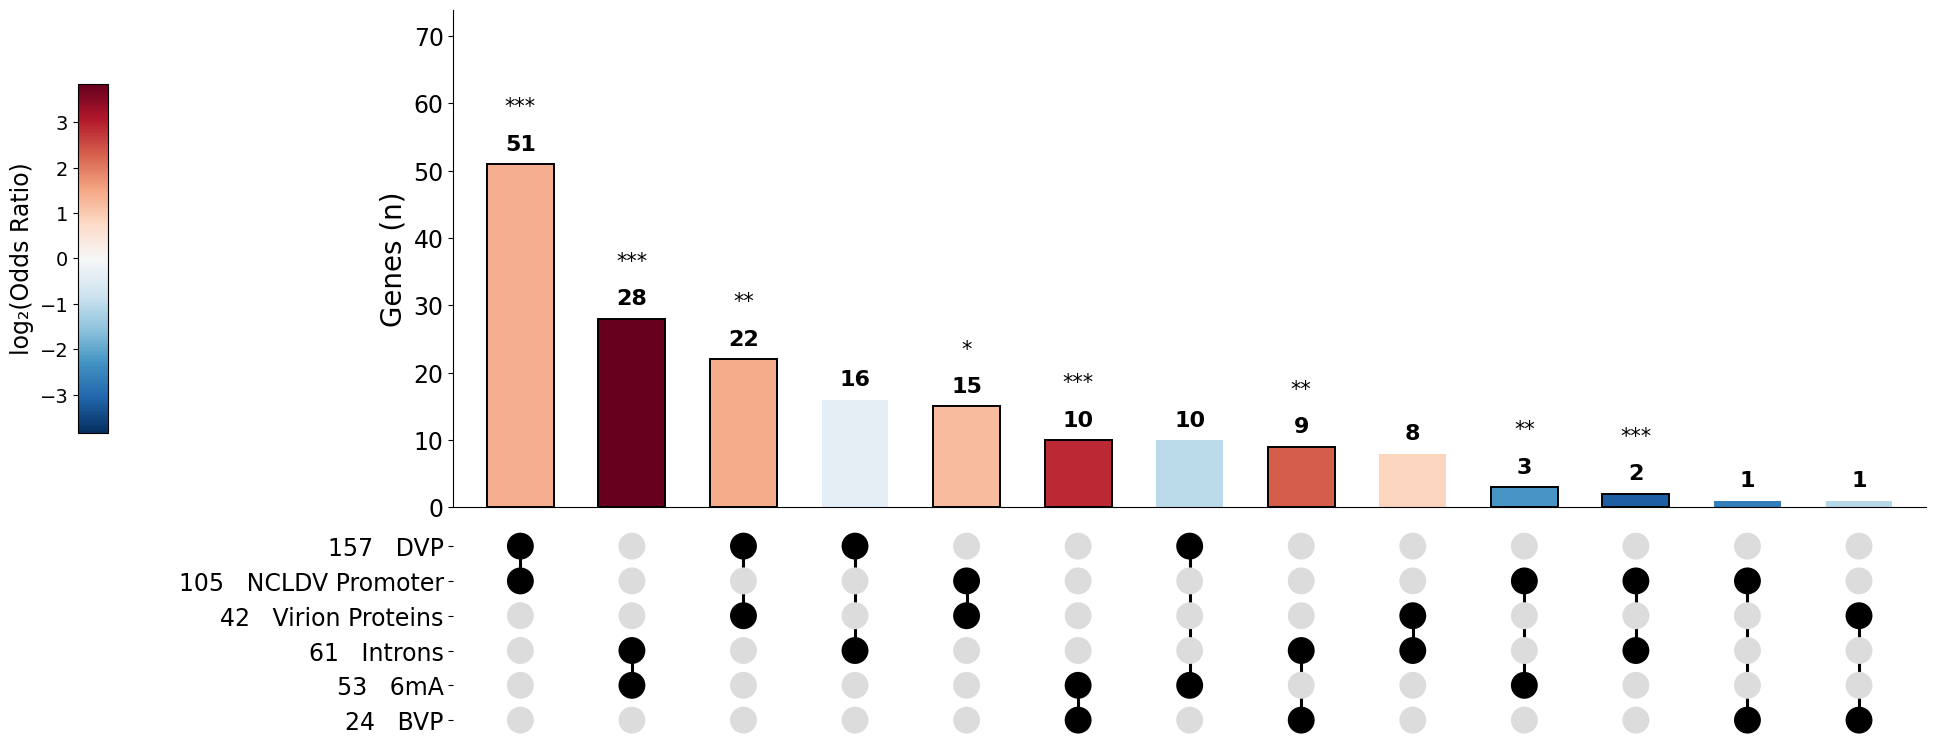

Figure S2 saved: FigS2_feature_cooccurrence_upset.png/.pdf/.svg (bars = inclusive n(A & B), sorted by descending count)


In [4]:
# -- PLOT: Figure S2 -- pairwise feature co-occurrence (UpSet-style bar + dot-matrix), colored by OR/q --
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Row order (bottom -> top); matches the previous UpSet plot's custom row order
UPSET_LABELS = ['BVP', '6mA', 'Introns', 'Virion Proteins', 'NCLDV Promoter', 'DVP']
UPSET_COLS   = ['is_BVP', 'has_6mA', 'has_introns', 'has_virion_prot', 'has_ncldv', 'is_DVP']
_up_label_to_idx = {lbl.replace('\n', ' '): k for k, lbl in enumerate(feat_labels)}
totals = {lbl: int(gdf_s[col].sum()) for lbl, col in zip(UPSET_LABELS, UPSET_COLS)}
row_y = {lbl: k for k, lbl in enumerate(UPSET_LABELS)}

# Bars show the INCLUSIVE co-occurrence count n(A & B) -- same quantity as
# Supplementary Table 5 / the Fisher's-exact OR & q -- not the exclusive
# (pair-only, no other feature) UpSet-partition count used previously.
pairs = []
for (i, j), (or_, p, fdr, (n11, n10, n01, n00)) in pair_stats_f.items():
    la = feat_labels[i].replace('\n', ' ')
    lb = feat_labels[j].replace('\n', ' ')
    if n11 == 0:
        continue
    pairs.append((la, lb, n11, fdr))
pairs.sort(key=lambda x: -x[2])

ncols = len(pairs)
nrows = len(UPSET_LABELS)

up_vmax = np.nanmax(np.abs(OR_mat[OR_mat > -9]))
up_norm = TwoSlopeNorm(vmin=-up_vmax, vcenter=0, vmax=up_vmax)
up_cmap = plt.cm.RdBu_r

with plt.rc_context({'font.size': 20}):
    fig = plt.figure(figsize=(19, 9.5))
    gs = fig.add_gridspec(2, 1, height_ratios=[3, 1.3], hspace=0.05)
    ax_i = fig.add_subplot(gs[0])
    ax_m = fig.add_subplot(gs[1], sharex=ax_i)

    max_h = max(p[2] for p in pairs)
    ax_i.set_ylim(0, max_h * 1.45)
    y0 = ax_i.get_ylim()[1]

    for c, (la, lb, n11, fdr) in enumerate(pairs):
        i, j = _up_label_to_idx[la], _up_label_to_idx[lb]
        log2or = OR_mat[i, j]
        cv = max(log2or, -up_vmax) if not np.isnan(log2or) else 0.0
        color = up_cmap(up_norm(cv))
        q_val = p_mat[i, j]

        ax_i.bar(c, n11, width=0.6, color=color,
                 edgecolor='black' if q_val < 0.05 else 'none', linewidth=1.4)
        ax_i.text(c, n11 + y0 * 0.020, f'{n11}', ha='center', va='bottom',
                   fontsize=16, fontweight='bold')
        stars = fdr_stars(q_val)
        stars = '' if stars == 'ns' else stars
        if stars:
            ax_i.text(c, n11 + y0 * 0.095, stars, ha='center', va='bottom', fontsize=15)

        active_rows = {row_y[la], row_y[lb]}
        for r in range(nrows):
            is_active = r in active_rows
            ax_m.scatter(c, r, s=75 * 5, color='black' if is_active else '#dcdcdc',
                         zorder=3, edgecolor='none')
        r1, r2 = sorted(active_rows)
        ax_m.plot([c, c], [r1, r2], color='black', linewidth=2.2, zorder=2)

    ax_i.set_xlim(-0.6, ncols - 0.4)
    ax_i.set_xticks([])
    ax_i.set_ylabel('Genes (n)', fontsize=20)
    ax_i.tick_params(axis='y', labelsize=17)
    for spine in ['top', 'right']:
        ax_i.spines[spine].set_visible(False)

    ax_m.set_xlim(-0.6, ncols - 0.4)
    ax_m.set_ylim(-0.6, nrows - 0.4)
    ax_m.set_yticks(range(nrows))
    ax_m.set_yticklabels([f'{totals[lbl]}   {lbl}' for lbl in UPSET_LABELS], fontsize=17)
    ax_m.set_xticks([])
    for spine in ax_m.spines.values():
        spine.set_visible(False)

    sm_up = plt.cm.ScalarMappable(cmap=up_cmap, norm=up_norm)
    sm_up.set_array([])
    fig.canvas.draw()
    pos_i = ax_i.get_position()
    renderer = fig.canvas.get_renderer()
    left_extent = pos_i.x0
    for artist in [ax_m.yaxis.label] + ax_m.get_yticklabels():
        bbox = artist.get_window_extent(renderer=renderer)
        bbox_fig = bbox.transformed(fig.transFigure.inverted())
        left_extent = min(left_extent, bbox_fig.x0)

    cax_h = pos_i.height * 0.7
    cax_y0 = pos_i.y0 + (pos_i.height - cax_h) / 2
    cax_up = fig.add_axes([left_extent - 0.05, cax_y0, 0.016, cax_h])
    cbar_up = fig.colorbar(sm_up, cax=cax_up)
    cbar_up.set_label('log₂(Odds Ratio)', fontsize=17)
    cbar_up.ax.tick_params(labelsize=14)
    cbar_up.ax.yaxis.set_label_position('left')
    cbar_up.ax.yaxis.set_ticks_position('left')

    fig.savefig(FIG_DIR / 'FigS2_feature_cooccurrence_upset.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIG_DIR / 'FigS2_feature_cooccurrence_upset.pdf', bbox_inches='tight')
    fig.savefig(FIG_DIR / 'FigS2_feature_cooccurrence_upset.svg', bbox_inches='tight')

plt.show()
print('Figure S2 saved: FigS2_feature_cooccurrence_upset.png/.pdf/.svg (bars = inclusive n(A & B), sorted by descending count)')


## Supplementary Table 5. Pairwise Fisher's exact test statistics for co-occurrence of six binary GEVE genomic features

The Fisher test results behind Figure S2.

**Source**: `GEVE_manuscript_figures.ipynb`

**File**: `tables/TableS5_pairwise_feature_cooccurrence.csv`


In [5]:
# -- TABLE: Supplementary Table 5 -- Pairwise co-occurrence statistics --
import pandas as pd

rows = []
for (i, j), (or_val, pval, fdr, (n11, n10, n01, n00)) in pair_stats_f.items():
    fa = feat_labels[i].replace('\n', ' ')
    fb = feat_labels[j].replace('\n', ' ')
    rows.append({
        'Feature A':      fa,
        'Feature B':      fb,
        'n(A & B)':       n11,
        'n(A only)':      n10,
        'n(B only)':      n01,
        'n(neither)':     n00,
        'Odds Ratio':     or_val,
        'p-value':        pval,
        'q-value (BH)':   fdr,
        'Significant':    fdr < 0.05,
    })

supp_tbl1 = pd.DataFrame(rows).sort_values('q-value (BH)').reset_index(drop=True)
supp_tbl1.to_csv(TABLE_DIR / 'TableS5_pairwise_feature_cooccurrence.csv', index=False)
display(supp_tbl1.round({'Odds Ratio': 3}))
print('Table S5 saved: tables/TableS5_pairwise_feature_cooccurrence.csv')


,Feature A,Feature B,n(A & B),n(A only),n(B only),n(neither),Odds Ratio,p-value,q-value (BH),Significant
0,6mA,Introns,28,25,33,420,14.255,3.712948e-15,5.198127e-14,True
1,DVP,NCLDV Promoter,51,106,54,295,2.628,2.750863e-05,1.925604e-04,True
2,BVP,6mA,10,14,43,439,7.292,4.333988e-05,2.022528e-04,True
3,Introns,NCLDV Promoter,2,59,103,342,0.113,7.378127e-05,2.582345e-04,True
4,BVP,Introns,9,15,52,430,4.962,9.154002e-04,2.563121e-03,True
5,6mA,NCLDV Promoter,3,50,102,351,0.206,2.229162e-03,5.201377e-03,True
6,DVP,Virion Proteins,22,135,20,329,2.681,2.798515e-03,5.597029e-03,True
7,6mA,Virion Proteins,0,53,42,411,0.000,1.493255e-02,2.613197e-02,True
8,NCLDV Promoter,Virion Proteins,15,90,27,374,2.309,1.707350e-02,2.655877e-02,True
9,DVP,6mA,10,147,43,306,0.484,4.273513e-02,5.439016e-02,False


Table S5 saved: tables/TableS5_pairwise_feature_cooccurrence.csv


## Appendix Figure 6. Data-driven definition of cell-state boundaries from the GEVE UMI distribution

Fits a log-normal to per-cell GEVE UMIs in cells with GEVE > 4. The High-GEVE threshold is μ + 3σ (≈ 43 UMIs).

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig6_cell_state_thresholds.png`, `.pdf`, `.svg`


In [6]:
# -- COMPUTE: log-normal threshold model for GEVE cell-state boundaries (Appendix Figure 6) --
import numpy as np
import scanpy as sc
from pathlib import Path
from scipy.stats import norm as _norm

FIG_DIR.mkdir(exist_ok=True)

_adata_tmp = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
geve_sf4   = _adata_tmp.obs['geve_raw'].values.copy()
del _adata_tmp

# Fit log-normal to GEVE > 4 cells (above the noise floor)
g_fit_sf4     = geve_sf4[geve_sf4 > 4]
log_g_fit_sf4 = np.log10(g_fit_sf4)
LOGNORM_MU_SF4    = log_g_fit_sf4.mean()
LOGNORM_SIGMA_SF4 = log_g_fit_sf4.std()

print(f"Log-normal fit  (GEVE>4, n={len(g_fit_sf4)})")
print(f"  mu    (log10) = {LOGNORM_MU_SF4:.4f}  ->  geometric mean = {10**LOGNORM_MU_SF4:.1f} UMIs")
print(f"  sigma (log10) = {LOGNORM_SIGMA_SF4:.4f}  ->  geometric SD factor = {10**LOGNORM_SIGMA_SF4:.2f}x")
print()

# Threshold sensitivity table
print(f"{'N_SIGMA':>8}  {'Threshold (UMIs)':>16}  {'n High-GEVE':>11}  {'p-value':>10}")
for n in [2.0, 2.5, 3.0, 3.3, 3.5]:
    t   = 10 ** (LOGNORM_MU_SF4 + n * LOGNORM_SIGMA_SF4)
    nv  = (geve_sf4 >= t).sum()
    p   = 1 - _norm.cdf(n)
    note = '  <- current manual' if abs(n - 3.3) < 0.05 else ''
    print(f"  {n:>6.1f}  {t:>16.1f}  {nv:>11}  {p:>10.4f}{note}")

# Selected thresholds (N_SIGMA = 3.0, matching module 07 defaults)
N_SIGMA_SF4        = 3.0
DERIVED_VIRO_SF4   = 10 ** (LOGNORM_MU_SF4 + N_SIGMA_SF4 * LOGNORM_SIGMA_SF4)
DERIVED_PRO_MIN_SF4 = 10  # fixed threshold (matches Virocell/Active GEVE Expressing Cell lower bound)
# Integer cell-state bounds used by every downstream cell (UMI counts are integers):
#   GEVE_MIN: Active GEVE Expressing Cells / latent GEVE / Virocell lower bound  -> GEVE UMIs >= 10
#   HG_MIN  : High-GEVE lower bound = ceil(mu + 3 sigma)          -> GEVE UMIs >= 43
GEVE_MIN = DERIVED_PRO_MIN_SF4
HG_MIN   = int(np.ceil(DERIVED_VIRO_SF4))

print(f"\n-- Selected N_SIGMA = {N_SIGMA_SF4} --")
print(f"  Active GEVE Expressing Cell lower bound (fixed):  {DERIVED_PRO_MIN_SF4} UMIs")
print(f"  Active GEVE Expressing Cell / High-GEVE boundary:     {DERIVED_VIRO_SF4:.1f} UMIs  "
      f"(mu + {N_SIGMA_SF4}sigma,  p = {1-_norm.cdf(N_SIGMA_SF4):.4f})")
print(f"  n Active GEVE Expressing Cells: {((geve_sf4 >= DERIVED_PRO_MIN_SF4) & (geve_sf4 < DERIVED_VIRO_SF4)).sum()}")
print(f"  n High-GEVE:     {(geve_sf4 >= DERIVED_VIRO_SF4).sum()}")
print(f"  Integer bounds: GEVE_MIN = {GEVE_MIN} (>=), HG_MIN = {HG_MIN} (>=)")


Log-normal fit  (GEVE>4, n=4688)
  mu    (log10) = 0.9469  ->  geometric mean = 8.8 UMIs
  sigma (log10) = 0.2272  ->  geometric SD factor = 1.69x

 N_SIGMA  Threshold (UMIs)  n High-GEVE     p-value
     2.0              25.2          205      0.0228
     2.5              32.7          114      0.0062
     3.0              42.5           39      0.0013
     3.3              49.7           24      0.0005  <- current manual
     3.5              55.2           21      0.0002

-- Selected N_SIGMA = 3.0 --
  Active GEVE Expressing Cell lower bound (fixed):  10 UMIs
  Active GEVE Expressing Cell / High-GEVE boundary:     42.5 UMIs  (mu + 3.0sigma,  p = 0.0013)
  n Active GEVE Expressing Cells: 1696
  n High-GEVE:     39
  Integer bounds: GEVE_MIN = 10 (>=), HG_MIN = 43 (>=)


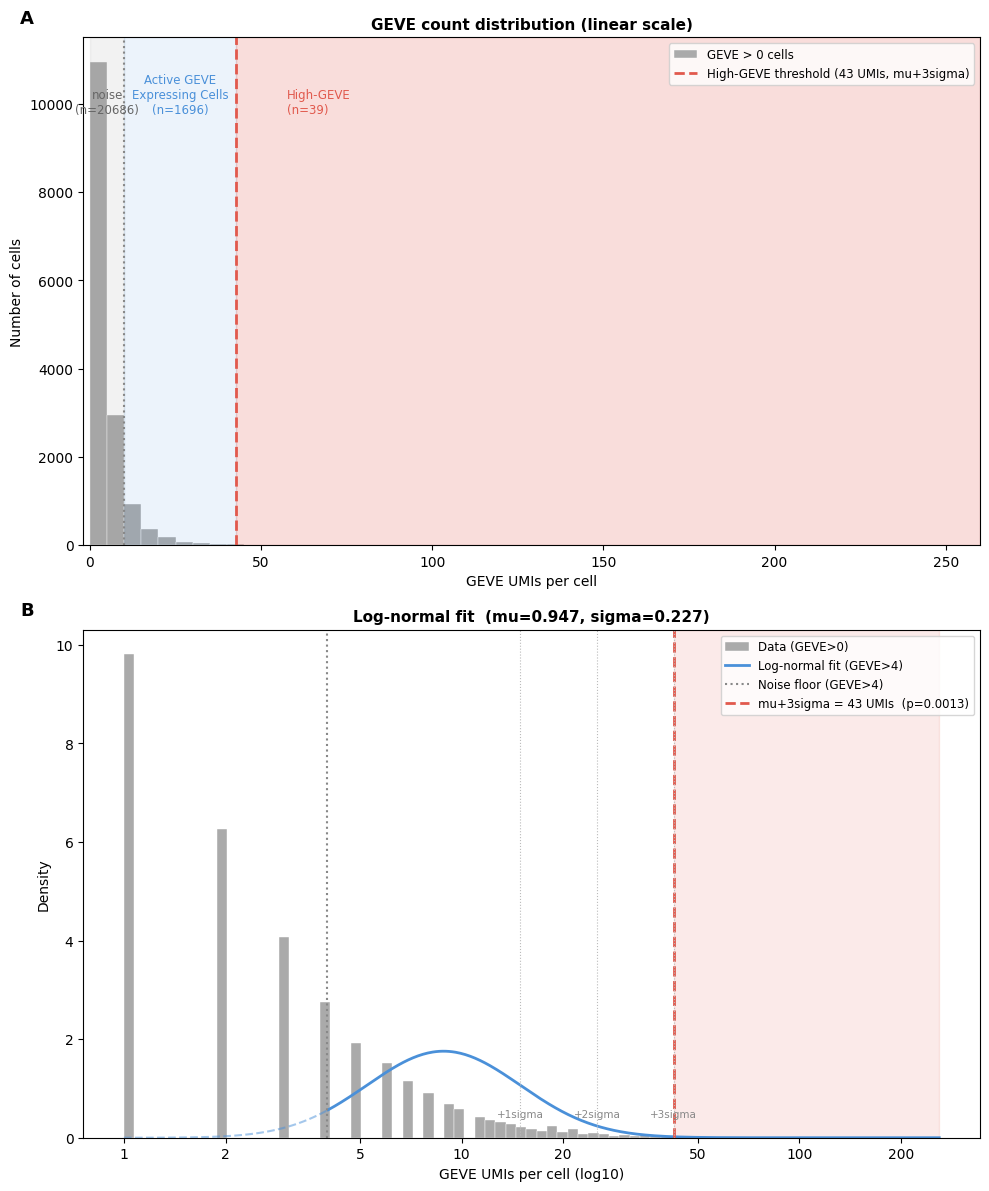

Appendix Figure 6 saved.


In [7]:
# -- PLOT: Appendix Figure 6 -- GEVE distribution + log-normal fit + thresholds --
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm as _norm

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))

# Panel A -- linear scale, full distribution
bins_lin = np.arange(0, 260, 5)
ax1.hist(geve_sf4[geve_sf4 > 0], bins=bins_lin,
         color='#aaaaaa', edgecolor='white', linewidth=0.3, label='GEVE > 0 cells')

ax1.axvspan(0,                  DERIVED_PRO_MIN_SF4, alpha=0.10, color='#888888')
ax1.axvspan(DERIVED_PRO_MIN_SF4, DERIVED_VIRO_SF4,   alpha=0.10, color='#4a90d9')
ax1.axvspan(DERIVED_VIRO_SF4,    260,                alpha=0.20, color='#e1594d')

ax1.axvline(DERIVED_PRO_MIN_SF4, color='#888888', lw=1.5, linestyle=':')
ax1.axvline(DERIVED_VIRO_SF4,    color='#e1594d', lw=2,   linestyle='--',
            label=f'High-GEVE threshold ({DERIVED_VIRO_SF4:.0f} UMIs, '
                  f'mu+{N_SIGMA_SF4:.0f}sigma)')

ax1.set_xlabel('GEVE UMIs per cell', fontsize=10)
ax1.set_ylabel('Number of cells', fontsize=10)
ax1.set_title('GEVE count distribution (linear scale)', fontsize=11, fontweight='bold')
ax1.set_xlim(-2, 260)
ax1.legend(fontsize=8.5)

n_noise_sf4 = (geve_sf4  < DERIVED_PRO_MIN_SF4).sum()
n_pro_sf4   = ((geve_sf4 >= DERIVED_PRO_MIN_SF4) & (geve_sf4 < DERIVED_VIRO_SF4)).sum()
n_viro_sf4  = (geve_sf4  >= DERIVED_VIRO_SF4).sum()
ylim1 = ax1.get_ylim()[1]
ax1.text(DERIVED_PRO_MIN_SF4 / 2,
         ylim1 * 0.85, f'noise\n(n={n_noise_sf4})',    ha='center', fontsize=8.5, color='#666666')
ax1.text((DERIVED_PRO_MIN_SF4 + DERIVED_VIRO_SF4) / 2,
         ylim1 * 0.85, f'Active GEVE\nExpressing Cells\n(n={n_pro_sf4})',  ha='center', fontsize=8.5, color='#4a90d9')
ax1.text(DERIVED_VIRO_SF4 + 15,
         ylim1 * 0.85, f'High-GEVE\n(n={n_viro_sf4})',    ha='left',   fontsize=8.5, color='#e1594d')

# Panel B -- log10 scale + log-normal fit
g_pos_sf4 = geve_sf4[geve_sf4 > 0]
log_bins  = np.linspace(0, np.log10(260), 80)
ax2.hist(np.log10(g_pos_sf4), bins=log_bins,
         color='#aaaaaa', edgecolor='white', linewidth=0.3, density=True, label='Data (GEVE>0)')

x_fit    = np.linspace(log_bins[0], log_bins[-1], 500)
pdf_fit  = _norm.pdf(x_fit, LOGNORM_MU_SF4, LOGNORM_SIGMA_SF4)
mask_fit = x_fit >= np.log10(4)
ax2.plot(x_fit[mask_fit],  pdf_fit[mask_fit],  color='#4a90d9', lw=2,
         label='Log-normal fit (GEVE>4)')
ax2.plot(x_fit[~mask_fit], pdf_fit[~mask_fit], color='#4a90d9', lw=1.5,
         linestyle='--', alpha=0.5)

ax2.axvline(np.log10(4),                color='#888888', lw=1.5, linestyle=':',
            label='Noise floor (GEVE>4)')
ax2.axvline(np.log10(DERIVED_VIRO_SF4), color='#e1594d', lw=2,   linestyle='--',
            label=f'mu+{N_SIGMA_SF4:.0f}sigma = {DERIVED_VIRO_SF4:.0f} UMIs  '
                  f'(p={1-_norm.cdf(N_SIGMA_SF4):.4f})')
ax2.axvspan(np.log10(DERIVED_VIRO_SF4), log_bins[-1], alpha=0.12, color='#e1594d')

ax2.legend(fontsize=8.5, loc='upper right')

# sigma rulers (added after legend so ylim is stable)
ylim2 = ax2.get_ylim()[1]
for n in [1, 2, 3]:
    xv = LOGNORM_MU_SF4 + n * LOGNORM_SIGMA_SF4
    if log_bins[0] < xv < log_bins[-1]:
        ax2.axvline(xv, color='#bbbbbb', lw=0.8, linestyle=':')
        ax2.text(xv, ylim2 * 0.04 if ylim2 > 0 else 0.05,
                 f'+{n}sigma', ha='center', fontsize=7.5, color='#888888')

xtick_vals = [1, 2, 5, 10, 20, 50, 100, 200]
ax2.set_xticks([np.log10(v) for v in xtick_vals])
ax2.set_xticklabels([str(v) for v in xtick_vals])
ax2.set_xlabel('GEVE UMIs per cell (log10)', fontsize=10)
ax2.set_ylabel('Density', fontsize=10)
ax2.set_title(f'Log-normal fit  (mu={LOGNORM_MU_SF4:.3f}, sigma={LOGNORM_SIGMA_SF4:.3f})',
              fontsize=11, fontweight='bold')

# Panel labels
ax1.text(-0.07, 1.02, 'A', transform=ax1.transAxes, fontsize=13, fontweight='bold',
         va='bottom', ha='left')
ax2.text(-0.07, 1.02, 'B', transform=ax2.transAxes, fontsize=13, fontweight='bold',
         va='bottom', ha='left')

plt.tight_layout()
plt.savefig(FIG_DIR / 'AppFig6_cell_state_thresholds.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig6_cell_state_thresholds.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig6_cell_state_thresholds.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 6 saved.')


## Appendix Figure 7. Median library depth per biological sample across DPI 4–7

Median library depth per sample, DPI and GEVE tier. It checks that High-GEVE calls are not a depth artifact.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig7_library_depth_per_sample.png`, `.pdf`, `.svg`


In [8]:
# -- COMPUTE: Per-sample median library depth (Appendix Figure 7) --
import numpy as np
import pandas as pd
import scanpy as sc
from pathlib import Path

_adata_sf4 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
_obs_sf4   = _adata_sf4.obs[['sample','total_counts']].copy()
del _adata_sf4

_sample_dpi = {
    's4A': (4,'A'), 's4B': (4,'B'),
    's3A': (5,'A'), 's3B': (5,'B'),
    's2A': (6,'A'), 's2B': (6,'B'),
    's1A': (7,'A'), 's1B': (7,'B'),
}
_sample_order_sf4 = ['s4A','s4B','s3A','s3B','s2A','s2B','s1A','s1B']

_stats_sf4 = (
    _obs_sf4.groupby('sample', observed=True)
    ['total_counts'].median()
    .loc[_sample_order_sf4]
    .reset_index()
)
_stats_sf4.columns = ['sample','median_umi']
_stats_sf4['dpi']   = [_sample_dpi[s][0] for s in _stats_sf4['sample']]
_stats_sf4['rep']   = [_sample_dpi[s][1] for s in _stats_sf4['sample']]
_stats_sf4['label'] = [f'DPI {d}\nrep {r}' for d, r in zip(_stats_sf4['dpi'], _stats_sf4['rep'])]

print(_stats_sf4[['sample','label','median_umi']].to_string(index=False))


sample        label  median_umi
   s4A DPI 4\nrep A      1222.0
   s4B DPI 4\nrep B      1525.0
   s3A DPI 5\nrep A       502.5
   s3B DPI 5\nrep B       339.0
   s2A DPI 6\nrep A       327.0
   s2B DPI 6\nrep B       336.0
   s1A DPI 7\nrep A       112.0
   s1B DPI 7\nrep B       166.0


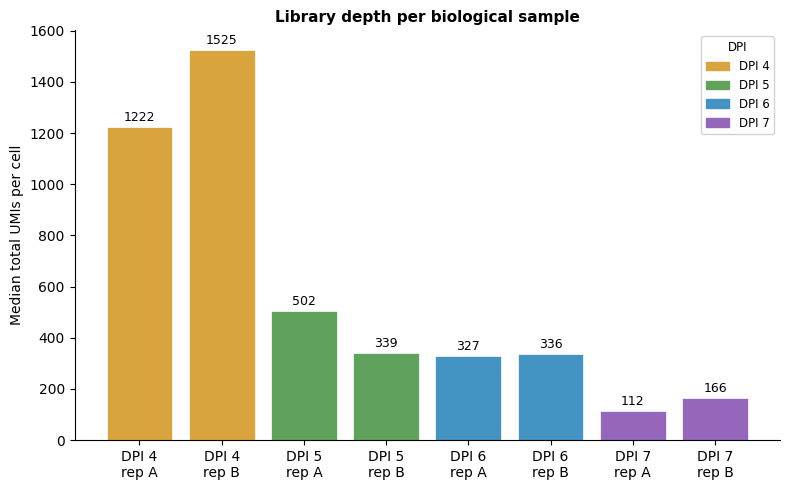

Appendix Figure 7 saved.


In [9]:
# -- PLOT: Appendix Figure 7 -- Per-sample median library depth --
import matplotlib.pyplot as plt
import numpy as np

DPI_COLORS_SF4 = {4: '#d9a33e', 5: '#5fa25c', 6: '#4393c3', 7: '#9467bd'}

fig, ax = plt.subplots(figsize=(8, 5))

x      = np.arange(len(_stats_sf4))
colors = [DPI_COLORS_SF4[d] for d in _stats_sf4['dpi']]
bars   = ax.bar(x, _stats_sf4['median_umi'], color=colors, edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, _stats_sf4['median_umi']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 12,
            f'{int(val)}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(_stats_sf4['label'], fontsize=10)
ax.set_ylabel('Median total UMIs per cell', fontsize=10)
ax.set_title('Library depth per biological sample', fontweight='bold', fontsize=11)
ax.spines[['top','right']].set_visible(False)

import matplotlib.patches as mpatches
handles_sf4 = [mpatches.Patch(color=color, label=f'DPI {dpi}') for dpi, color in DPI_COLORS_SF4.items()]
ax.legend(handles=handles_sf4, title='DPI', fontsize=8.5, title_fontsize=8.5, framealpha=0.85, loc='upper right')

plt.tight_layout()
plt.savefig(FIG_DIR / 'AppFig7_library_depth_per_sample.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig7_library_depth_per_sample.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig7_library_depth_per_sample.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 7 saved.')


## Appendix Figure 8. Single-cell GEVE transcriptomes mapped onto the viral genome for Active GEVE Expressing Cells and High-GEVE cells

Per-cell GEVE gene detection plotted along the GEVE genome for representative cells.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig8_single_cell_GEVE_genome_map.png`, `.pdf`, `.svg`


In [10]:
# -- COMPUTE: GEVE genome track -- cell groups and expression matrices (Appendix Figure 8) --
import numpy as np
import scanpy as sc
from pathlib import Path

FIG_DIR.mkdir(exist_ok=True)

# TIR coordinates (bp) — same as Fig 1 compute cell
TIR1_START, TIR1_END = 2_023_526, 2_038_329
TIR2_START, TIR2_END = 2_629_749, 2_640_528

n_genes_sf5  = len(gdf_track)
coding_span  = gdf_track['end'].max() - gdf_track['start'].min()
bp_per_unit  = coding_span / n_genes_sf5
tir1_units_sf5 = (TIR1_END - TIR1_START) / bp_per_unit
tir2_units_sf5 = (TIR2_END - TIR2_START) / bp_per_unit

# Cell-state thresholds
# PRO_MIN: lower bound for latent GEVE cells (conservative margin above noise floor)
# VIRO_MIN: data-driven High-GEVE boundary from Appendix Fig 6 log-normal fit
PRO_MIN_SF5  = GEVE_MIN   # >= 10
VIRO_MIN_SF5 = HG_MIN     # >= 43 (from the threshold compute cell)

# Load adata and define cell groups
_adata_sf5 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')

pro_mask_sf5  = ((_adata_sf5.obs['geve_raw'] >= PRO_MIN_SF5) &
                  (_adata_sf5.obs['geve_raw'] <  VIRO_MIN_SF5))
viro_mask_sf5 =   _adata_sf5.obs['geve_raw'] >= VIRO_MIN_SF5

pro_adata_sf5  = _adata_sf5[pro_mask_sf5].copy()
viro_adata_sf5 = _adata_sf5[viro_mask_sf5].copy()
del _adata_sf5

# Sort cells by GEVE load (descending) so densest expressors are at the top
pro_adata_sf5  = pro_adata_sf5[
    pro_adata_sf5.obs['geve_raw'].sort_values(ascending=False).index]
viro_adata_sf5 = viro_adata_sf5[
    viro_adata_sf5.obs['geve_raw'].sort_values(ascending=False).index]

n_pro_sf5  = pro_adata_sf5.n_obs
n_viro_sf5 = viro_adata_sf5.n_obs
print(f'Active GEVE Expressing Cells  ({PRO_MIN_SF5}-{VIRO_MIN_SF5-1} UMIs):  n={n_pro_sf5}')
print(f'Virocells     (>={VIRO_MIN_SF5} UMIs):          n={n_viro_sf5}')

# Expression matrices restricted to the 506 GEVE genes in gdf_track
gdf_genes_sf5  = gdf_track['gene'].tolist()
expr_pro_sf5   = pro_adata_sf5[:,  gdf_genes_sf5].X
expr_viro_sf5  = viro_adata_sf5[:, gdf_genes_sf5].X
if hasattr(expr_pro_sf5,  'toarray'): expr_pro_sf5  = expr_pro_sf5.toarray()
if hasattr(expr_viro_sf5, 'toarray'): expr_viro_sf5 = expr_viro_sf5.toarray()
del pro_adata_sf5, viro_adata_sf5

print('Expression matrices ready.')


Active GEVE Expressing Cells  (10-42 UMIs):  n=1696
Virocells     (>=43 UMIs):          n=39
Expression matrices ready.


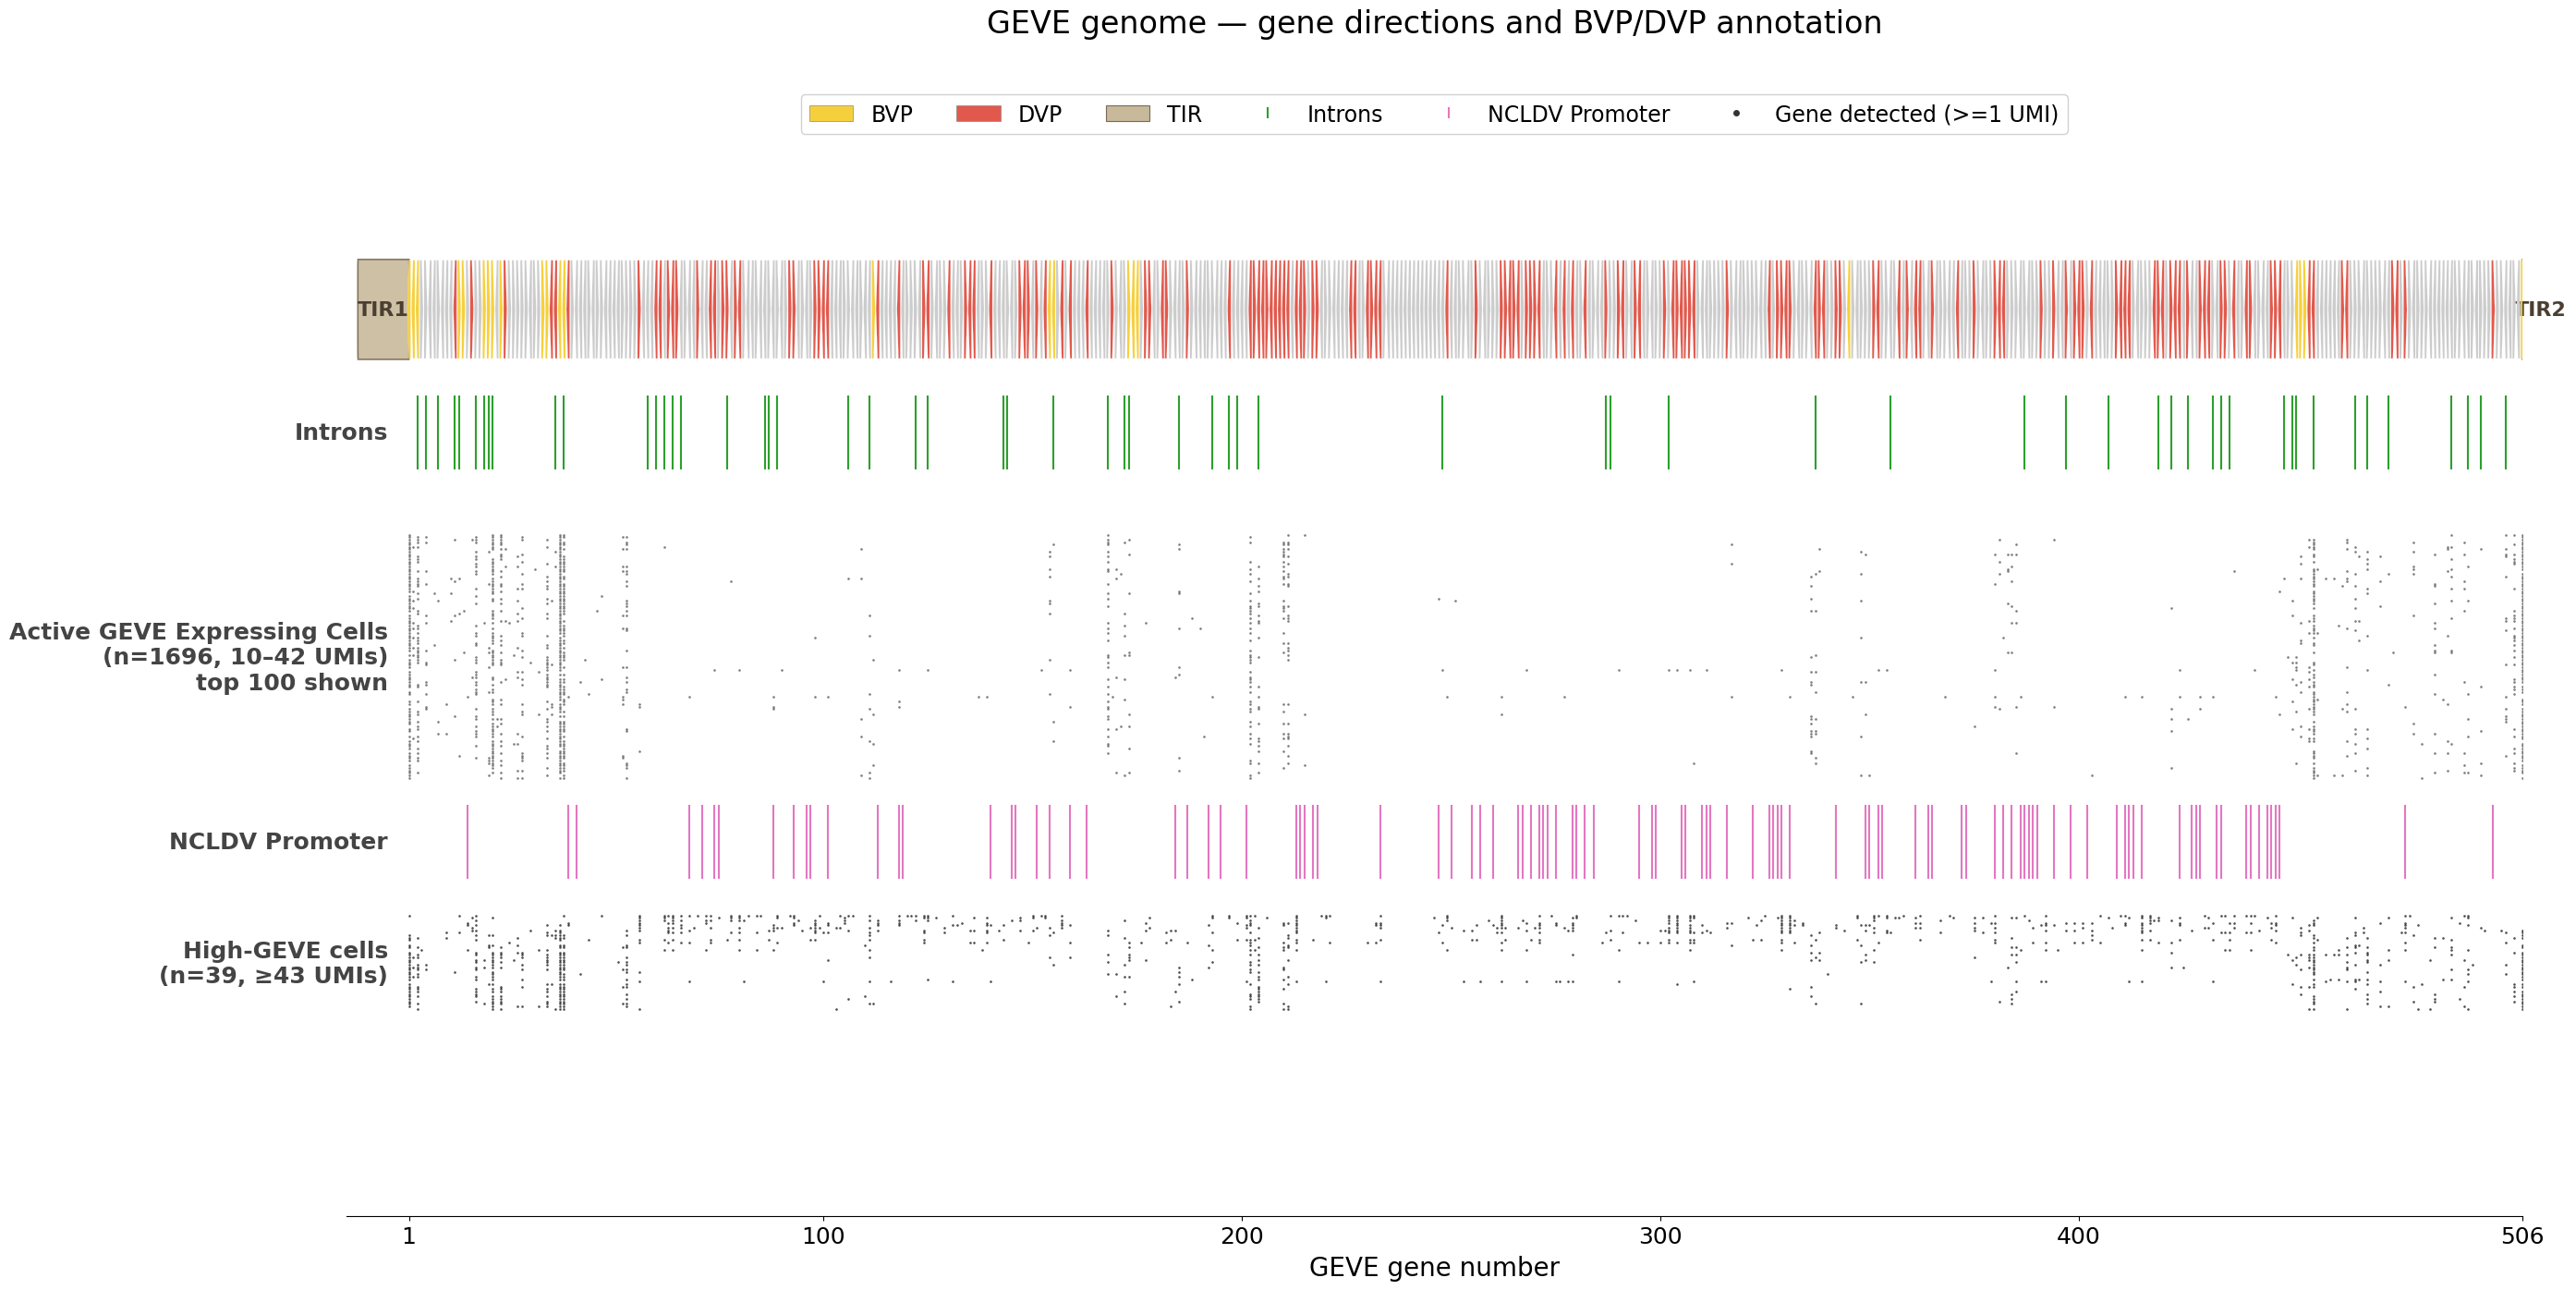

Appendix Figure 8 saved.


In [11]:
# -- PLOT: Appendix Figure 8 -- GEVE genome track (introns + NCLDV prom. only) --
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import numpy as np
from matplotlib.patches import Polygon

BVP_COLOR_SF5      = '#F6D03C'
DVP_COLOR_SF5      = '#E1594D'
UNC_COLOR_SF5      = '#cccccc'
TIR_COLOR_SF5      = '#c8b99a'
INTRON_COLOR_SF5   = '#2ca02c'
NCLDV_PROM_COLOR_SF5 = '#e377c2'
LOW_COLOR_SF5      = '#444444'   # latent GEVE cell dots
TOP_COLOR_SF5      = '#000000'   # virocell dots

GENE_W    = 0.8
GENE_H    = 0.12
ARROW_LEN = 0.4
TRACK_H   = 0.18
CELL_GAP  = 0.006
N_PRO_SHOWN = 100

# Y-positions: only Introns track above the cell bands (6mA/mCG/Dual removed)
INTRON_Y       = -0.30
LOW_Y_TOP      = -0.55                                     # Active GEVE Expressing Cell band start
NCLDV_PROM_Y   = LOW_Y_TOP - N_PRO_SHOWN * CELL_GAP - 0.15  # Between the two cell bands
TOP_Y_TOP      = NCLDV_PROM_Y - 0.18                      # Virocells band start

# WIDE tier font scale (matches Fig 1 / cell bd5e064b for this figsize class)
FS_TITLE_W, FS_AX_W, FS_TICK_W, FS_LEG_W, FS_LABEL_W, FS_TIR_W = 24, 20, 18, 17, 18, 16

fig, ax = plt.subplots(figsize=(28, 14))

x_min = 1
x_max = n_genes_sf5

# TIR blocks
for x0, width, label in [
    (1 - tir1_units_sf5, tir1_units_sf5, 'TIR1'),
    (n_genes_sf5, tir2_units_sf5, 'TIR2')
]:
    ax.add_patch(mpatches.FancyBboxPatch(
        (x0, -GENE_H * 0.6), width, GENE_H * 1.2,
        boxstyle='round,pad=0.05', fc=TIR_COLOR_SF5, ec='#7a6a55',
        lw=1.2, zorder=1, alpha=0.9))
    ax.text(x0 + width / 2, 0, label, ha='center', va='center',
            fontsize=FS_TIR_W, fontweight='bold', color='#4a3f30', zorder=2)

# Gene arrows + Introns + NCLDV Prom. feature tracks
for idx, row in gdf_track.iterrows():
    i      = row['gene_num']
    color  = row['color']
    strand = row['strand']
    x0 = i - GENE_W / 2
    x1 = i + GENE_W / 2
    yw = GENE_H
    al = min(ARROW_LEN, GENE_W * 0.45)
    if strand == '+':
        pts = [(x0, -yw), (x1-al, -yw), (x1, 0), (x1-al, yw), (x0, yw)]
    else:
        pts = [(x1, -yw), (x0+al, -yw), (x0, 0), (x0+al, yw), (x1, yw)]
    ax.add_patch(Polygon(pts, closed=True, fc=color, ec='white', lw=0.12, zorder=3))
    if row['has_introns']:
        ax.vlines(i, INTRON_Y - TRACK_H/2, INTRON_Y + TRACK_H/2,
                  color=INTRON_COLOR_SF5, lw=1.5, zorder=4)
    if row['has_late_prom']:
        ax.vlines(i, NCLDV_PROM_Y - TRACK_H/2, NCLDV_PROM_Y + TRACK_H/2,
                  color=NCLDV_PROM_COLOR_SF5, lw=1.5, zorder=4)

# Active GEVE Expressing Cell expression dots
for cell_idx in range(N_PRO_SHOWN):
    y  = LOW_Y_TOP - cell_idx * CELL_GAP
    nz = np.where(expr_pro_sf5[cell_idx] > 0)[0]
    if len(nz) > 0:
        ax.scatter(nz + 1, [y] * len(nz),
                   s=3.5, color=LOW_COLOR_SF5, alpha=0.7, marker='o', lw=0)

# Virocells expression dots
for cell_idx in range(expr_viro_sf5.shape[0]):
    y  = TOP_Y_TOP - cell_idx * CELL_GAP
    nz = np.where(expr_viro_sf5[cell_idx] > 0)[0]
    if len(nz) > 0:
        ax.scatter(nz + 1, [y] * len(nz),
                   s=3.5, color=TOP_COLOR_SF5, alpha=0.7, marker='o', lw=0)

# Y-axis labels
label_x = x_min - 5
ax.text(label_x, INTRON_Y,
        'Introns', ha='right', va='center',
        fontsize=FS_LABEL_W, fontweight='bold', color='#444444')
ax.text(label_x, LOW_Y_TOP - N_PRO_SHOWN / 2 * CELL_GAP,
        f'Active GEVE Expressing Cells\n(n={n_pro_sf5}, {PRO_MIN_SF5}\u2013{VIRO_MIN_SF5-1} UMIs)\ntop {N_PRO_SHOWN} shown', ha='right', va='center',
        fontsize=FS_LABEL_W, fontweight='bold', color='#444444')
ax.text(label_x, NCLDV_PROM_Y,
        'NCLDV Promoter', ha='right', va='center',
        fontsize=FS_LABEL_W, fontweight='bold', color='#444444')
ax.text(label_x, TOP_Y_TOP - n_viro_sf5 / 2 * CELL_GAP,
        f'High-GEVE cells\n(n={n_viro_sf5}, \u2265{VIRO_MIN_SF5} UMIs)', ha='right', va='center',
        fontsize=FS_LABEL_W, fontweight='bold', color='#444444')

# Axes
ax.set_xlim(x_min - 15, x_max)
ax.set_ylim(
    min(LOW_Y_TOP - N_PRO_SHOWN * CELL_GAP,
        TOP_Y_TOP  - n_viro_sf5 * CELL_GAP) - 0.5, 0.35)
ax.set_yticks([])
ax.set_xlabel('GEVE gene number', fontsize=FS_AX_W, labelpad=6)
ax.set_xticks([1, 100, 200, 300, 400, 506])
ax.set_xticklabels(['1', '100', '200', '300', '400', '506'], fontsize=FS_TICK_W)
for spine in ['left', 'top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_linewidth(0.8)

# Legend
handles_sf5 = [
    mpatches.Patch(fc=BVP_COLOR_SF5,  ec='#888', lw=0.5, label='BVP'),
    mpatches.Patch(fc=DVP_COLOR_SF5,  ec='#888', lw=0.5, label='DVP'),
    mpatches.Patch(fc=TIR_COLOR_SF5,  ec='#7a6a55', lw=0.8, label='TIR'),
    mlines.Line2D([], [], color=INTRON_COLOR_SF5, marker='|', linestyle='None',
                  markersize=8, markeredgewidth=1.5, label='Introns'),
    mlines.Line2D([], [], color=NCLDV_PROM_COLOR_SF5, marker='|', linestyle='None',
                  markersize=8, markeredgewidth=1.5, label='NCLDV Promoter'),
    mlines.Line2D([], [], color='#333333', marker='o', linestyle='None',
                  markersize=4, label='Gene detected (>=1 UMI)'),
]
ax.legend(handles=handles_sf5, loc='lower center', bbox_to_anchor=(0.5, 1.02),
          ncol=6, fontsize=FS_LEG_W, framealpha=0.9, edgecolor='#cccccc')
ax.set_title('GEVE genome — gene directions and BVP/DVP annotation',
             fontsize=FS_TITLE_W, y=1.12)

plt.tight_layout()
plt.savefig(FIG_DIR / 'AppFig8_single_cell_GEVE_genome_map.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig8_single_cell_GEVE_genome_map.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig8_single_cell_GEVE_genome_map.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 8 saved.')


## Appendix Figure 9. Detection-rate comparison of GEVE genes between Active GEVE Expressing Cells and High-GEVE cells

Computes the detection rate of each of the **506 canonical GEVE genes** in Active GEVE Expressing Cells (10–42 UMIs) and High-GEVE cells (≥ 43 UMIs). Genes with log₂FC(detection) ≥ 0.5 and detection ≥ 10% in either group (`degs`) go on to S11. No statistical test is applied, as described in the Methods.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig9_detection_GEVE_active_vs_High_GEVE.png`, `.pdf`, `.svg`


In [12]:
# -- COMPUTE: GEVE most-variable genes -- detection-rate fold-change (Appendix Figure 9) --
# Ranks the 506 canonical GEVE genes (relic loci excluded) by log2 fold-change
# in detection rate between
# Active GEVE Expressing Cells (10-42 UMIs) and High-GEVE (>=43 UMIs) cells.
# No statistical test is applied; detection rate avoids depth-normalization bias.
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path

FIG_DIR.mkdir(exist_ok=True)

PRO_MIN_SF6  = GEVE_MIN   # >= 10
VIRO_MIN_SF6 = HG_MIN     # >= 43

_adata_sf6 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
pro_mask_sf6  = ((_adata_sf6.obs['geve_raw'] >= PRO_MIN_SF6) &
                  (_adata_sf6.obs['geve_raw'] <  VIRO_MIN_SF6))
viro_mask_sf6 =   _adata_sf6.obs['geve_raw'] >= VIRO_MIN_SF6

_canonical_genes_sf6 = set(gdf_track['gene'])   # 506 canonical genes; excludes relic loci
geve_var_mask_sf6 = ((_adata_sf6.var['gene_type'] == 'GEVE') &
                     (_adata_sf6.var_names.isin(_canonical_genes_sf6)))
sub_sf6 = _adata_sf6[pro_mask_sf6 | viro_mask_sf6, geve_var_mask_sf6].copy()
del _adata_sf6

sub_sf6.obs['de_group'] = 'pro'
viro_in_sub = viro_mask_sf6[pro_mask_sf6 | viro_mask_sf6].values
sub_sf6.obs.loc[viro_in_sub, 'de_group'] = 'viro'

group_arr = sub_sf6.obs['de_group'].values
n_pro_de  = (group_arr == 'pro').sum()
n_viro_de = (group_arr == 'viro').sum()
gene_names = sub_sf6.var_names.tolist()

X_raw = sub_sf6.X
if sp.issparse(X_raw): X_raw = X_raw.toarray()
X_pro_raw  = X_raw[group_arr == 'pro']
X_viro_raw = X_raw[group_arr == 'viro']
del sub_sf6

n_expr_pro  = (X_pro_raw  > 0).sum(axis=0)
n_expr_viro = (X_viro_raw > 0).sum(axis=0)
pct_pro     = n_expr_pro  / n_pro_de
pct_viro    = n_expr_viro / n_viro_de
log2fc_det  = np.log2((pct_viro + 0.005) / (pct_pro + 0.005))

de_df = pd.DataFrame({
    'gene'       : gene_names,
    'pct_viro'   : pct_viro,
    'pct_pro'    : pct_pro,
    'log2fc_det' : log2fc_det,
})

# Merge functional annotations from gdf_track (must be in scope from Fig 1 compute)
# Resolve NCLDV promoter column name (stored as 'has_late_prom' in gdf_track)
_prom_col = next((c for c in ['has_ncldv_prom', 'has_late_prom']
                  if c in gdf_track.columns), None)
_track = gdf_track.copy()
if _prom_col == 'has_late_prom':
    _track = _track.rename(columns={'has_late_prom': 'has_ncldv_prom'})

ann_cols = ['cluster', 'has_6mA', 'has_introns', 'has_ncldv_prom', 'has_virion_prot',
            'ncldv_marker', 'pfam_desc', 'gvog']
_avail = [c for c in ann_cols if c in _track.columns]
de_df = de_df.merge(_track[['gene'] + _avail], on='gene', how='left')
for col in ann_cols:
    if col not in de_df.columns:
        de_df[col] = False if col.startswith('has_') else ''

# Assign color labels
import pandas as _pd
def _color_label(row):
    nm = row.get('ncldv_marker', '')
    if _pd.notna(nm) and str(nm).strip() not in ('', 'nan'):               return 'NCLDV marker'
    if row.get('has_ncldv_prom', False):                                    return 'NCLDV promoter'
    if row.get('cluster', '') == 'DVP':                                     return 'DVP'
    if row.get('cluster', '') == 'BVP':                                     return 'BVP'
    if row.get('has_6mA', False):                                           return '6mA-marked'
    return 'Unannotated'
de_df['color_label'] = de_df.apply(_color_label, axis=1)
print('color_label distribution:', de_df['color_label'].value_counts().to_dict())

# Build annotation string for heatmap x-axis labels
def _ann_str(row):
    for src in ['ncldv_marker', 'pfam_desc', 'gvog']:
        v = str(row.get(src, '') or '').strip()
        if v and v != 'nan': return v
    return ''
de_df['ann'] = de_df.apply(_ann_str, axis=1)

# Gene filter for visualization: detectable in at least one group
MIN_PCT = 0.10
MIN_LFC = 0.5
detected_mask = (pct_viro >= MIN_PCT) | (pct_pro >= MIN_PCT)
de_df_detected = de_df[detected_mask].copy()

# Most-variable genes: higher detection in High-GEVE
degs = de_df_detected[de_df_detected['log2fc_det'] >= MIN_LFC].sort_values(
    'log2fc_det', ascending=False).reset_index(drop=True)

print(f'Active GEVE Expressing Cells: n={n_pro_de}')
print(f'High-GEVE cells:   n={n_viro_de}')
print(f'Genes detectable in >=1 group: {detected_mask.sum()} of {len(gene_names)}')
print(f'Genes with log2FC >= {MIN_LFC} in High-GEVE: {len(degs)}')


color_label distribution: {'Unannotated': 233, 'DVP': 102, 'NCLDV promoter': 96, '6mA-marked': 31, 'BVP': 23, 'NCLDV marker': 21}
Active GEVE Expressing Cells: n=1696
High-GEVE cells:   n=39
Genes detectable in >=1 group: 94 of 506
Genes with log2FC >= 0.5 in High-GEVE: 85


  NCLDV marker: top=8/85, all=21/506, OR=3.26, p=1.430e-02
  NCLDV promoter: top=17/85, all=96/506, OR=1.08, p=4.468e-01
  DVP: top=26/85, all=102/506, OR=2.00, p=8.190e-03
  BVP: top=8/85, all=23/506, OR=2.81, p=2.570e-02
  6mA-marked: top=10/85, all=31/506, OR=2.54, p=2.227e-02


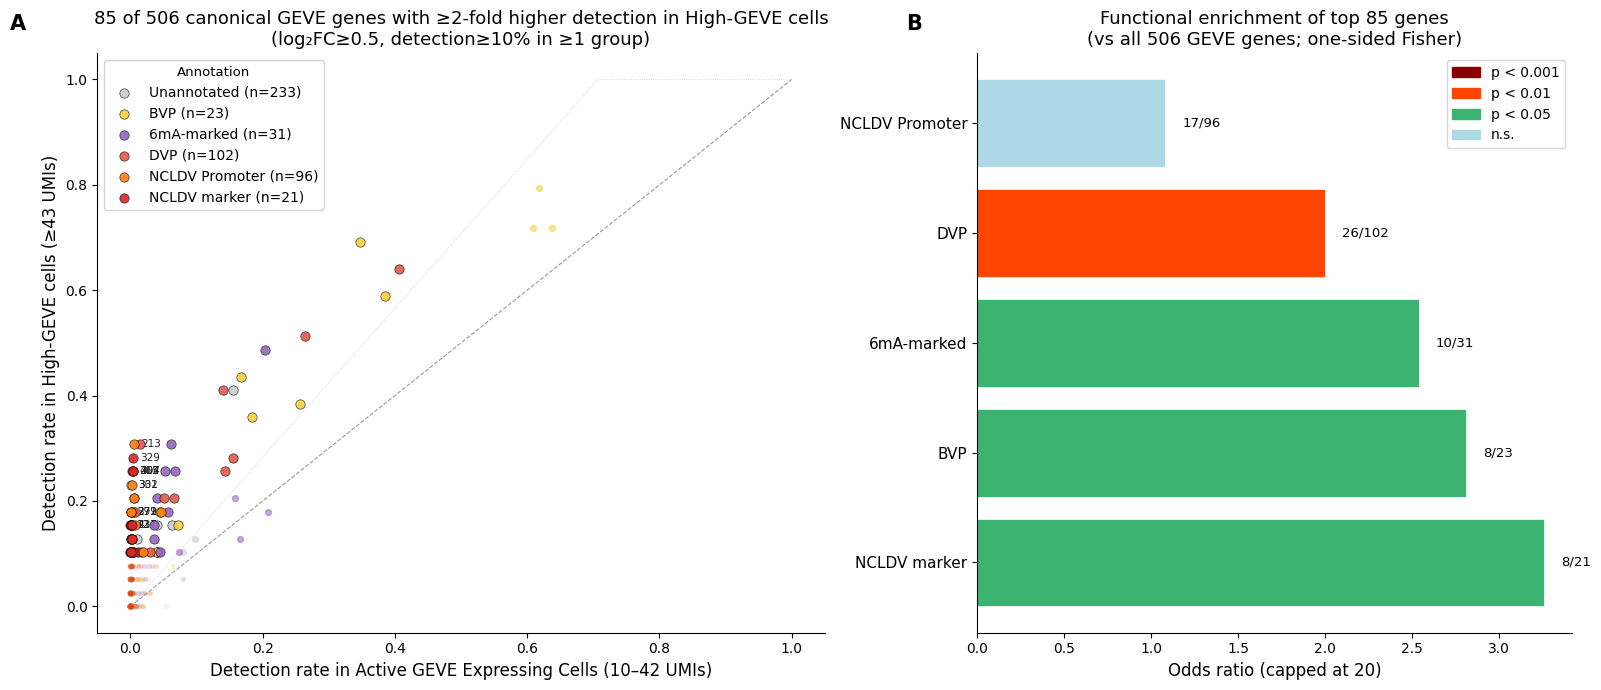

Appendix Figure 9 saved.


In [13]:
# -- PLOT: Appendix Figure 9 -- GEVE most-variable genes (detection rate scatter + enrichment) --
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy.stats import fisher_exact

VCOLOR = {
    'NCLDV marker'   : '#d62728',
    'NCLDV promoter' : '#ff7f0e',
    'DVP'            : '#e1594d',
    'BVP'            : '#F6D03C',
    '6mA-marked'     : '#9467bd',
    'Unannotated'    : '#cccccc',
}

# Gene sets identified by name (no index mismatch)
detected_genes = set(de_df_detected['gene'])
top_genes      = set(degs['gene'])

fig, (ax_s, ax_e) = plt.subplots(1, 2, figsize=(16, 7),
                                   gridspec_kw={'width_ratios': [1.1, 0.9]})

# ── Left panel: detection rate scatter ───────────────────────────────────────
diag = np.linspace(0, 1, 100)
ax_s.plot(diag, diag,                        color='#999999', lw=0.8, ls='--', zorder=1, label='_')
ax_s.plot(diag, np.minimum(diag * 2**MIN_LFC, 1),
                                              color='#cccccc', lw=0.6, ls=':', zorder=1, label='_')

for label in ['Unannotated', 'BVP', '6mA-marked', 'DVP', 'NCLDV promoter', 'NCLDV marker']:
    sub_v  = de_df[de_df['color_label'] == label]
    is_det = sub_v['gene'].isin(detected_genes)
    is_top = sub_v['gene'].isin(top_genes)
    ax_s.scatter(sub_v.loc[~is_det, 'pct_pro'],
                 sub_v.loc[~is_det, 'pct_viro'],
                 c=VCOLOR[label], s=8,  alpha=0.18, zorder=2)
    ax_s.scatter(sub_v.loc[is_det & ~is_top, 'pct_pro'],
                 sub_v.loc[is_det & ~is_top, 'pct_viro'],
                 c=VCOLOR[label], s=18, alpha=0.55, zorder=3)
    ax_s.scatter(sub_v.loc[is_top, 'pct_pro'],
                 sub_v.loc[is_top, 'pct_viro'],
                 c=VCOLOR[label], s=45, alpha=0.90, zorder=4,
                 edgecolors='black', linewidths=0.4,
                 label=f"{'NCLDV Promoter' if label == 'NCLDV promoter' else label} (n={len(sub_v)})")

for _, row in degs.head(14).iterrows():
    ax_s.annotate(row['gene'].replace('GEVEv2_', ''),
                  xy=(row['pct_pro'], row['pct_viro']),
                  xytext=(row['pct_pro'] + 0.01, row['pct_viro']),
                  fontsize=7.5, color='#222222', va='center',
                  arrowprops=dict(arrowstyle='-', lw=0.3, color='#aaaaaa'))

ax_s.set_xlabel('Detection rate in Active GEVE Expressing Cells (10–42 UMIs)', fontsize=12)
ax_s.set_ylabel('Detection rate in High-GEVE cells (≥43 UMIs)', fontsize=12)
ax_s.set_title(
    f'{len(degs)} of 506 canonical GEVE genes with ≥2-fold higher detection in High-GEVE cells\n'
    f'(log₂FC≥{MIN_LFC}, detection≥{MIN_PCT*100:.0f}% in ≥1 group)',
    fontsize=13)
ax_s.legend(fontsize=10, loc='upper left', framealpha=0.85,
            title='Annotation', title_fontsize=9.5)
for sp in ['top', 'right']: ax_s.spines[sp].set_visible(False)
ax_s.text(-0.12, 1.04, 'A', transform=ax_s.transAxes, fontsize=15, fontweight='bold')

# ── Right panel: functional enrichment vs all 506 canonical GEVE genes as background ───
_all_n = len(de_df)          # 506 total (canonical genes only, relics excluded)
_top_n = len(degs)           # 88 top genes
enrich_cats = {}
for cat in ['NCLDV marker', 'NCLDV promoter', 'DVP', 'BVP', '6mA-marked']:
    _all_k  = (de_df['color_label'] == cat).sum()   # category size in all 506
    _top_k  = (degs['color_label'] == cat).sum()    # category size in top 88
    if _all_k == 0: continue
    a = _top_k
    b = _top_n - _top_k
    c = _all_k - _top_k
    d = _all_n - _all_k - b
    if c < 0 or d < 0: continue
    _, p = fisher_exact([[a, b], [c, d]], alternative='greater')
    or_ = (a * d) / (b * c) if (b * c) > 0 else float('inf')
    enrich_cats[cat] = {'or': or_, 'p': p, 'k': a, 'bg': _all_k}
    print(f'  {cat}: top={a}/{_top_n}, all={_all_k}/{_all_n}, OR={or_:.2f}, p={p:.3e}')

if enrich_cats:
    cats = sorted(enrich_cats, key=lambda c: -enrich_cats[c]['or'])
    ors  = [min(enrich_cats[c]['or'], 20) for c in cats]   # cap for display
    ps   = [enrich_cats[c]['p'] for c in cats]
    cols = ['#8b0000' if p < 0.001 else ('#ff4500' if p < 0.01 else
            ('#3cb371' if p < 0.05 else '#add8e6')) for p in ps]
    bars = ax_e.barh(range(len(cats)), ors, color=cols,
                     edgecolor='white', linewidth=0.5)
    ax_e.set_yticks(range(len(cats)))
    ax_e.set_yticklabels([('NCLDV Promoter' if c == 'NCLDV promoter' else c) for c in cats], fontsize=11)
    for i, (c, bar) in enumerate(zip(cats, bars)):
        ax_e.text(bar.get_width() + 0.1, i,
                  f"{enrich_cats[c]['k']}/{enrich_cats[c]['bg']}",
                  va='center', fontsize=9.5)
    ax_e.set_xlabel('Odds ratio (capped at 20)', fontsize=12)
    ax_e.set_title(f'Functional enrichment of top {_top_n} genes\n(vs all {_all_n} GEVE genes; one-sided Fisher)',
                   fontsize=13)
    for sp in ['top', 'right']: ax_e.spines[sp].set_visible(False)
    legend_patches = [
        mpatches.Patch(color='#8b0000', label='p < 0.001'),
        mpatches.Patch(color='#ff4500', label='p < 0.01'),
        mpatches.Patch(color='#3cb371', label='p < 0.05'),
        mpatches.Patch(color='#add8e6', label='n.s.'),
    ]
    ax_e.legend(handles=legend_patches, fontsize=10, loc='upper right')
else:
    ax_e.text(0.5, 0.5, 'No enrichment data', ha='center', va='center',
              transform=ax_e.transAxes, fontsize=10, color='grey')

ax_e.text(-0.12, 1.04, 'B', transform=ax_e.transAxes, fontsize=15, fontweight='bold')

fig.tight_layout()
plt.savefig(FIG_DIR / 'AppFig9_detection_GEVE_active_vs_High_GEVE.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig9_detection_GEVE_active_vs_High_GEVE.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig9_detection_GEVE_active_vs_High_GEVE.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 9 saved.')


## Appendix Figure 10. Heatmap of most-variable GEVE genes across the 39 High-GEVE cells

Z-scored log1p expression of the S10 genes across the 39 High-GEVE cells, with Ward/Euclidean clustering. Normalization uses the 506 canonical genes only. Cutting the cell dendrogram at k = 2 separates the transcriptional Virocell cluster (the smaller one). Cutting the gene dendrogram at k = 2 gives the two gene modules defined in the next section.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig10_High_GEVE_variable_gene_heatmap.png`, `.pdf`, `.svg`


In [14]:
# -- COMPUTE: DE heatmap matrix -- top 39 GEVE-expressing cells (Appendix Figure 10) --
# Uses degs (with has_ncldv_prom) from Appendix Fig 9 compute cell.
# Reloads adata to rebuild the normalized expression matrix.
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path
from scipy.cluster.hierarchy import linkage as _hclust, fcluster as _fclust

FIG_DIR.mkdir(exist_ok=True)

TOP_N_CELLS_SF8 = 39

# Reload adata, filter to DE cell groups, normalize GEVE-only subset
_adata_sf8     = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
_pro_mask_sf8  = ((_adata_sf8.obs['geve_raw'] >= GEVE_MIN) &
                   (_adata_sf8.obs['geve_raw'] <  HG_MIN))
_viro_mask_sf8 =   _adata_sf8.obs['geve_raw'] >= HG_MIN
_geve_mask_sf8 = ((_adata_sf8.var['gene_type'] == 'GEVE') &
                  _adata_sf8.var_names.isin(set(gdf_track['gene'])))   # 506 canonical genes

_sub_sf8 = _adata_sf8[_pro_mask_sf8 | _viro_mask_sf8, _geve_mask_sf8].copy()
_sub_sf8.obs['de_group'] = 'pro'
_sub_sf8.obs.loc[_viro_mask_sf8[_pro_mask_sf8 | _viro_mask_sf8].values,
                  'de_group'] = 'viro'
del _adata_sf8

sc.pp.normalize_total(_sub_sf8, target_sum=1e4)
sc.pp.log1p(_sub_sf8)

# Extract expression matrix and metadata, then free the AnnData
_X_norm_sf8        = _sub_sf8.X
if sp.issparse(_X_norm_sf8): _X_norm_sf8 = _X_norm_sf8.toarray()
_cell_group_sf8    = _sub_sf8.obs['de_group'].values
_cell_geve_sf8     = _sub_sf8.obs['geve_raw'].values
_cell_dpi_sf8      = _sub_sf8.obs['dpi'].values.astype(int)
_var_names_sf8     = _sub_sf8.var_names.tolist()
del _sub_sf8

# Gene order: DEGs sorted by log2FC detection rate (descending)
deg_genes_sf8 = degs.sort_values('log2fc_det', ascending=False)['gene'].tolist()
_gene_idx_sf8 = [_var_names_sf8.index(g) for g in deg_genes_sf8]
_X_full_sf8   = _X_norm_sf8[:, _gene_idx_sf8]
del _X_norm_sf8

# Select top 39 cells by total GEVE UMIs
_top_idx_sf8    = np.argsort(_cell_geve_sf8)[::-1][:TOP_N_CELLS_SF8]
X_top_sf8       = _X_full_sf8[_top_idx_sf8]
cell_group_sf8  = _cell_group_sf8[_top_idx_sf8]
cell_geve_sf8   = _cell_geve_sf8[_top_idx_sf8]
cell_dpi_sf8    = _cell_dpi_sf8[_top_idx_sf8]
del _X_full_sf8, _cell_group_sf8, _cell_geve_sf8, _cell_dpi_sf8

n_viro_top_sf8 = (cell_group_sf8 == 'viro').sum()
n_pro_top_sf8  = (cell_group_sf8 == 'pro').sum()
print(f'Top {TOP_N_CELLS_SF8} cells: {n_viro_top_sf8} High-GEVE cells + {n_pro_top_sf8} latent GEVE cells')
print(f'  GEVE UMI range: {cell_geve_sf8.min():.0f} - {cell_geve_sf8.max():.0f}')

# Z-score per gene across the top-39 cells
_row_mean_sf8 = X_top_sf8.mean(axis=0)
_row_std_sf8  = X_top_sf8.std(axis=0)
_row_std_sf8[_row_std_sf8 == 0] = 1
X_zscore_sf8  = (X_top_sf8 - _row_mean_sf8) / _row_std_sf8

# Gene annotation table from degs (has_ncldv_prom already renamed in Appendix Fig 9)
deg_meta_sf8 = degs.set_index('gene').loc[deg_genes_sf8][
    ['cluster', 'has_6mA', 'has_ncldv_prom', 'has_introns', 'has_virion_prot',
     'log2fc_det', 'ncldv_marker', 'pfam_desc', 'gvog']
].copy()

def _ann_sf8(r):
    nc = str(r['ncldv_marker']) if pd.notna(r['ncldv_marker']) else ''
    pf = str(r['pfam_desc'])    if pd.notna(r['pfam_desc'])    else ''
    gv = str(r['gvog'])         if pd.notna(r['gvog'])         else ''
    if nc and nc not in ('nan', ''): return nc
    if pf and pf not in ('nan', ''):
        first = pf.split('|')[0].strip()
        return first[:32] + ('...' if len(first) > 32 else '')
    if gv and gv not in ('nan', ''): return gv
    return ''

deg_meta_sf8['ann'] = deg_meta_sf8.apply(_ann_sf8, axis=1)

# Hierarchical clustering (Ward / Euclidean)
col_linkage_sf8 = _hclust(X_zscore_sf8,   method='ward', metric='euclidean')
row_linkage_sf8 = _hclust(X_zscore_sf8.T, method='ward', metric='euclidean')

# Gene cluster labels (k=2), for bracket annotation above the column dendrogram
_gene_cl_sf8 = _fclust(row_linkage_sf8, 2, criterion='maxclust')
deg_meta_sf8['gene_cluster'] = _gene_cl_sf8
_n_gcl_A_sf8 = int((deg_meta_sf8['gene_cluster'] == 1).sum())
_n_gcl_B_sf8 = int((deg_meta_sf8['gene_cluster'] == 2).sum())
print(f'Gene cluster 1: {_n_gcl_A_sf8} genes   Gene cluster 2: {_n_gcl_B_sf8} genes')

# Identify transcriptional Virocell cluster (k=2, smaller cluster)
_cell_cl_sf8  = _fclust(col_linkage_sf8, 2, criterion='maxclust')
_cl_sizes_sf8 = {1: int((_cell_cl_sf8 == 1).sum()), 2: int((_cell_cl_sf8 == 2).sum())}
_true_cl_sf8  = min(_cl_sizes_sf8, key=_cl_sizes_sf8.get)
virocell_mask_sf8 = (_cell_cl_sf8 == _true_cl_sf8)
n_true_viro_sf8   = int(virocell_mask_sf8.sum())
n_highgeve_hm_sf8 = int((cell_group_sf8 == 'viro').sum()) - n_true_viro_sf8

print(f'Transcriptional Virocell cluster (k=2): {n_true_viro_sf8} cells')
print(f'  High-GEVE cells outside cluster: {n_highgeve_hm_sf8}')
print(f'  Latent GEVE cells: {n_pro_top_sf8}')
print(f'Expression matrix: {X_zscore_sf8.shape}  (top-{TOP_N_CELLS_SF8} cells x {len(deg_genes_sf8)} DE genes)')


Top 39 cells: 39 High-GEVE cells + 0 latent GEVE cells
  GEVE UMI range: 43 - 242
Gene cluster 1: 34 genes   Gene cluster 2: 51 genes
Transcriptional Virocell cluster (k=2): 12 cells
  High-GEVE cells outside cluster: 27
  Latent GEVE cells: 0
Expression matrix: (39, 85)  (top-39 cells x 85 DE genes)


Building clustermap ...


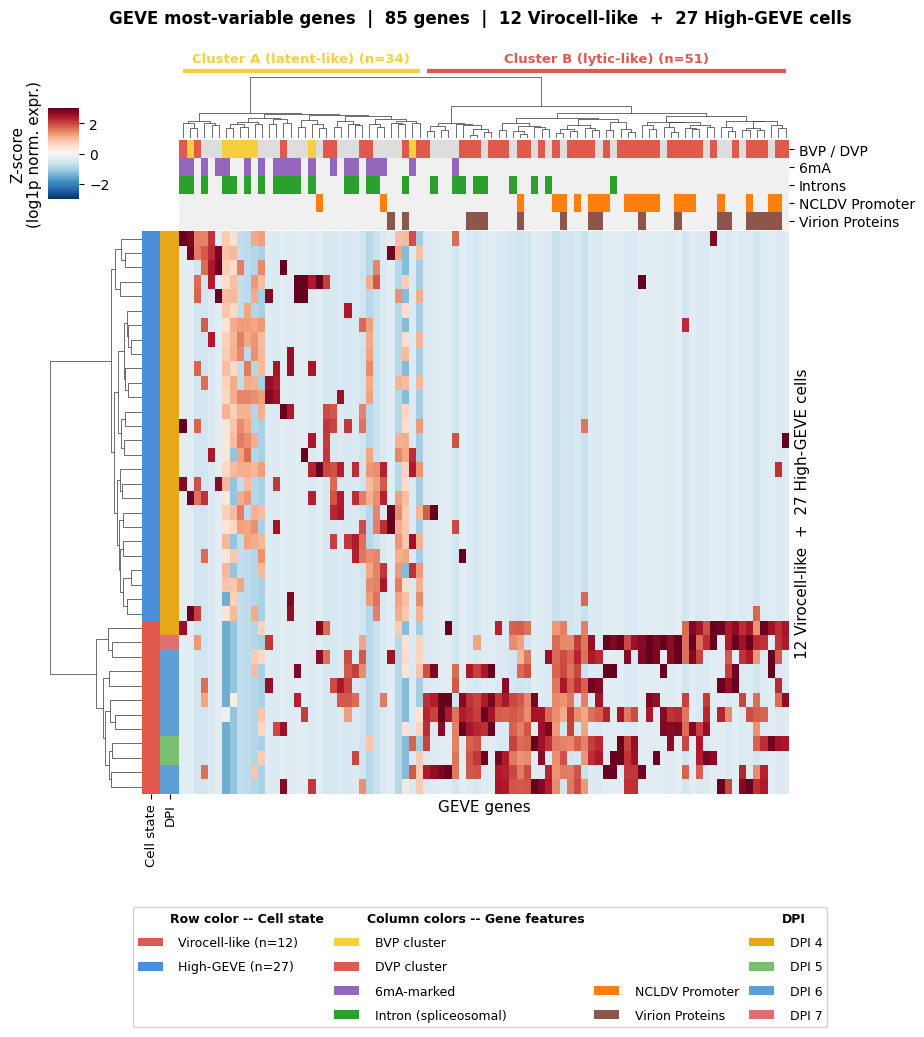

Appendix Figure 10 saved.


In [15]:
# -- PLOT: Appendix Figure 10 -- Most-variable GEVE gene heatmap, all 39 High-GEVE cells --
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import seaborn as sns

PRO_COLOR_SF8      = '#444444'
HIGHGEVE_COLOR_SF8 = '#4a90d9'
VIRO_COLOR_SF8     = '#e1594d'
DPI_CMAP_SF8 = {4: '#e6a817', 5: '#78c070', 6: '#5e9fd4', 7: '#e07070'}

# ── Row color bars (Cell state + DPI) ────────────────────────────────────────
row_colors_sf8 = pd.DataFrame({
    'Cell state': [VIRO_COLOR_SF8     if virocell_mask_sf8[i]
                   else (HIGHGEVE_COLOR_SF8 if cell_group_sf8[i] == 'viro'
                   else PRO_COLOR_SF8)
                   for i in range(len(cell_group_sf8))],
    'DPI':        [DPI_CMAP_SF8[d] for d in cell_dpi_sf8],
})

# ── Column color bars ─────────────────────────────────────────────────────────
clust_col_sf8 = deg_meta_sf8['cluster'].map({'BVP': '#F6D03C', 'DVP': '#e1594d'}).fillna('#dddddd')
clust_col_sf8.name = 'BVP / DVP'
mat6_col_sf8  = deg_meta_sf8['has_6mA'].map({True: '#9467bd', False: '#f0f0f0'})
mat6_col_sf8.name  = '6mA'
prom_col_sf8  = deg_meta_sf8['has_ncldv_prom'].map({True: '#ff7f0e', False: '#f0f0f0'})
prom_col_sf8.name  = 'NCLDV Promoter'
# Spliceosomal introns only (has_introns already excludes the MCP self-splicing intron; see c003)
intr_col_sf8 = deg_meta_sf8['has_introns'].map({True: '#2ca02c', False: '#f0f0f0'})
intr_col_sf8.name = 'Introns'
virion_col_sf8 = deg_meta_sf8['has_virion_prot'].map({True: '#8c564b', False: '#f0f0f0'})
virion_col_sf8.name = 'Virion Proteins'
col_colors_sf8 = pd.concat([clust_col_sf8, mat6_col_sf8, intr_col_sf8, prom_col_sf8, virion_col_sf8], axis=1)

# ── Heatmap DataFrame ─────────────────────────────────────────────────────────
ZCLIP = 3.0
hm_df_sf8 = pd.DataFrame(
    np.clip(X_zscore_sf8, -ZCLIP, ZCLIP),
    index=range(len(cell_group_sf8)),
    columns=deg_genes_sf8
)

print('Building clustermap ...')
g = sns.clustermap(
    hm_df_sf8,
    row_linkage=col_linkage_sf8, col_linkage=row_linkage_sf8,
    row_cluster=True, col_cluster=True,
    row_colors=row_colors_sf8,
    col_colors=col_colors_sf8,
    cmap='RdBu_r', center=0, vmin=-ZCLIP, vmax=ZCLIP,
    xticklabels=False, yticklabels=False,
    figsize=(9.0, max(7.5, TOP_N_CELLS_SF8 * 0.145 + 2.6)),
    cbar_pos=(0.02, 0.83, 0.035, 0.11),
    dendrogram_ratio=(0.13, 0.09),
    colors_ratio=0.025,
)

g.cax.set_ylabel('Z-score\n(log1p norm. expr.)', fontsize=11, labelpad=4)
g.cax.yaxis.set_label_position('left')

g.ax_heatmap.set_xlabel('GEVE genes', fontsize=11)
g.ax_heatmap.set_ylabel(
    f'{n_true_viro_sf8} Virocell-like  +  {n_highgeve_hm_sf8} High-GEVE cells', fontsize=11)

# row_colors column labels ("Cell state"/"DPI") -- rotate vertical to avoid overflow
for _lbl in g.ax_row_colors.get_xticklabels():
    _lbl.set_rotation(90)
    _lbl.set_ha('center')
    _lbl.set_va('top')
    _lbl.set_fontsize(9.5)

# Gene cluster A / B bracket labels along the reordered column axis
col_leaves = g.dendrogram_col.reordered_ind
cl_labels_ordered = deg_meta_sf8['gene_cluster'].values[col_leaves]
_bvp_frac_sf8 = {lab: (deg_meta_sf8.loc[deg_meta_sf8['gene_cluster'] == lab, 'cluster'] == 'BVP').mean()
                 for lab in (1, 2)}
_latent_label_sf8 = max(_bvp_frac_sf8, key=_bvp_frac_sf8.get)
runs = []
start = 0
for k in range(1, len(cl_labels_ordered) + 1):
    if k == len(cl_labels_ordered) or cl_labels_ordered[k] != cl_labels_ordered[start]:
        runs.append((start, k - 1, cl_labels_ordered[start]))
        start = k
_ax_cd = g.ax_col_dendrogram
_xlim_cd = _ax_cd.get_xlim()
_n_genes_sf8 = len(deg_genes_sf8)
_blend_sf8 = mtransforms.blended_transform_factory(_ax_cd.transData, _ax_cd.transAxes)
for (s, e, lab) in runs:
    xs = (s + 0.5) / _n_genes_sf8 * (_xlim_cd[1] - _xlim_cd[0]) + _xlim_cd[0]
    xe = (e + 0.5) / _n_genes_sf8 * (_xlim_cd[1] - _xlim_cd[0]) + _xlim_cd[0]
    is_latent = lab == _latent_label_sf8
    name = 'Cluster A (latent-like)' if is_latent else 'Cluster B (lytic-like)'
    color = '#F6D03C' if is_latent else '#e1594d'
    _ax_cd.plot([xs, xe], [1.05, 1.05], transform=_blend_sf8, color=color, lw=3,
                clip_on=False, solid_capstyle='butt')
    _ax_cd.text((xs + xe) / 2, 1.14, f'{name} (n={e - s + 1})', transform=_blend_sf8,
                ha='center', va='bottom', fontsize=9.5, color=color,
                fontweight='bold', clip_on=False)

# ── Legend — 4-column bottom-aligned, same layout as Figure S3 ──
_blank_sf8 = lambda: mpatches.Patch(color='none', label='')
leg_sf8 = [
    # column 1 -- Row color
    mpatches.Patch(color='none',          label='Row color -- Cell state'),
    mpatches.Patch(fc=VIRO_COLOR_SF8,     label=f'  Virocell-like (n={n_true_viro_sf8})'),
    mpatches.Patch(fc=HIGHGEVE_COLOR_SF8, label=f'  High-GEVE (n={n_highgeve_hm_sf8})'),
    _blank_sf8(), _blank_sf8(),
    # column 2 -- Column colors, part 1
    mpatches.Patch(color='none', label='Column colors -- Gene features'),
    mpatches.Patch(fc='#F6D03C', label='  BVP cluster'),
    mpatches.Patch(fc='#e1594d', label='  DVP cluster'),
    mpatches.Patch(fc='#9467bd', label='  6mA-marked'),
    mpatches.Patch(fc='#2ca02c', label='  Intron (spliceosomal)'),
    # column 3 -- Column colors, part 2 (bottom-aligned with the other columns)
    _blank_sf8(), _blank_sf8(), _blank_sf8(),
    mpatches.Patch(fc='#ff7f0e', label='  NCLDV Promoter'),
    mpatches.Patch(fc='#8c564b', label='  Virion Proteins'),
    # column 4 -- DPI
    mpatches.Patch(color='none', label='DPI'),
    mpatches.Patch(fc='#e6a817', label='  DPI 4'),
    mpatches.Patch(fc='#78c070', label='  DPI 5'),
    mpatches.Patch(fc='#5e9fd4', label='  DPI 6'),
    mpatches.Patch(fc='#e07070', label='  DPI 7'),
]
_leg = g.fig.legend(
    handles=leg_sf8, loc='upper center', bbox_to_anchor=(0.5, -0.02),
    ncol=4, fontsize=9, framealpha=0.9, title_fontsize=0,
    columnspacing=0.8, handletextpad=0.6, labelspacing=0.9)
for _t in _leg.get_texts():
    if _t.get_text() in ('Row color -- Cell state', 'Column colors -- Gene features', 'DPI'):
        _t.set_fontweight('bold')
        _t.set_fontsize(9)

g.fig.suptitle(
    f'GEVE most-variable genes  |  {len(deg_genes_sf8)} genes'
    f'  |  {n_true_viro_sf8} Virocell-like  +  {n_highgeve_hm_sf8} High-GEVE cells',
    fontsize=12, fontweight='bold', y=1.06)

plt.savefig(FIG_DIR / 'AppFig10_High_GEVE_variable_gene_heatmap.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig10_High_GEVE_variable_gene_heatmap.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig10_High_GEVE_variable_gene_heatmap.svg', bbox_inches='tight')

plt.show()
plt.close(g.fig)
print('Appendix Figure 10 saved.')


## Methods: lytic and latent module definition (506 genes; STAR Methods, "Differential detection and lytic/latent module identification")

The two k = 2 gene clusters from Appendix Figure 10 define the gene modules. The **lytic module** is the cluster with the higher mean Z-score in the transcriptional Virocell cluster, relative to the other High-GEVE cells. The other cluster is the **latent module**. The modules are saved to `tables/Methods_lytic_latent_modules_506.csv`. All later sections compute the per-cell lytic/latent ratio, log₂[(mean log1p lytic + 1) / (mean log1p latent + 1)], from these modules. That ratio defines the Virocells (GEVE > 10, ratio > 0 in log₂, GEVE/Chlamy > 0.02).

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/Methods_lytic_latent_module_definition.png`, `.pdf`, `.svg`
**File**: `tables/Methods_lytic_latent_modules_506.csv`

**Virocell classification** (Fig 3, S3–S6) uses the lytic/latent ratio computed on mean raw UMIs per module gene, which gives n = 21 Virocells. The ratio on log1p-normalized expression is used only for coloring (Fig 2A, B, D); used as a classifier it would add one cell (DPI 5, GEVE = 33, MCP = 0).


In [16]:
# -- COMPUTE: lytic / latent module definition from the S11 gene clusters (506 genes) --
import numpy as np
import pandas as pd

# The lytic module is the gene cluster most elevated in the transcriptional Virocell cluster.
_gcl = deg_meta_sf8['gene_cluster'].values
_delta = {}
for _k in (1, 2):
    _z = X_zscore_sf8[:, _gcl == _k]
    _delta[_k] = _z[virocell_mask_sf8].mean() - _z[~virocell_mask_sf8].mean()
_lytic_k  = max(_delta, key=_delta.get)
_latent_k = 3 - _lytic_k
print(f'Gene cluster mean Z (Virocell cluster - other High-GEVE): {_delta}  -> lytic = cluster {_lytic_k}')

module_df = degs.set_index('gene').loc[deg_meta_sf8.index].copy()
module_df['module'] = np.where(_gcl == _lytic_k, 'lytic', 'latent')
module_df['meanZ_virocell_cluster'] = X_zscore_sf8[virocell_mask_sf8].mean(axis=0)
module_df['meanZ_other_highgeve']   = X_zscore_sf8[~virocell_mask_sf8].mean(axis=0)
module_df = module_df.reset_index()

LYTIC_GENES  = module_df.loc[module_df['module'] == 'lytic',  'gene'].tolist()
LATENT_GENES = module_df.loc[module_df['module'] == 'latent', 'gene'].tolist()

_cols = ['gene', 'module', 'pct_viro', 'pct_pro', 'log2fc_det', 'meanZ_virocell_cluster', 'meanZ_other_highgeve',
         'cluster', 'has_6mA', 'has_ncldv_prom', 'has_introns', 'has_virion_prot', 'ncldv_marker', 'pfam_desc', 'gvog']
module_df[_cols].to_csv(TABLE_DIR / 'Methods_lytic_latent_modules_506.csv', index=False)

module_composition = (module_df.assign(cluster=module_df['cluster'].fillna('Unclassified'))
                      .groupby(['module', 'cluster']).size().unstack(fill_value=0)
                      .reindex(['lytic', 'latent']))

print(f'\nLytic module : {len(LYTIC_GENES)} genes')
print(f'Latent module: {len(LATENT_GENES)} genes')
print('\nBVP/DVP composition:'); print(module_composition.to_string())


Gene cluster mean Z (Virocell cluster - other High-GEVE): {1: np.float32(-0.40382564), 2: np.float32(1.3013643)}  -> lytic = cluster 2

Lytic module : 51 genes
Latent module: 34 genes

BVP/DVP composition:
cluster  BVP  DVP  Unclassified
module                         
lytic      0   34            17
latent     8    9            17


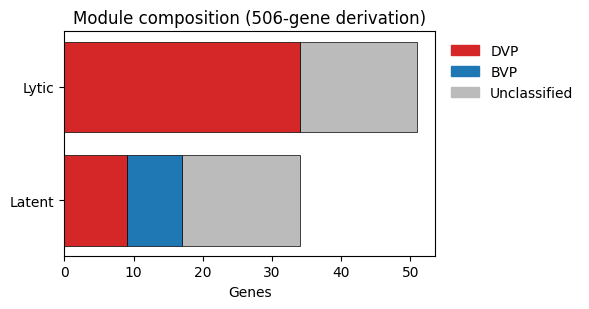

In [17]:
# -- PLOT: lytic / latent module composition --
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

_cl_colors = {'DVP': '#d62728', 'BVP': '#1f77b4', 'Unclassified': '#bbbbbb'}
fig, ax1 = plt.subplots(figsize=(6, 3.2))

_left = np.zeros(len(module_composition))
for _c in ['DVP', 'BVP', 'Unclassified']:
    if _c in module_composition.columns:
        _v = module_composition[_c].values
        ax1.barh(['Lytic', 'Latent'], _v, left=_left, color=_cl_colors[_c], edgecolor='black', lw=0.5)
        _left += _v
ax1.invert_yaxis()
ax1.set_xlabel('Genes')
ax1.set_title('Module composition (506-gene derivation)')
ax1.legend(handles=[mpatches.Patch(color=_cl_colors[c], label=c) for c in _cl_colors],
           loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)

plt.tight_layout()
plt.savefig(FIG_DIR / 'Methods_lytic_latent_module_definition.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'Methods_lytic_latent_module_definition.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'Methods_lytic_latent_module_definition.svg', bbox_inches='tight')
plt.show()


## Figure 2. GEVE transcriptional dynamics and single-cell developmental trajectory

(A) Per-cell GEVE UMIs by DPI, colored by the lytic/latent ratio. (B) Lytic/latent ratio vs GEVE/Chlamy ratio for cells with GEVE ≥ 10. (C–E) GEVE > 4 UMAP colored by cluster, lytic/latent ratio and mean virion-protein expression. Four compute cells cover the jitter base, the per-cell ratio, the UMAP and the virion-protein score.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/Fig2_GEVE_transcriptional_dynamics.png`, `.pdf`, `.svg`


In [18]:
# -- COMPUTE: BVP/DVP per-cell classification for jitter plot (Figure 2A) --
import scanpy as sc
import numpy as np
import pandas as pd
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path

FIG_DIR.mkdir(exist_ok=True)

adata_j = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
obs_j   = adata_j.obs.copy()
obs_j['dpi'] = obs_j['dpi'].astype(int)

anno = pd.read_excel(BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx')
anno = anno.rename(columns={'Unnamed: 0': 'gene_num'})
cluster_map = anno.set_index('gene')['cluster'].to_dict()
adata_j.var['cluster'] = adata_j.var_names.map(cluster_map)

counts_j = adata_j.layers['counts'] if 'counts' in adata_j.layers else adata_j.X
bvp_idx  = np.where(adata_j.var['cluster'] == 'BVP')[0]
dvp_idx  = np.where(adata_j.var['cluster'] == 'DVP')[0]

obs_j['bvp_raw'] = np.asarray(counts_j[:, bvp_idx].sum(axis=1)).ravel()
obs_j['dvp_raw'] = np.asarray(counts_j[:, dvp_idx].sum(axis=1)).ravel()

def _classify_geve(row):
    if row['geve_raw'] == 0:    return 'GEVE-'
    b, d = row['bvp_raw'], row['dvp_raw']
    if b == 0 and d == 0:       return 'Unclassified'
    if b > 0  and d == 0:       return 'BVP'
    if d > 0  and b == 0:       return 'DVP'
    return 'BVP' if b >= d else 'DVP'

obs_j['geve_cluster'] = obs_j.apply(_classify_geve, axis=1)
print(f'BVP genes: {len(bvp_idx)}  DVP genes: {len(dvp_idx)}')
print(obs_j['geve_cluster'].value_counts())
del adata_j


BVP genes: 24  DVP genes: 157
geve_cluster
BVP             7744
GEVE-           6781
DVP             4247
Unclassified    3649
Name: count, dtype: int64


In [19]:
# -- COMPUTE: Figure 2 -- Jitter colored by lytic/latent ratio --
# Self-contained: computes the lytic/latent ratio directly from adata.
# Depends on:
#   pub_sf4_compute        → LOGNORM_MU_SF4, DERIVED_VIRO_SF4
#   supfig3-jitter-compute → obs_j  (per-cell GEVE UMIs, DPI, MCP)
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path

# ── Gene module lists (same 51 lytic / 34 latent genes as Fig 3 UMAP) ────────
_lytic_genes  = set(pd.Series(LYTIC_GENES))
_latent_genes = set(pd.Series(LATENT_GENES))

# ── Load adata and compute per-cell lytic/latent ratio ───────────────────────
_a = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')

_total = np.asarray(_a.X.sum(axis=1)).ravel().astype(np.float32)
_total[_total == 0] = 1.0

_geve_mask  = (_a.var['gene_type'] == 'GEVE').values
_geve_names = _a.var_names[_geve_mask].tolist()
_X_geve     = _a[:, _geve_mask].X
if sp.issparse(_X_geve):
    _X_geve = _X_geve.toarray().astype(np.float32)

# log1p-normalise to 10 k per cell (identical to pub_fig2_compute)
_X_norm = np.log1p(_X_geve / _total[:, None] * 1e4)
del _X_geve

_lytic_idx  = np.array([g in _lytic_genes  for g in _geve_names])
_latent_idx = np.array([g in _latent_genes for g in _geve_names])

_mean_lytic  = _X_norm[:, _lytic_idx].mean(axis=1)
_mean_latent = _X_norm[:, _latent_idx].mean(axis=1)
_ratio_vals  = np.log2((_mean_lytic + 1) / (_mean_latent + 1))
del _X_norm

# ── Merge ratio into obs_j (barcodes are the index of obs_j) ─────────────────
_ratio_map = dict(zip(_a.obs_names.tolist(), _ratio_vals.tolist()))
del _a

obs_j_sf9 = obs_j.copy()
obs_j_sf9['ratio_ll'] = obs_j_sf9.index.map(_ratio_map)

# GEVE-expressing cells only
obs_j_sf9_expr = obs_j_sf9[obs_j_sf9['geve_raw'] > 0].copy()

print(f'Lytic genes in panel : {_lytic_idx.sum()}')
print(f'Latent genes in panel: {_latent_idx.sum()}')
print(f'GEVE-expressing cells: {len(obs_j_sf9_expr)}')
print(f'Ratio range : {obs_j_sf9_expr["ratio_ll"].min():.3f}  to  {obs_j_sf9_expr["ratio_ll"].max():.3f}')
print(f'Lytic-dominant  (>0) : {(obs_j_sf9_expr["ratio_ll"] > 0).sum()}')
print(f'Latent-dominant (<0) : {(obs_j_sf9_expr["ratio_ll"] < 0).sum()}')


Lytic genes in panel : 51
Latent genes in panel: 34
GEVE-expressing cells: 15640
Ratio range : -0.706  to  1.432
Lytic-dominant  (>0) : 266
Latent-dominant (<0) : 10214


In [20]:
# -- COMPUTE: UMAP panels + scatter data (Figure 2B–E) --
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path

FIG_DIR.mkdir(exist_ok=True)
# Gene module lists (51 lytic / 34 latent genes)
lytic_gene_set  = set(pd.Series(LYTIC_GENES))
latent_gene_set = set(pd.Series(LATENT_GENES))

# ── 1. adata_all_qc: ratio score + scatter data ───────────────────────────────
_adata_f2 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
geve_raw_f2  = _adata_f2.obs['geve_raw'].values.copy()
mcp_raw_f2   = _adata_f2.obs['mcp_raw'].values.copy()
barcodes_f2  = _adata_f2.obs_names.tolist()

# Chlamy UMI count per cell
_chlamy_mask = (_adata_f2.var['gene_type'] == 'chlamy').values
_X_chlamy = _adata_f2.X[:, _chlamy_mask]
if sp.issparse(_X_chlamy): _X_chlamy = _X_chlamy.toarray()
chlamy_umi_f2 = np.array(_X_chlamy.sum(axis=1)).flatten()
del _X_chlamy

# Total counts for normalisation
if 'total_counts' in _adata_f2.obs.columns:
    total_f2 = _adata_f2.obs['total_counts'].values.astype(float)
else:
    _X_all = _adata_f2.X
    if sp.issparse(_X_all): _X_all = _X_all.toarray()
    total_f2 = _X_all.sum(axis=1).astype(float)
    del _X_all
total_f2[total_f2 == 0] = 1

# Lytic/latent ratio on GEVE genes (adata_all_qc has no _cr2937r suffix)
_geve_var_f2 = _adata_f2.var_names[(_adata_f2.var['gene_type'] == 'GEVE').values]
_X_geve_f2   = _adata_f2[:, _geve_var_f2].X
if sp.issparse(_X_geve_f2): _X_geve_f2 = _X_geve_f2.toarray().astype(np.float32)
_X_geve_norm = np.log1p(_X_geve_f2 / total_f2[:, None] * 1e4)
del _adata_f2

_lytic_m  = np.array([g in lytic_gene_set  for g in _geve_var_f2])
_latent_m = np.array([g in latent_gene_set for g in _geve_var_f2])
print(f'Lytic genes matched:  {_lytic_m.sum()} / {len(lytic_gene_set)}')
print(f'Latent genes matched: {_latent_m.sum()} / {len(latent_gene_set)}')

_lytic_mean  = _X_geve_norm[:, _lytic_m].mean(axis=1)
_latent_mean = _X_geve_norm[:, _latent_m].mean(axis=1)
ratio_all_f2 = np.log2((_lytic_mean + 1) / (_latent_mean + 1))
del _X_geve_norm
# Virocell classification ratio: mean raw UMIs per module gene (same as the Fig 3 cell) -> n = 21
ratio_cls_f2 = np.log2((_X_geve_f2[:, _lytic_m].mean(axis=1) + 1) / (_X_geve_f2[:, _latent_m].mean(axis=1) + 1))
del _X_geve_f2

# Scatter data: cells with GEVE >= 10
_mask_scat  = geve_raw_f2 >= GEVE_MIN
x_scat_f2   = ratio_all_f2[_mask_scat]
y_scat_f2   = (geve_raw_f2[_mask_scat] + 0.5) / (chlamy_umi_f2[_mask_scat] + 0.5)
c_scat_f2   = geve_raw_f2[_mask_scat]
s_scat_f2   = 20 + mcp_raw_f2[_mask_scat] * 8
print(f'Scatter: {_mask_scat.sum()} cells with GEVE >= {GEVE_MIN}')

# ── 2. adata_hi4_hvg: UMAP coords + obs via h5py (bypasses uns/log1p/base IORegistryError) --
import h5py

_h5_path = ADATA_DIR / 'adata_hi4_hvg_geve_umap.h5ad'
with h5py.File(_h5_path, 'r') as _f:
    umap_f2      = _f['obsm']['X_umap'][:]
    hi4_barcodes = [x.decode() if isinstance(x, bytes) else x
                    for x in _f['obs']['_index'][:]]
    # cluster_hi4 (categorical)
    _codes_cl = _f['obs']['cluster_hi4']['codes'][:]
    _cats_cl  = [x.decode() if isinstance(x, bytes) else x
                 for x in _f['obs']['cluster_hi4']['categories'][:]]
    _cluster_hi4 = pd.Categorical.from_codes(_codes_cl, categories=_cats_cl)
    # dpi (categorical)
    _codes_dpi = _f['obs']['dpi']['codes'][:]
    _cats_dpi  = [int(x.decode()) if isinstance(x, bytes) else int(x)
                  for x in _f['obs']['dpi']['categories'][:]]
    _dpi_vals  = pd.Categorical.from_codes(_codes_dpi, categories=_cats_dpi)
    # numeric columns
    _geve_raw_hi4 = _f['obs']['geve_raw'][:].astype(float)
    _mcp_raw_hi4  = _f['obs']['mcp_raw'][:].astype(float)

obs_hi4_f2 = pd.DataFrame({
    'cluster_hi4': _cluster_hi4,
    'dpi':         _dpi_vals,
    'geve_raw':    _geve_raw_hi4,
    'mcp_raw':     _mcp_raw_hi4,
}, index=hi4_barcodes)

# Map ratio from adata_all_qc to GEVE>4 cells by barcode
_bc_idx_f2   = {bc: i for i, bc in enumerate(barcodes_f2)}
ratio_hi4_f2 = np.array([ratio_all_f2[_bc_idx_f2[bc]] for bc in hi4_barcodes])
mcp_hi4_f2   = obs_hi4_f2['mcp_raw'].values > 0
geve_hi4_log = np.log1p(obs_hi4_f2['geve_raw'].values)

print(f'UMAP cells: {len(hi4_barcodes)}')
print(f'Ratio score range (GEVE>4): {ratio_hi4_f2.min():.3f} to {ratio_hi4_f2.max():.3f}')


Lytic genes matched:  51 / 51
Latent genes matched: 34 / 34
Scatter: 1735 cells with GEVE >= 10
UMAP cells: 4688
Ratio score range (GEVE>4): -0.705 to 1.432


In [21]:
# -- COMPUTE: Mean virion protein gene expression on GEVE>4 UMAP --
import numpy as np
import pandas as pd
import h5py
import scipy.sparse as sp
from pathlib import Path

# Virion structural protein genes (Table S7), from the gdf_track annotation
virion_genes = gdf_track.loc[gdf_track['has_virion_prot'].astype(bool), 'gene'].tolist()

# ── Load UMAP coords, cluster labels, raw counts, and library size ──
_h5_vir = ADATA_DIR / 'adata_hi4_hvg_geve_umap.h5ad'
with h5py.File(_h5_vir, 'r') as _f:
    umap_vir    = _f['obsm']['X_umap'][:]
    _codes_cl   = _f['obs']['cluster_hi4']['codes'][:]
    _cats_cl    = [x.decode() if isinstance(x, bytes) else x
                   for x in _f['obs']['cluster_hi4']['categories'][:]]
    cluster_vir = pd.Categorical.from_codes(_codes_cl, categories=_cats_cl)
    total_vir   = _f['obs']['total_counts'][:].astype(np.float64)

    _varnames_vir = [x.decode() if isinstance(x, bytes) else x
                      for x in _f['var']['_index'][:]]
    _vgidx_vir = [_varnames_vir.index(g) for g in virion_genes if g in _varnames_vir]
    print(f'Virion protein genes matched: {len(_vgidx_vir)} / {len(virion_genes)}')

    _grp = _f['layers']['counts']
    _shape = tuple(_grp.attrs['shape'])
    _mat = sp.csr_matrix((_grp['data'][:], _grp['indices'][:], _grp['indptr'][:]),
                          shape=_shape)
    counts_vir_genes = np.asarray(_mat[:, _vgidx_vir].todense()).astype(np.float32)

# Per-gene CPM-style normalisation (matches Fig 3 lytic/latent ratio method), then
# average the log1p-normalised values across the matched virion protein genes.
_norm_vir = np.log1p(counts_vir_genes / total_vir[:, None] * 1e4)
mean_virion_expr_vir = _norm_vir.mean(axis=1)
n_det_vir = int((counts_vir_genes.sum(axis=1) > 0).sum())
print(f'Mean virion protein expression: {n_det_vir}/{len(mean_virion_expr_vir)} '
      f'({100*n_det_vir/len(mean_virion_expr_vir):.1f}%) GEVE>4 cells with >=1 '
      f'virion protein gene detected')


Virion protein genes matched: 42 / 42
Mean virion protein expression: 2966/4688 (63.3%) GEVE>4 cells with >=1 virion protein gene detected


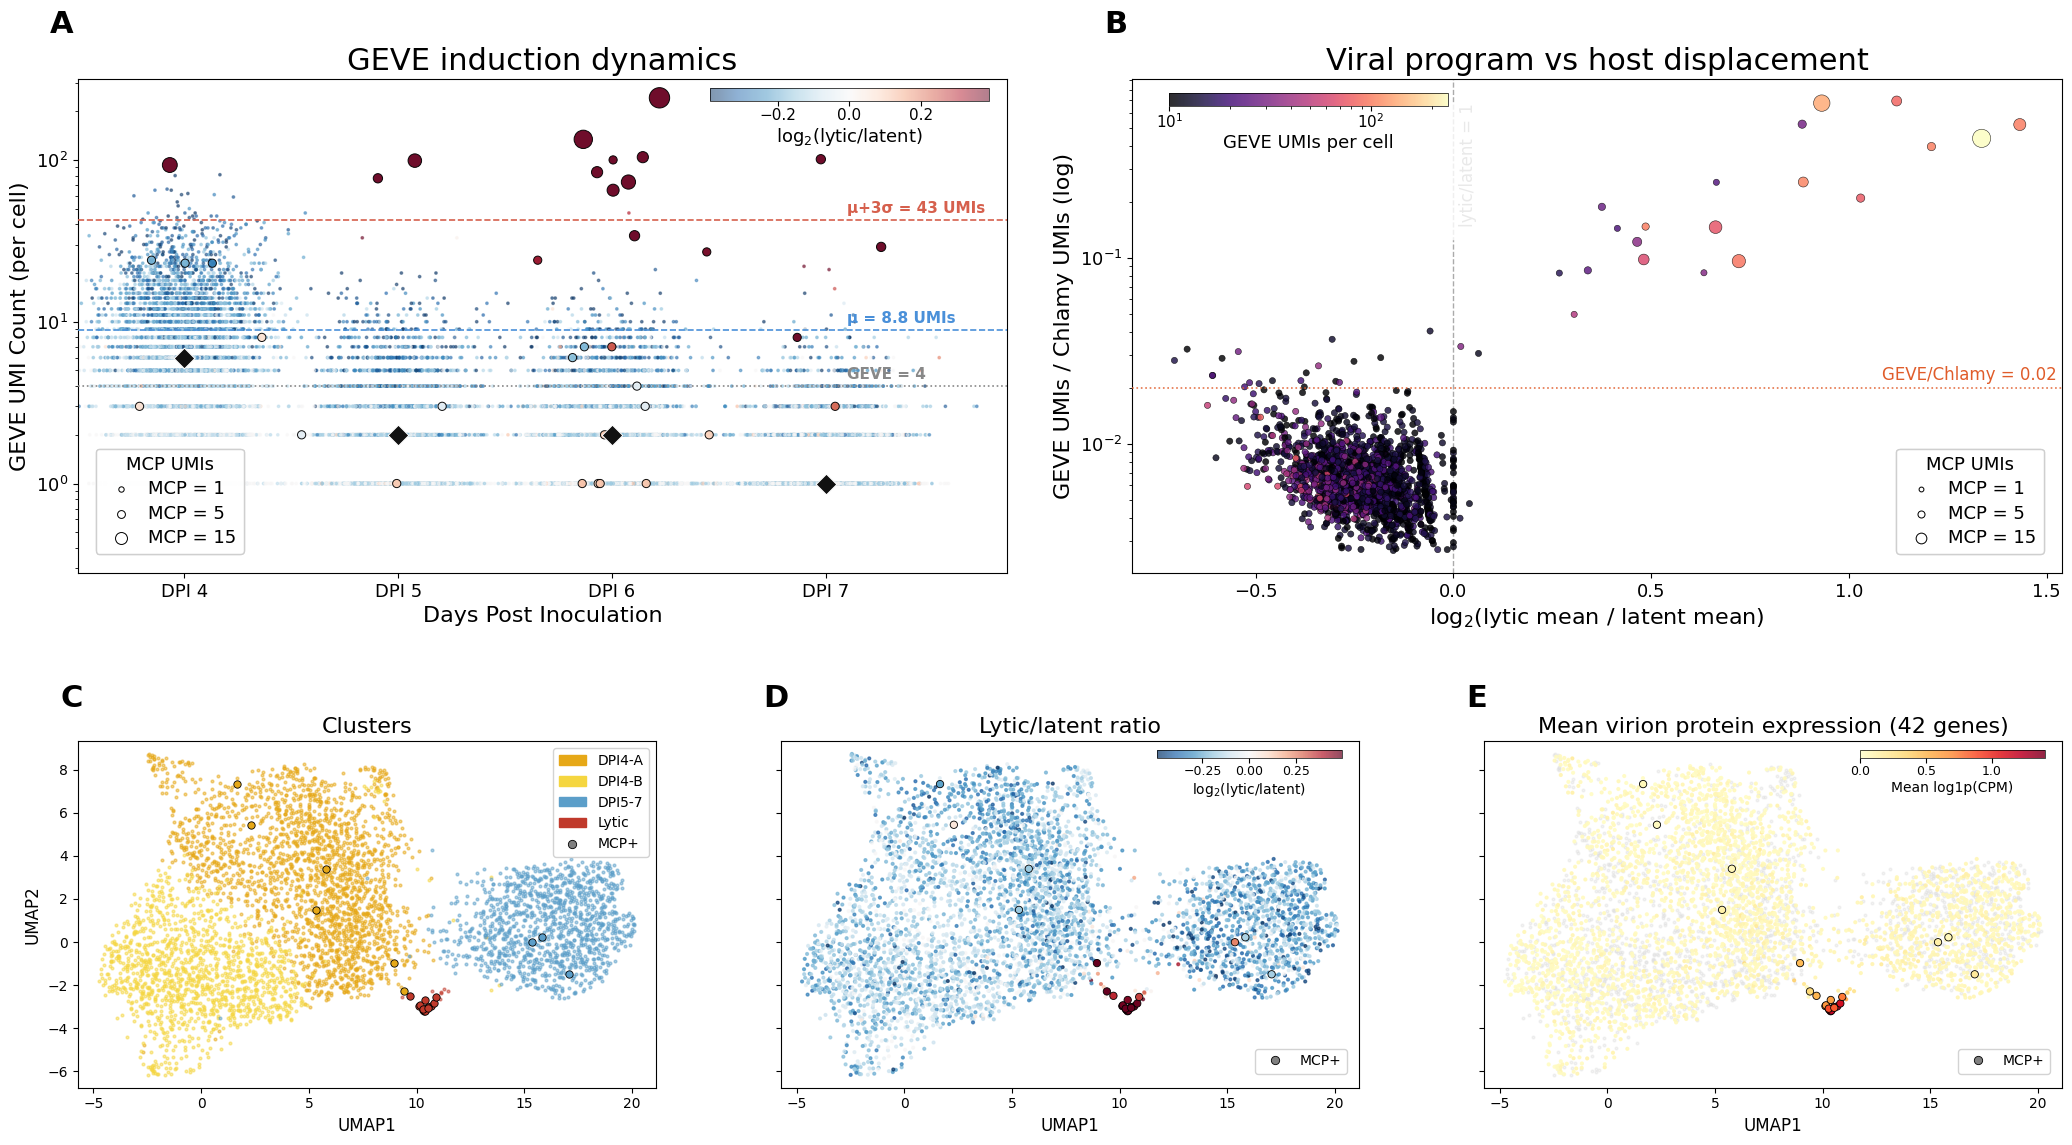

Figure 2 saved.


In [22]:
# -- PLOT: Figure 2 -- two-row layout, panels A–E --
# Based on Option C (v4). Row 1: panels A-B (jitter, trajectory), each spanning
# half the figure width. Row 2: panels C-E (cluster UMAP, ratio UMAP, mean
# virion protein UMAP), each spanning a third of the figure width. Colorbar/
# legend insets reuse the same _inset_hcb / _bg_box helpers as Option C.
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import numpy as np

# Shared constants (thresholds from the S7 compute cell; hi4 cluster palette)
NOISE_FLOOR = 4
MU_VAL      = 10 ** LOGNORM_MU_SF4
HG_THRESH   = DERIVED_VIRO_SF4
CLUSTER_ORDER = ['DPI4-A', 'DPI4-B', 'DPI5-7', 'Lytic']
CMAP_CL = {'DPI4-A': '#e6a817', 'DPI4-B': '#f5d640', 'DPI5-7': '#5b9ec9', 'Lytic': '#c0392b'}

_FS_TITLE, _FS_AX, _FS_TICK, _FS_LEG, _FS_PANEL = 22, 16, 13, 13, 22
_FS_CB, _FS_CB_TICK = 13, 11
_DOT_S = 5
_MCP_LW, _MCP_S = 0.8, 45

# Bottom row (C, D, E) is 1/3 figure width vs. the top row's 1/2 -- scale
# text/markers down by that ~0.67 width ratio so they don't crowd the
# narrower panels the way the full-size top-row fonts would.
_FS_TITLE_BOT, _FS_AX_BOT, _FS_TICK_BOT, _FS_LEG_BOT = 16, 12, 10, 10
_FS_CB_BOT, _FS_CB_TICK_BOT = 10, 9
_DOT_S_BOT = 4
_MCP_LW_BOT, _MCP_S_BOT = 0.6, 28

fig = plt.figure(figsize=(21, 13))
gs = fig.add_gridspec(2, 6, wspace=0.55, hspace=0.34,
                       left=0.04, right=0.985, top=0.95, bottom=0.06)

ax_jit  = fig.add_subplot(gs[0, 0:3])
ax_traj = fig.add_subplot(gs[0, 3:6])
ax_cl   = fig.add_subplot(gs[1, 0:2])
ax_rat  = fig.add_subplot(gs[1, 2:4])
ax_vir  = fig.add_subplot(gs[1, 4:6])

for _ax in (ax_jit, ax_traj, ax_cl, ax_rat, ax_vir):
    _ax.set_anchor('N')

# Explicit, padded UMAP limits shared identically across C/D/E. Computed once
# and applied via set_xlim/set_ylim + aspect(adjustable='box') rather than
# ax.sharey() + adjustable='datalim' -- that combination let each axis's
# aspect resolution disagree with the others, leaving some points outside
# the final shared view window (clipped at the wrong border).
_umap_pad = 0.04
_umap_x0, _umap_x1 = umap_f2[:, 0].min(), umap_f2[:, 0].max()
_umap_y0, _umap_y1 = umap_f2[:, 1].min(), umap_f2[:, 1].max()
_umap_xpad = (_umap_x1 - _umap_x0) * _umap_pad
_umap_ypad = (_umap_y1 - _umap_y0) * _umap_pad
UMAP_XLIM = (_umap_x0 - _umap_xpad, _umap_x1 + _umap_xpad)
UMAP_YLIM = (_umap_y0 - _umap_ypad, _umap_y1 + _umap_ypad)

def _bg_box(ax, x0, y0, w, h, pad=0.012, alpha=0.82):
    """Opaque rounded backing plate (axes-fraction coords) so an inset
    colorbar's ticks/label stay legible even where they cross data points."""
    box = mpatches.FancyBboxPatch(
        (x0 - pad, y0 - pad), w + 2 * pad, h + 2 * pad,
        transform=ax.transAxes, boxstyle='round,pad=0,rounding_size=0.006',
        facecolor='white', edgecolor='none', alpha=alpha, zorder=6, clip_on=False)
    ax.add_patch(box)

def _inset_hcb(ax, mappable, label, x0, y0, w, h, ticks=None, bg=None,
               fs_label=_FS_CB, fs_tick=_FS_CB_TICK):
    """Small horizontal colorbar embedded inside ax's own plot box (axes-fraction
    coords x0,y0,w,h give the BAR only -- tick/label text extends below it).
    `bg`, if given, is an (x0,y0,w,h) backing-plate box covering the bar +
    ticks + label footprint."""
    if bg is not None:
        _bg_box(ax, *bg)
    cax = ax.inset_axes([x0, y0, w, h], transform=ax.transAxes, zorder=7)
    cb = fig.colorbar(mappable, cax=cax, orientation='horizontal', ticks=ticks)
    cb.ax.tick_params(labelsize=fs_tick, pad=1.5)
    cb.set_label(label, fontsize=fs_label, labelpad=2)
    cb.outline.set_linewidth(0.5)
    return cb

def _panel_letter(ax, letter):
    """Place the panel letter just above the top-left corner of ax's plot box."""
    ax.text(-0.03, 1.08, letter, transform=ax.transAxes,
            fontsize=_FS_PANEL, fontweight='bold', ha='left', va='bottom')

# -- Panel A: jitter (reused from Figure 2) --
_ratios_expr = obs_j_sf9_expr['ratio_ll'].dropna()
_vmax_j = max(abs(float(_ratios_expr.quantile(0.98))),
              abs(float(_ratios_expr.quantile(0.02))), 0.1)
_norm_j = mcolors.TwoSlopeNorm(vmin=-_vmax_j, vcenter=0, vmax=_vmax_j)
_cmap_j = plt.cm.RdBu_r
_dpi_vals = sorted(obs_j_sf9_expr['dpi'].unique())
np.random.seed(42)

_no_mcp = obs_j_sf9_expr[obs_j_sf9_expr['mcp_raw'] == 0]
_jx = np.random.normal(_no_mcp['dpi'], 0.18, size=len(_no_mcp))
_sc_jit = ax_jit.scatter(_jx, _no_mcp['geve_raw'], c=_no_mcp['ratio_ll'],
                          cmap=_cmap_j, norm=_norm_j, s=3, alpha=0.5,
                          rasterized=True, zorder=2)
_mcp = obs_j_sf9_expr[obs_j_sf9_expr['mcp_raw'] > 0]
if len(_mcp):
    _jx_m = np.random.normal(_mcp['dpi'], 0.18, size=len(_mcp))
    ax_jit.scatter(_jx_m, _mcp['geve_raw'], c=_mcp['ratio_ll'],
                    cmap=_cmap_j, norm=_norm_j, s=25 + _mcp['mcp_raw'] * 10,
                    edgecolors='black', linewidths=0.7, alpha=0.95, zorder=5)
for _dpi in _dpi_vals:
    _vals = obs_j_sf9_expr.loc[obs_j_sf9_expr['dpi'] == _dpi, 'geve_raw'].values
    if len(_vals):
        ax_jit.scatter([_dpi], [np.median(_vals)], s=110, marker='D',
                        color='#111111', edgecolors='white', linewidths=0.7, zorder=7)
ax_jit.axhline(NOISE_FLOOR, color='#888888', lw=1.2, linestyle=':', zorder=3)
ax_jit.axhline(MU_VAL, color='#4a90d9', lw=1.2, linestyle='--', zorder=3)
ax_jit.axhline(HG_THRESH, color='#d6604d', lw=1.2, linestyle='--', zorder=3)
ax_jit.set_yscale('log')
ax_jit.set_xticks(_dpi_vals)
ax_jit.set_xticklabels([f'DPI {d}' for d in _dpi_vals], fontsize=_FS_TICK)
ax_jit.set_xlabel('Days Post Inoculation', fontsize=_FS_AX)
ax_jit.set_ylabel('GEVE UMI Count (per cell)', fontsize=_FS_AX)
ax_jit.set_xlim(min(_dpi_vals) - 0.5, max(_dpi_vals) + 0.85)
ax_jit.set_ylim(bottom=0.28)
ax_jit.tick_params(labelsize=_FS_TICK)
ax_jit.set_title('GEVE induction dynamics', fontsize=_FS_TITLE)

_x_lbl_A = max(_dpi_vals) + 0.1
ax_jit.text(_x_lbl_A, NOISE_FLOOR * 1.06, f'GEVE = {NOISE_FLOOR}',
            va='bottom', ha='left', fontsize=11, color='#888888', fontweight='bold')
ax_jit.text(_x_lbl_A, MU_VAL * 1.06, f'μ = {MU_VAL:.1f} UMIs',
            va='bottom', ha='left', fontsize=11, color='#4a90d9', fontweight='bold')
ax_jit.text(_x_lbl_A, HG_THRESH * 1.06, f'μ+3σ = {HG_THRESH:.0f} UMIs',
            va='bottom', ha='left', fontsize=11, color='#d6604d', fontweight='bold')

_inset_hcb(ax_jit, _sc_jit, 'log$_2$(lytic/latent)',
           x0=0.68, y0=0.955, w=0.30, h=0.025,
           bg=(0.045, 0.875, 0.30, 0.1))
_mcp_leg_vals_A = [1, 5, 15]
_mcp_handles_A = [
    ax_jit.scatter([], [], s=25 + v * 10, color='white',
                    edgecolors='black', linewidths=0.7, label=f'MCP = {v}')
    for v in _mcp_leg_vals_A
]
_leg_A = ax_jit.legend(handles=_mcp_handles_A, title='MCP UMIs',
                        fontsize=_FS_LEG, title_fontsize=_FS_LEG,
                        loc='lower left', bbox_to_anchor=(0.01, 0.02),
                        framealpha=0.85, borderpad=0.4, handletextpad=0.5,
                        labelspacing=0.35, markerscale=0.65)
ax_jit.add_artist(_leg_A)
_panel_letter(ax_jit, 'A')

# -- Panel B: trajectory scatter (reused from Figure 3 panel E) --
_sc_traj = ax_traj.scatter(
    x_scat_f2, y_scat_f2, c=c_scat_f2, cmap='magma',
    norm=mcolors.LogNorm(vmin=10, vmax=c_scat_f2.max()),
    s=s_scat_f2, alpha=0.82, edgecolors='black', linewidths=0.4,
    rasterized=True, zorder=2)
ax_traj.axvline(0, color='#888888', lw=1, ls='--', alpha=0.7, zorder=1)
ax_traj.axhline(2e-2, color='#e05c2a', lw=1.2, ls=':', alpha=0.85, zorder=3)
ax_traj.set_yscale('log')
ax_traj.set_xlabel('log$_2$(lytic mean / latent mean)', fontsize=_FS_AX)
ax_traj.set_ylabel('GEVE UMIs / Chlamy UMIs (log)', fontsize=_FS_AX)
ax_traj.set_title('Viral program vs host displacement', fontsize=_FS_TITLE)
ax_traj.tick_params(labelsize=_FS_TICK)

ax_traj.annotate('GEVE/Chlamy = 0.02',
                  xy=(ax_traj.get_xlim()[1], 2e-2),
                  xytext=(-4, 3), textcoords='offset points',
                  fontsize=12, color='#e05c2a', va='bottom', ha='right')
ax_traj.annotate('lytic/latent = 1',
                  xy=(0, 0.7), xycoords=('data', 'axes fraction'),
                  xytext=(4, 0), textcoords='offset points',
                  fontsize=12, color='#888888', ha='left', va='top',
                  rotation=90, rotation_mode='anchor')

_inset_hcb(ax_traj, _sc_traj, 'GEVE UMIs per cell',
           x0=0.04, y0=0.945, w=0.3, h=0.025, ticks=[10, 100],
           bg=(0.06, 0.685, 0.30, 0.255))
_mcp_leg_vals_B = [1, 5, 15]
_mcp_handles_B = [
    ax_traj.scatter([], [], s=20 + v * 8, color='white',
                     edgecolors='black', linewidths=0.7, label=f'MCP = {v}')
    for v in _mcp_leg_vals_B
]
_leg_B = ax_traj.legend(handles=_mcp_handles_B, title='MCP UMIs',
                         fontsize=_FS_LEG, title_fontsize=_FS_LEG,
                         loc='lower right', bbox_to_anchor=(0.99, 0.02),
                         framealpha=0.85, borderpad=0.4, handletextpad=0.5,
                         labelspacing=0.35, markerscale=0.65)
ax_traj.add_artist(_leg_B)
_panel_letter(ax_traj, 'B')

# -- Panel C: UMAP cluster --
_zorder_cl = {'DPI4-A': 1, 'DPI4-B': 1, 'DPI5-7': 2, 'Lytic': 4}
for _cl in CLUSTER_ORDER:
    _m = (obs_hi4_f2['cluster_hi4'] == _cl).values
    ax_cl.scatter(umap_f2[_m, 0], umap_f2[_m, 1], s=_DOT_S_BOT, alpha=0.5,
                  color=CMAP_CL[_cl], rasterized=True, zorder=_zorder_cl[_cl])
for _cl in CLUSTER_ORDER:
    _m = (obs_hi4_f2['cluster_hi4'] == _cl).values & mcp_hi4_f2
    if _m.sum():
        ax_cl.scatter(umap_f2[_m, 0], umap_f2[_m, 1], s=_MCP_S_BOT, alpha=1.0,
                       facecolors=CMAP_CL[_cl], edgecolors='black', linewidths=_MCP_LW_BOT, zorder=8)
_h_cl = [mpatches.Patch(color=CMAP_CL[_cl], label=_cl) for _cl in CLUSTER_ORDER]
_h_cl.append(mlines.Line2D([], [], marker='o', color='w',
    markerfacecolor='grey', markeredgecolor='black',
    markeredgewidth=_MCP_LW_BOT, markersize=6, label='MCP+'))
ax_cl.legend(handles=_h_cl, fontsize=_FS_LEG_BOT, loc='upper right', framealpha=0.85)
ax_cl.set_title('Clusters', fontsize=_FS_TITLE_BOT)
ax_cl.set_xlabel('UMAP1', fontsize=_FS_AX_BOT); ax_cl.set_ylabel('UMAP2', fontsize=_FS_AX_BOT)
ax_cl.set_xlim(UMAP_XLIM); ax_cl.set_ylim(UMAP_YLIM)
ax_cl.set_aspect('equal', adjustable='box')
ax_cl.tick_params(labelsize=_FS_TICK_BOT)
_panel_letter(ax_cl, 'C')

# -- Panel D: UMAP lytic/latent ratio --
_vabs_r = max(abs(np.percentile(ratio_hi4_f2, 1)), abs(np.percentile(ratio_hi4_f2, 99)))
_norm_r = mcolors.TwoSlopeNorm(vmin=-_vabs_r, vcenter=0, vmax=_vabs_r)
_cmap_r = plt.cm.RdBu_r
_sc_rat = ax_rat.scatter(umap_f2[:, 0], umap_f2[:, 1], s=_DOT_S_BOT, c=ratio_hi4_f2,
                          cmap=_cmap_r, norm=_norm_r, alpha=0.7, rasterized=True)
_mcp_fc_r = _cmap_r(_norm_r(ratio_hi4_f2[mcp_hi4_f2]))
ax_rat.scatter(umap_f2[mcp_hi4_f2, 0], umap_f2[mcp_hi4_f2, 1], s=_MCP_S_BOT, alpha=1.0,
               facecolors=_mcp_fc_r, edgecolors='black', linewidths=_MCP_LW_BOT, zorder=8)
ax_rat.set_title('Lytic/latent ratio', fontsize=_FS_TITLE_BOT)
ax_rat.set_xlabel('UMAP1', fontsize=_FS_AX_BOT)
ax_rat.set_xlim(UMAP_XLIM); ax_rat.set_ylim(UMAP_YLIM)
plt.setp(ax_rat.get_yticklabels(), visible=False)
ax_rat.set_aspect('equal', adjustable='box')
ax_rat.tick_params(labelsize=_FS_TICK_BOT)

_inset_hcb(ax_rat, _sc_rat, 'log$_2$(lytic/latent)',
           x0=0.65, y0=0.95, w=0.32, h=0.025,
           bg=(0.61, 0.775, 0.355, 0.16),
           fs_label=_FS_CB_BOT, fs_tick=_FS_CB_TICK_BOT)
ax_rat.legend(handles=[mlines.Line2D([], [], marker='o', color='w',
    markerfacecolor='grey', markeredgecolor='black',
    markeredgewidth=_MCP_LW_BOT, markersize=6, label='MCP+')],
    fontsize=_FS_LEG_BOT, loc='lower center', bbox_to_anchor=(0.9, 0.02),
    framealpha=0.85)
_panel_letter(ax_rat, 'D')

# -- Panel E: UMAP mean virion protein expression (Module 11d) --
_m_zero_vir = mean_virion_expr_vir == 0
ax_vir.scatter(umap_f2[_m_zero_vir, 0], umap_f2[_m_zero_vir, 1],
               s=_DOT_S_BOT, c='#e0e0e0', alpha=0.4, rasterized=True, zorder=1)
_m_det_vir = ~_m_zero_vir
_vmax_vir = mean_virion_expr_vir[_m_det_vir].max() if _m_det_vir.sum() > 0 else 1.0
_sc_vir = ax_vir.scatter(umap_f2[_m_det_vir, 0], umap_f2[_m_det_vir, 1],
                          s=_DOT_S_BOT, c=mean_virion_expr_vir[_m_det_vir], cmap='YlOrRd',
                          norm=mcolors.Normalize(vmin=0, vmax=_vmax_vir),
                          alpha=0.85, rasterized=True, zorder=2)
_mcp_fc_vir = plt.cm.YlOrRd(mcolors.Normalize(vmin=0, vmax=_vmax_vir)(mean_virion_expr_vir[mcp_hi4_f2]))
ax_vir.scatter(umap_f2[mcp_hi4_f2, 0], umap_f2[mcp_hi4_f2, 1], s=_MCP_S_BOT, alpha=1.0,
               facecolors=_mcp_fc_vir, edgecolors='black', linewidths=_MCP_LW_BOT, zorder=8)
ax_vir.set_title('Mean virion protein expression (42 genes)', fontsize=_FS_TITLE_BOT)
ax_vir.set_xlabel('UMAP1', fontsize=_FS_AX_BOT)
ax_vir.set_xlim(UMAP_XLIM); ax_vir.set_ylim(UMAP_YLIM)
plt.setp(ax_vir.get_yticklabels(), visible=False)
ax_vir.set_aspect('equal', adjustable='box')
ax_vir.tick_params(labelsize=_FS_TICK_BOT)

_inset_hcb(ax_vir, _sc_vir, 'Mean log1p(CPM)',
           x0=0.65, y0=0.95, w=0.32, h=0.025,
           bg=(0.61, 0.775, 0.355, 0.16),
           fs_label=_FS_CB_BOT, fs_tick=_FS_CB_TICK_BOT)
ax_vir.legend(handles=[mlines.Line2D([], [], marker='o', color='w',
    markerfacecolor='grey', markeredgecolor='black',
    markeredgewidth=_MCP_LW_BOT, markersize=6, label='MCP+')],
    fontsize=_FS_LEG_BOT, loc='lower center', bbox_to_anchor=(0.9, 0.02),
    framealpha=0.85)
_panel_letter(ax_vir, 'E')

plt.savefig(FIG_DIR / 'Fig2_GEVE_transcriptional_dynamics.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'Fig2_GEVE_transcriptional_dynamics.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'Fig2_GEVE_transcriptional_dynamics.svg', bbox_inches='tight')

plt.show()
print('Figure 2 saved.')


## Figure S3. GEVE expression heatmap comparing virocells and top-21 High-GEVE latent cells

Virocells (ratio-based definition, new modules) and the top 21 High-GEVE non-Virocell cells by GEVE UMI. Genes are detected in > 20% of Virocells or > 10% of High-GEVE cells, and are clustered by Ward.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/FigS3_virocell_GEVE_expression_heatmap.png`, `.pdf`, `.svg`


In [23]:
# -- COMPUTE: Figure S3 -- GEVE expression heatmap: Virocells vs top-21 High-GEVE latent cells --
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path
from scipy.cluster.hierarchy import linkage as _hclust, fcluster as _fclust
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# Cell classification using variables from Figure 2 compute cell
_gc_ratio_sf9 = (geve_raw_f2 + 0.5) / (chlamy_umi_f2 + 0.5)
_virocell_sf9 = (geve_raw_f2 >= GEVE_MIN) & (ratio_cls_f2 > 0) & (_gc_ratio_sf9 > 0.02)
_highgeve_sf9 = (geve_raw_f2 >= HG_MIN) & ~_virocell_sf9
_sel_sf9      = _virocell_sf9 | _highgeve_sf9

TOP_HIGH_SF9 = 21   # top High-GEVE cells by GEVE UMI count

_viro_bc_sf9 = {bc for bc, v in zip(barcodes_f2, _virocell_sf9) if v}

# High-GEVE barcodes sorted by GEVE UMI descending; keep top TOP_HIGH_SF9
_high_pairs  = sorted(
    [(bc, g) for bc, g, h in zip(barcodes_f2, geve_raw_f2, _highgeve_sf9) if h],
    key=lambda x: x[1], reverse=True
)
_high_bc_sf9 = [bc for bc, _ in _high_pairs[:TOP_HIGH_SF9]]

_sel_bc_sf9 = sorted(_viro_bc_sf9 | set(_high_bc_sf9),
                     key=lambda bc: barcodes_f2.index(bc))

cell_label_sf9 = np.array(['Virocell' if bc in _viro_bc_sf9 else 'High-GEVE latent cell'
                            for bc in _sel_bc_sf9])
_bc_to_idx     = {bc: i for i, bc in enumerate(barcodes_f2)}
cell_geve_sf9  = np.array([geve_raw_f2[_bc_to_idx[bc]]   for bc in _sel_bc_sf9])
cell_ratio_sf9 = np.array([ratio_all_f2[_bc_to_idx[bc]]  for bc in _sel_bc_sf9])
cell_gc_sf9    = np.array([_gc_ratio_sf9[_bc_to_idx[bc]] for bc in _sel_bc_sf9])

n_viro_sf9 = int(_virocell_sf9.sum())
n_high_sf9 = TOP_HIGH_SF9
print(f'True Virocells (GEVE>={GEVE_MIN}, log2(lytic/latent)>0, GEVE/Chlamy>0.02): {n_viro_sf9}')
print(f'High-GEVE latent cells for heatmap (top {TOP_HIGH_SF9} by GEVE UMI, GEVE>=43, not Virocell):  {n_high_sf9}')

# GEVE expression for selected cells (normalize to 10k + log1p)
_adata_sf9    = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
_geve_vars_sf9 = _adata_sf9.var_names[_adata_sf9.var['gene_type'] == 'GEVE'].tolist()
# Exclude relic loci — keep only canonical 506-gene annotation
_canonical_sf9 = set(gdf_track['gene'])
_geve_vars_sf9 = [g for g in _geve_vars_sf9 if g in _canonical_sf9]

_sub_sf9 = _adata_sf9[_sel_bc_sf9, _geve_vars_sf9].copy()
cell_dpi_sf9 = _adata_sf9.obs.loc[_sel_bc_sf9, 'dpi'].astype(int).values
del _adata_sf9

sc.pp.normalize_total(_sub_sf9, target_sum=1e4)
sc.pp.log1p(_sub_sf9)

_X_norm_sf9 = _sub_sf9.X
if sp.issparse(_X_norm_sf9): _X_norm_sf9 = _X_norm_sf9.toarray().astype(np.float32)
del _sub_sf9

# Gene filtering: detected in >20% of Virocells or >10% of High-GEVE cells
_v_idx_sf9 = cell_label_sf9 == 'Virocell'
_h_idx_sf9 = cell_label_sf9 == 'High-GEVE latent cell'
_det_v_sf9 = (_X_norm_sf9[_v_idx_sf9] > 0).mean(axis=0)
_det_h_sf9 = (_X_norm_sf9[_h_idx_sf9] > 0).mean(axis=0)
_keep_sf9  = (_det_v_sf9 > 0.20) | (_det_h_sf9 > 0.10)

genes_sf9   = [_geve_vars_sf9[i] for i, k in enumerate(_keep_sf9) if k]
_X_filt_sf9 = _X_norm_sf9[:, _keep_sf9]
del _X_norm_sf9
print(f'Genes shown: {len(genes_sf9)} (>20% Virocell or >10% High-GEVE latent cell detection)')

# Z-score per gene across all selected cells
_mu_sf9 = _X_filt_sf9.mean(axis=0)
_sd_sf9 = _X_filt_sf9.std(axis=0)
_sd_sf9[_sd_sf9 == 0] = 1
X_zscore_sf9 = (_X_filt_sf9 - _mu_sf9) / _sd_sf9
del _X_filt_sf9

# Hierarchical clustering
col_linkage_sf9 = _hclust(X_zscore_sf9,   method='ward', metric='euclidean')
row_linkage_sf9 = _hclust(X_zscore_sf9.T, method='ward', metric='euclidean')

# Gene cluster labels computed after linkage; assigned to gene_meta_sf9 below
_gene_cl_sf9 = _fclust(row_linkage_sf9, 2, criterion='maxclust')

# Gene metadata from gdf_track (covers all GEVE genes; uses has_late_prom = NCLDV prom)
_gt_sf9 = gdf_track.set_index('gene')
gene_meta_sf9 = pd.DataFrame({
    'cluster':         [_gt_sf9.loc[g, 'cluster']              if g in _gt_sf9.index else 'Unclassified' for g in genes_sf9],
    'has_6mA':         [bool(_gt_sf9.loc[g, 'has_6mA'])         if g in _gt_sf9.index else False for g in genes_sf9],
    'has_ncldv_prom':  [bool(_gt_sf9.loc[g, 'has_late_prom'])   if g in _gt_sf9.index else False for g in genes_sf9],
    'has_introns':     [bool(_gt_sf9.loc[g, 'has_introns'])     if g in _gt_sf9.index else False for g in genes_sf9],
    'has_virion_prot': [bool(_gt_sf9.loc[g, 'has_virion_prot']) if g in _gt_sf9.index else False for g in genes_sf9],
}, index=genes_sf9)
# Annotation string for x-axis labels — same truncation logic as S7
_de_idx_sf9 = de_df.set_index('gene')
def _ann_sf9(g):
    if g not in _de_idx_sf9.index: return ''
    row = _de_idx_sf9.loc[g]
    nc = str(row.get('ncldv_marker', '') or '').strip()
    pf = str(row.get('pfam_desc',    '') or '').strip()
    gv = str(row.get('gvog',         '') or '').strip()
    if nc and nc != 'nan': return nc
    if pf and pf != 'nan':
        first = pf.split('|')[0].strip()
        return first[:32] + ('...' if len(first) > 32 else '')
    if gv and gv != 'nan': return gv
    return ''
gene_meta_sf9['ann'] = [_ann_sf9(g) for g in genes_sf9]

# Gene cluster membership (k=2) and enrichment analysis
gene_meta_sf9['gene_cluster'] = _gene_cl_sf9
cl_A = gene_meta_sf9['gene_cluster'] == 1
cl_B = gene_meta_sf9['gene_cluster'] == 2
n_gcl_A = int(cl_A.sum());  n_gcl_B = int(cl_B.sum())
print(f'\nGene cluster A: {n_gcl_A} genes   Gene cluster B: {n_gcl_B} genes')

# ── Detection-rate enrichment: 21 Virocells vs all High-GEVE latent cells (GEVE>=43, not Virocell) ──
_all_high_bc_sf9 = [bc for bc, h in zip(barcodes_f2, _highgeve_sf9) if h]
n_all_pv_sf9 = len(_all_high_bc_sf9)
print(f'\nAll High-GEVE latent cells (GEVE>=43, not Virocell): {n_all_pv_sf9}')

_enr_cells_sf9  = sorted(_viro_bc_sf9 | set(_all_high_bc_sf9),
                          key=lambda bc: barcodes_f2.index(bc))
_enr_label_sf9  = np.array(['Virocell' if bc in _viro_bc_sf9 else 'LatentGEVE'
                             for bc in _enr_cells_sf9])
_adata_enr_sf9  = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
_geve_enr_sf9   = [g for g in _adata_enr_sf9.var_names[_adata_enr_sf9.var['gene_type'] == 'GEVE']
                    if g in _canonical_sf9]
_sub_enr_sf9    = _adata_enr_sf9[_enr_cells_sf9, _geve_enr_sf9].copy()
del _adata_enr_sf9
sc.pp.normalize_total(_sub_enr_sf9, target_sum=1e4)
sc.pp.log1p(_sub_enr_sf9)
_X_enr_sf9 = _sub_enr_sf9.X
if sp.issparse(_X_enr_sf9): _X_enr_sf9 = _X_enr_sf9.toarray().astype(np.float32)
del _sub_enr_sf9

_vm_e = _enr_label_sf9 == 'Virocell'
_pm_e = _enr_label_sf9 == 'LatentGEVE'

_cats_enr_sf9 = {
    'DVP':              np.array([_gt_sf9.loc[g, 'cluster'] == 'DVP'        if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    'BVP':              np.array([_gt_sf9.loc[g, 'cluster'] == 'BVP'        if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    'NCLDV Promoter':   np.array([bool(_gt_sf9.loc[g, 'has_late_prom'])      if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    'Virion Proteins':  np.array([bool(_gt_sf9.loc[g, 'has_virion_prot'])    if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    'Introns (DVP)':    np.array([bool(_gt_sf9.loc[g, 'has_introns']) and _gt_sf9.loc[g, 'cluster'] == 'DVP'
                                  if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    'Introns (other)':  np.array([bool(_gt_sf9.loc[g, 'has_introns']) and _gt_sf9.loc[g, 'cluster'] not in ('BVP', 'DVP')
                                  if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    'Introns (BVP)':    np.array([bool(_gt_sf9.loc[g, 'has_introns']) and _gt_sf9.loc[g, 'cluster'] == 'BVP'
                                  if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
    '6mA':              np.array([bool(_gt_sf9.loc[g, 'has_6mA'])            if g in _gt_sf9.index else False for g in _geve_enr_sf9]),
}
_enrich_rows_sf9 = []
for _cat, _feat in _cats_enr_sf9.items():
    _Xcat  = _X_enr_sf9[:, _feat]
    _ng    = int(_feat.sum())
    _nv, _np = int(_vm_e.sum()), int(_pm_e.sum())
    _dv = int((_Xcat[_vm_e] > 0).sum());  _tv = _nv * _ng
    _dp = int((_Xcat[_pm_e] > 0).sum());  _tp = _np * _ng
    # OR: Virocell / High-GEVE latent cell detection rate  (>1 = lytic enriched, <1 = latent enriched)
    _or, _p = fisher_exact([[_dv, _tv - _dv], [_dp, _tp - _dp]])
    _enrich_rows_sf9.append({
        'Category':    _cat,
        'n_genes':     _ng,
        'det_pct_viro': round(100 * _dv / _tv, 1),
        'det_pct_pv':   round(100 * _dp / _tp, 1),
        'OR': round(float(_or), 3), 'p': _p,
    })

enrich_df_sf9 = pd.DataFrame(_enrich_rows_sf9)
_, enrich_df_sf9['FDR'], _, _ = multipletests(enrich_df_sf9['p'], method='fdr_bh')
enrich_df_sf9['sig'] = enrich_df_sf9['FDR'].apply(
    lambda q: '***' if q < 0.001 else ('**' if q < 0.01 else ('*' if q < 0.05 else 'ns')))
print(f'\nDetection enrichment: {n_viro_sf9} Virocells vs {n_all_pv_sf9} High-GEVE latent cells (GEVE>=43, not Virocell), 506 GEVE genes:')
print(enrich_df_sf9[['Category','n_genes','det_pct_viro','det_pct_pv','OR','FDR','sig']].to_string(
    index=False, float_format='{:.3g}'.format))


True Virocells (GEVE>=10, log2(lytic/latent)>0, GEVE/Chlamy>0.02): 21
High-GEVE latent cells for heatmap (top 21 by GEVE UMI, GEVE>=43, not Virocell):  21
Genes shown: 83 (>20% Virocell or >10% High-GEVE latent cell detection)

Gene cluster A: 34 genes   Gene cluster B: 49 genes

All High-GEVE latent cells (GEVE>=43, not Virocell): 27



Detection enrichment: 21 Virocells vs 27 High-GEVE latent cells (GEVE>=43, not Virocell), 506 GEVE genes:
       Category  n_genes  det_pct_viro  det_pct_pv    OR      FDR sig
            DVP      157          13.4         2.4  6.36 2.91e-77 ***
            BVP       24           6.2        30.2 0.151 2.79e-26 ***
 NCLDV Promoter      105            11         0.6  20.4 4.76e-68 ***
Virion Proteins       42          19.6         4.8  4.88 1.47e-25 ***
  Introns (DVP)       16          12.5        10.2  1.26    0.356  ns
Introns (other)       36          13.9         6.9  2.18 2.46e-06 ***
  Introns (BVP)        9           5.3        32.1 0.118 8.64e-13 ***
            6mA       53           6.5        13.3 0.449 1.19e-08 ***


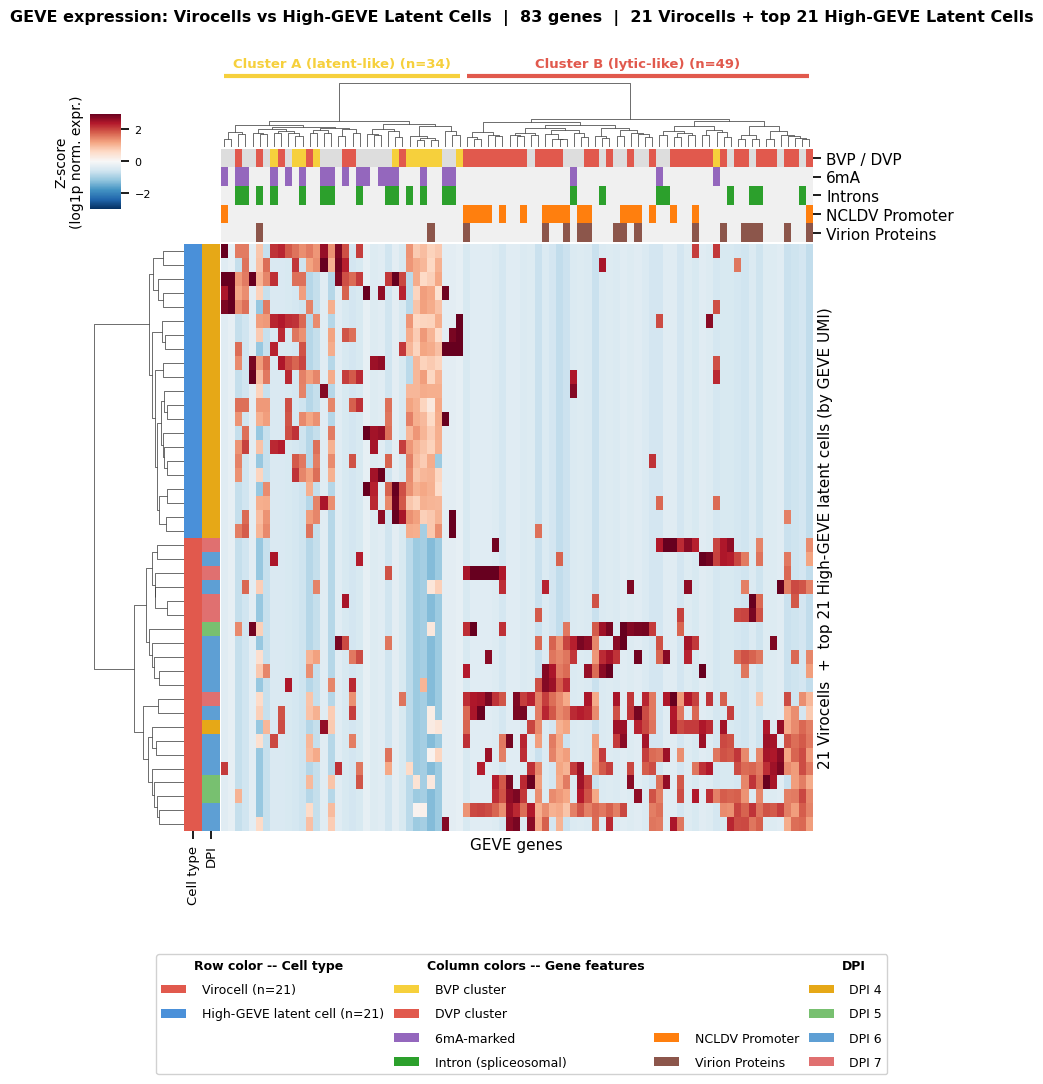

Figure S3 saved.

Detection enrichment: 21 Virocells vs 27 High-GEVE latent cells:


,Category,n_genes,Det% Virocell (n=21),Det% High-GEVE latent (n=27),OR,FDR,sig
0,DVP,157,13.400000,2.400000,6.359,2.91e-77,***
1,BVP,24,6.200000,30.200000,0.151,2.79e-26,***
2,NCLDV Promoter,105,11.000000,0.600000,20.436,4.76e-68,***
3,Virion Proteins,42,19.600000,4.800000,4.880,1.47e-25,***
4,Introns (DVP),16,12.500000,10.200000,1.260,3.56e-01,ns
5,Introns (other),36,13.900000,6.900000,2.179,2.46e-06,***
6,Introns (BVP),9,5.300000,32.100000,0.118,8.64e-13,***
7,6mA,53,6.500000,13.300000,0.449,1.19e-08,***


In [24]:
# -- PLOT: Figure S3 -- GEVE expression heatmap: Virocells vs top-21 High-GEVE latent cells --
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import seaborn as sns
from IPython.display import display

VIRO_COLOR_SF9     = '#e1594d'
HIGHGEVE_COLOR_SF9 = '#4a90d9'
DPI_CMAP_SF9 = {4: '#e6a817', 5: '#78c070', 6: '#5e9fd4', 7: '#e07070'}

row_colors_sf9 = pd.DataFrame({
    'Cell type': [VIRO_COLOR_SF9 if lbl == 'Virocell' else HIGHGEVE_COLOR_SF9
                  for lbl in cell_label_sf9],
    'DPI':       [DPI_CMAP_SF9[d] for d in cell_dpi_sf9],
})

clust_col_sf9 = gene_meta_sf9['cluster'].map({'BVP': '#F6D03C', 'DVP': '#e1594d'}).fillna('#dddddd')
clust_col_sf9.name = 'BVP / DVP'
mat6_col_sf9  = gene_meta_sf9['has_6mA'].map({True: '#9467bd', False: '#f0f0f0'}); mat6_col_sf9.name  = '6mA'
prom_col_sf9  = gene_meta_sf9['has_ncldv_prom'].map({True: '#ff7f0e', False: '#f0f0f0'}); prom_col_sf9.name  = 'NCLDV Promoter'
# Spliceosomal introns only (has_introns already excludes the MCP self-splicing intron; see c003)
intr_col_sf9 = gene_meta_sf9['has_introns'].map({True: '#2ca02c', False: '#f0f0f0'}); intr_col_sf9.name = 'Introns'
virion_col_sf9 = gene_meta_sf9['has_virion_prot'].map({True: '#8c564b', False: '#f0f0f0'}); virion_col_sf9.name = 'Virion Proteins'
col_colors_sf9 = pd.concat([clust_col_sf9, mat6_col_sf9, intr_col_sf9, prom_col_sf9, virion_col_sf9], axis=1)

ZCLIP = 3.0
hm_df_sf9 = pd.DataFrame(np.clip(X_zscore_sf9, -ZCLIP, ZCLIP), index=range(len(cell_label_sf9)), columns=genes_sf9)

FIG_W = 9.0
FIG_H = max(7.5, (n_viro_sf9 + n_high_sf9) * 0.145 + 2.6)

sns.set_context('notebook')
g = sns.clustermap(
    hm_df_sf9,
    row_linkage=col_linkage_sf9, col_linkage=row_linkage_sf9,
    row_cluster=True, col_cluster=True,
    row_colors=row_colors_sf9, col_colors=col_colors_sf9,
    cmap='RdBu_r', center=0, vmin=-ZCLIP, vmax=ZCLIP,
    xticklabels=False, yticklabels=False,
    figsize=(FIG_W, FIG_H),
    cbar_pos=(0.02, 0.83, 0.035, 0.11),
    dendrogram_ratio=(0.13, 0.09),
    colors_ratio=0.025,
)

g.cax.set_ylabel('Z-score\n(log1p norm. expr.)', fontsize=10, labelpad=4)
g.cax.yaxis.set_label_position('left')
g.cax.tick_params(labelsize=8)

g.ax_heatmap.set_xlabel('GEVE genes', fontsize=11)
g.ax_heatmap.set_ylabel(f'{n_viro_sf9} Virocells  +  top {n_high_sf9} High-GEVE latent cells (by GEVE UMI)', fontsize=11)

# row_colors column labels ("Cell type"/"DPI") -- rotate vertical so the narrow
# 2-column strip doesn't force wide horizontal text to overflow past the figure edge
for _lbl in g.ax_row_colors.get_xticklabels():
    _lbl.set_rotation(90)
    _lbl.set_ha('center')
    _lbl.set_va('top')
    _lbl.set_fontsize(9.5)

# Cluster A / B bracket labels along the reordered column axis
col_leaves = g.dendrogram_col.reordered_ind
cl_labels_ordered = gene_meta_sf9['gene_cluster'].values[col_leaves]
runs = []
start = 0
for k in range(1, len(cl_labels_ordered) + 1):
    if k == len(cl_labels_ordered) or cl_labels_ordered[k] != cl_labels_ordered[start]:
        runs.append((start, k - 1, cl_labels_ordered[start]))
        start = k
ax = g.ax_col_dendrogram
xlim = ax.get_xlim()
n_genes = len(genes_sf9)
_blend = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for (s, e, lab) in runs:
    xs = (s + 0.5) / n_genes * (xlim[1] - xlim[0]) + xlim[0]
    xe = (e + 0.5) / n_genes * (xlim[1] - xlim[0]) + xlim[0]
    name = 'Cluster A (latent-like)' if lab == 1 else 'Cluster B (lytic-like)'
    color = '#F6D03C' if lab == 1 else '#e1594d'
    ax.plot([xs, xe], [1.05, 1.05], transform=_blend, color=color, lw=3,
            clip_on=False, solid_capstyle='butt')
    ax.text((xs + xe) / 2, 1.14, f'{name} (n={e - s + 1})', transform=_blend,
            ha='center', va='bottom', fontsize=9.5, color=color,
            fontweight='bold', clip_on=False)

_blank = lambda: mpatches.Patch(color='none', label='')
leg_sf9 = [
    # column 1 -- Row color
    mpatches.Patch(color='none',          label='Row color -- Cell type'),
    mpatches.Patch(fc=VIRO_COLOR_SF9,     label=f'  Virocell (n={n_viro_sf9})'),
    mpatches.Patch(fc=HIGHGEVE_COLOR_SF9, label=f'  High-GEVE latent cell (n={n_high_sf9})'),
    _blank(), _blank(),
    # column 2 -- Column colors, part 1
    mpatches.Patch(color='none', label='Column colors -- Gene features'),
    mpatches.Patch(fc='#F6D03C', label='  BVP cluster'),
    mpatches.Patch(fc='#e1594d', label='  DVP cluster'),
    mpatches.Patch(fc='#9467bd', label='  6mA-marked'),
    mpatches.Patch(fc='#2ca02c', label='  Intron (spliceosomal)'),
    # column 3 -- Column colors, part 2 (bottom-aligned with the other columns)
    _blank(), _blank(), _blank(),
    mpatches.Patch(fc='#ff7f0e', label='  NCLDV Promoter'),
    mpatches.Patch(fc='#8c564b', label='  Virion Proteins'),
    # column 4 -- DPI
    mpatches.Patch(color='none', label='DPI'),
    mpatches.Patch(fc='#e6a817', label='  DPI 4'),
    mpatches.Patch(fc='#78c070', label='  DPI 5'),
    mpatches.Patch(fc='#5e9fd4', label='  DPI 6'),
    mpatches.Patch(fc='#e07070', label='  DPI 7'),
]
_leg = g.fig.legend(
    handles=leg_sf9, loc='upper center', bbox_to_anchor=(0.5, -0.02),
    ncol=4, fontsize=9, framealpha=0.9, title_fontsize=0,
    columnspacing=0.8, handletextpad=0.6, labelspacing=0.9)
for _t in _leg.get_texts():
    if _t.get_text() in ('Row color -- Cell type', 'Column colors -- Gene features', 'DPI'):
        _t.set_fontweight('bold')
        _t.set_fontsize(9)

g.fig.suptitle(
    f'GEVE expression: Virocells vs High-GEVE Latent Cells  |  {len(genes_sf9)} genes  |  '
    f'{n_viro_sf9} Virocells + top {n_high_sf9} High-GEVE Latent Cells',
    fontsize=11.5, fontweight='bold', y=1.06)

plt.savefig(FIG_DIR / 'FigS3_virocell_GEVE_expression_heatmap.png', dpi=200, bbox_inches='tight', pad_inches=0.2)
plt.savefig(FIG_DIR / 'FigS3_virocell_GEVE_expression_heatmap.pdf', bbox_inches='tight', pad_inches=0.2)
plt.savefig(FIG_DIR / 'FigS3_virocell_GEVE_expression_heatmap.svg', bbox_inches='tight', pad_inches=0.2)
plt.show()
plt.close(g.fig)
print('Figure S3 saved.')

# Enrichment table below the figure
print(f'\nDetection enrichment: {n_viro_sf9} Virocells vs {n_all_pv_sf9} High-GEVE latent cells:')
display(
    enrich_df_sf9[['Category', 'n_genes', 'det_pct_viro', 'det_pct_pv', 'OR', 'FDR', 'sig']]
    .rename(columns={'det_pct_viro': f'Det% Virocell (n={n_viro_sf9})',
                     'det_pct_pv':   f'Det% High-GEVE latent (n={n_all_pv_sf9})'})
    .style.format({'OR': '{:.3f}', 'FDR': '{:.2e}'})
    .set_caption('Fisher exact test, BH-FDR; OR = High-GEVE latent / Virocell detection rate')
)


## Appendix Figure 4. Differential detection of GEVE virion protein genes in virocells versus all latent GEVE cells

Per-gene Fisher test on detection of the 42 virion structural protein genes.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig4_virion_protein_detection.png`, `.pdf`, `.svg`

**Note**: the comparison group in the code is all GEVE ≥ 10 non-Virocells (n = 1,714), not the 766 pro-virocells named in the manuscript legend.


In [25]:
# -- COMPUTE: Appendix Figure 4 -- Virion Protein Gene DE: Virocells vs all latent GEVE cells (>=10) --
# Virocells defined by publication thresholds (n=21):
#   GEVE_raw >= 10  AND  log2(lytic/latent) > 0  AND  GEVE/Chlamy > 0.02
# Latent GEVE cells: GEVE_raw >= 10  AND  NOT Virocell
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path
from scipy.stats import fisher_exact, false_discovery_control

FIG_DIR.mkdir(exist_ok=True)

VIRO_MIN = GEVE_MIN  # Virocell GEVE lower bound (>= 10)
PRO_MIN  = GEVE_MIN  # latent GEVE cell lower bound (>= 10; same floor as Virocell)

# -- 1. Build virion protein gene list from Science paper proteomics (Data S5) --
_vr        = pd.read_csv(VIRION_CSV)   # derived from Data S1 (viralrecall_anno) + Data S5 (filt_data)

_virion_acc = set(_vr.loc[_vr['detected_in_virion_proteome'], 'protein_ids'])
_start_map  = {int(r['start_in_complete_contig_536']): r['protein_ids'] for _, r in _vr.iterrows()}
_end_map    = {int(r['end_in_complete_contig_536']):   r['protein_ids'] for _, r in _vr.iterrows()}

_ann = pd.read_excel(BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx')
_ann = _ann.rename(columns={'Unnamed: 0': 'gene_num'}).reset_index(drop=True)
_ann['_pacc'] = _ann['start'].apply(lambda s: _start_map.get(int(s)))
_nm = _ann['_pacc'].isna()
_ann.loc[_nm, '_pacc'] = _ann.loc[_nm, 'end'].apply(lambda e: _end_map.get(int(e)))
_ann['has_virion'] = _ann['_pacc'].isin(_virion_acc)

virion_genes_727 = _ann[_ann['has_virion']]['gene'].tolist()
_ann_vir_idx     = _ann[_ann['has_virion']].set_index('gene')
_fcat_map_727    = _vr.dropna(subset=['virion_functional_cat']).set_index('protein_ids')['virion_functional_cat'].to_dict()
print(f'Virion protein genes identified: {len(virion_genes_727)}')

# -- 2. Load adata and compute Virocell thresholds (same as pub notebook Fig 2) --
lytic_gene_set  = set(pd.Series(LYTIC_GENES))
latent_gene_set = set(pd.Series(LATENT_GENES))

_adata_727 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
_geve_raw  = _adata_727.obs['geve_raw'].values.astype(float)
_barcodes  = _adata_727.obs_names.tolist()

# Chlamy UMI per cell
_chlamy_mask = (_adata_727.var['gene_type'] == 'chlamy').values
_X_ch = _adata_727.X[:, _chlamy_mask]
if sp.issparse(_X_ch): _X_ch = _X_ch.toarray()
_chlamy_umi = np.array(_X_ch.sum(axis=1)).flatten(); del _X_ch

# Total counts for CPM normalisation
if 'total_counts' in _adata_727.obs.columns:
    _total = _adata_727.obs['total_counts'].values.astype(float)
else:
    _Xt = _adata_727.X
    if sp.issparse(_Xt): _Xt = _Xt.toarray()
    _total = _Xt.sum(axis=1).astype(float); del _Xt
_total[_total == 0] = 1

# Lytic/latent ratio: log2((mean lytic CPM + 1) / (mean latent CPM + 1))
_geve_vars = _adata_727.var_names[(_adata_727.var['gene_type'] == 'GEVE').values]
_X_geve    = _adata_727[:, _geve_vars].X
if sp.issparse(_X_geve): _X_geve = _X_geve.toarray().astype(np.float32)
_X_norm    = np.log1p(_X_geve / _total[:, None] * 1e4)

_lytic_m  = np.array([g in lytic_gene_set  for g in _geve_vars])
_latent_m = np.array([g in latent_gene_set for g in _geve_vars])
print(f'Lytic genes matched: {_lytic_m.sum()}  Latent genes matched: {_latent_m.sum()}')

_lytic_mean  = _X_norm[:, _lytic_m].mean(axis=1)
_latent_mean = _X_norm[:, _latent_m].mean(axis=1)
_ratio       = np.log2((_lytic_mean + 1) / (_latent_mean + 1)); del _X_norm
# Virocell classification ratio on mean raw UMIs (same as Fig 3) -> n = 21
_ratio_cls   = np.log2((_X_geve[:, _lytic_m].mean(axis=1) + 1) / (_X_geve[:, _latent_m].mean(axis=1) + 1)); del _X_geve
_gc_ratio    = (_geve_raw + 0.5) / (_chlamy_umi + 0.5)

# Virocell mask: GEVE >= 10, log2(lytic/latent) > 0, GEVE/Chlamy > 0.02
_viro_mask = (_geve_raw >= VIRO_MIN) & (_ratio_cls > 0) & (_gc_ratio > 0.02)
viro_bc_727 = [bc for bc, v in zip(_barcodes, _viro_mask) if v]
print(f'Virocells (GEVE>={VIRO_MIN}, log2(lytic/latent)>0, GEVE/Chlamy>0.02): n={len(viro_bc_727)}')

# latent GEVE cells: GEVE >= PRO_MIN, NOT Virocell
_hg_mask = (_geve_raw >= PRO_MIN) & ~_viro_mask
hg_bc_727 = [bc for bc, h in zip(_barcodes, _hg_mask) if h]
print(f'all latent GEVE cells (GEVE >= {PRO_MIN}, not Virocell): n={len(hg_bc_727)}')

# -- 3. Extract raw counts for virion genes in both groups --
_vg_727      = [g for g in virion_genes_727 if g in _adata_727.var_names]
_missing_727 = [g for g in virion_genes_727 if g not in _adata_727.var_names]
if _missing_727:
    print(f'Virion genes absent from adata (skipped): {_missing_727}')

_all_bc_727 = viro_bc_727 + hg_bc_727
_sub_727    = _adata_727[_all_bc_727, _vg_727]
X_727 = _sub_727.layers['counts'] if 'counts' in _sub_727.layers else _sub_727.X
if sp.issparse(X_727): X_727 = X_727.toarray()
del _adata_727

n_viro_727 = len(viro_bc_727)
n_hg_727   = len(hg_bc_727)
X_viro_727 = X_727[:n_viro_727]
X_hg_727   = X_727[n_viro_727:]

# -- 4. Fisher's exact on detection rates (same method as Fig 7.9) --
_eps = 1 / (n_viro_727 + n_hg_727)
rows_727 = []
for gi, gene in enumerate(_vg_727):
    det_v  = int((X_viro_727[:, gi] > 0).sum())
    det_h  = int((X_hg_727[:,  gi] > 0).sum())
    ndet_v = n_viro_727 - det_v
    ndet_h = n_hg_727   - det_h
    _, pval = fisher_exact([[det_v, ndet_v], [det_h, ndet_h]], alternative='two-sided')
    pct_v  = det_v / n_viro_727
    pct_h  = det_h / n_hg_727 if n_hg_727 > 0 else 0.0
    log2fc = np.log2((pct_v + _eps) / (pct_h + _eps))
    _pacc  = _ann_vir_idx.loc[gene, '_pacc'] if gene in _ann_vir_idx.index else ''
    _fcat  = _fcat_map_727.get(_pacc, 'Unknown')
    rows_727.append(dict(gene=gene, prot_acc=_pacc, functional_cat=_fcat,
                         pct_virocell=round(pct_v, 3), pct_highgeve=round(pct_h, 3),
                         det_virocell=det_v, det_highgeve=det_h,
                         log2fc_detection=log2fc, pval=pval))

de_727 = pd.DataFrame(rows_727)
de_727['fdr'] = false_discovery_control(de_727['pval'].values, method='bh')
de_727 = de_727.sort_values('log2fc_detection', ascending=False).reset_index(drop=True)

_sig_up_v  = de_727[(de_727['fdr'] < 0.05) & (de_727['log2fc_detection'] > 0)]
_sig_up_hg = de_727[(de_727['fdr'] < 0.05) & (de_727['log2fc_detection'] < 0)]

print(f'\nVirion genes tested: {len(de_727)}')
print(f'FDR < 0.05, higher in Virocell:   {len(_sig_up_v)}')
print(f'FDR < 0.05, higher in all latent GEVE cells: {len(_sig_up_hg)}')
print()
_disp = de_727[['gene','functional_cat','pct_virocell','pct_highgeve',
                 'log2fc_detection','fdr']].copy()
_disp['log2fc_detection'] = _disp['log2fc_detection'].round(2)
_disp['fdr'] = _disp['fdr'].apply(lambda x: f'{x:.3e}')
print(_disp.to_string(index=False))


Virion protein genes identified: 42


Lytic genes matched: 51  Latent genes matched: 34
Virocells (GEVE>=10, log2(lytic/latent)>0, GEVE/Chlamy>0.02): n=21
all latent GEVE cells (GEVE >= 10, not Virocell): n=1714

Virion genes tested: 42
FDR < 0.05, higher in Virocell:   27
FDR < 0.05, higher in all latent GEVE cells: 1

      gene             functional_cat  pct_virocell  pct_highgeve  log2fc_detection       fdr
 GEVEv2_80                    Unknown         0.524         0.001              8.82 5.663e-21
 GEVEv2_68 Transcription, replication         0.238         0.000              8.69 4.687e-10
 GEVEv2_63  Metabolism, miscellaneous         0.381         0.001              8.36 5.447e-15
GEVEv2_447                 Structural         0.381         0.001              8.36 5.447e-15
GEVEv2_329                 Structural         0.714         0.002              8.26 6.585e-28
GEVEv2_233            Mobile elements         0.333         0.001              8.17 4.646e-13
GEVEv2_392                    Unknown         0.333       

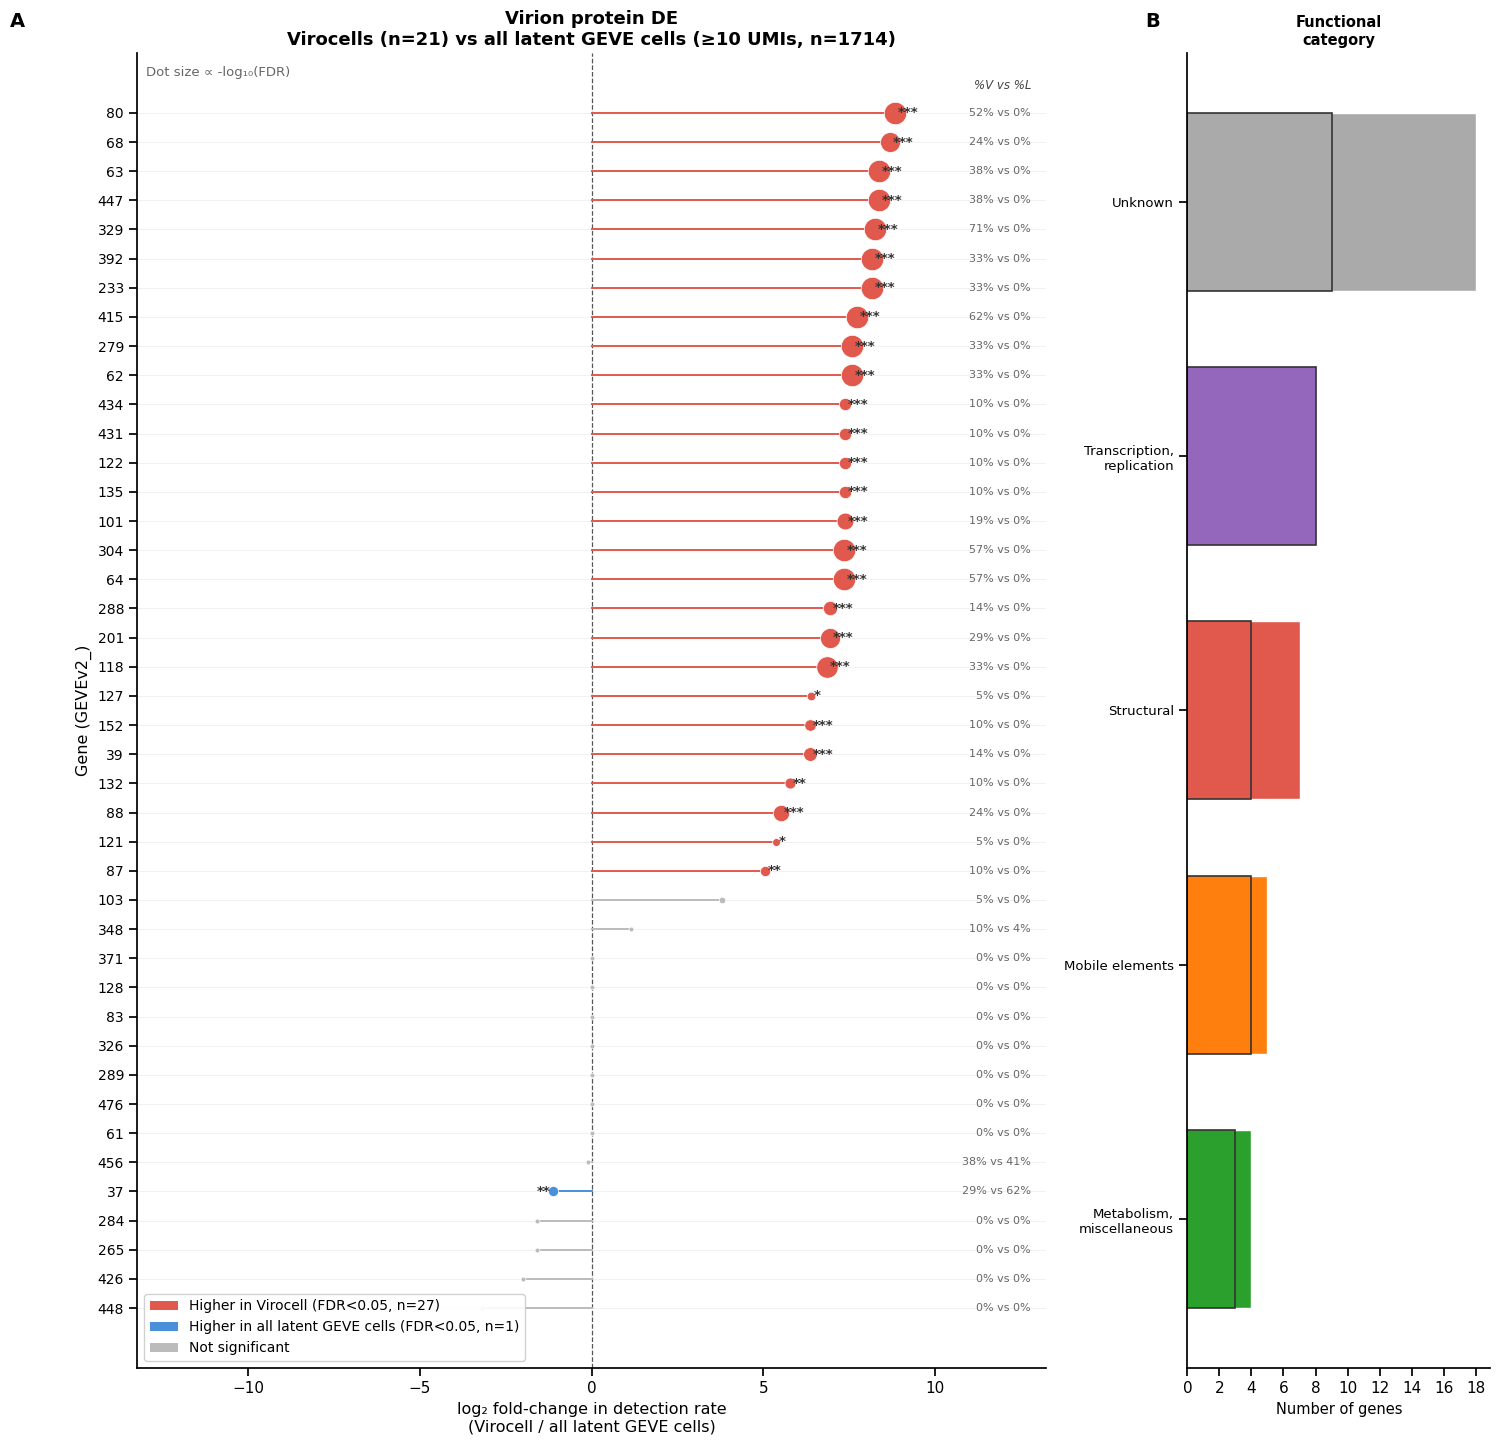

Appendix Figure 4 saved: AppFig4_virion_protein_detection.png/.pdf/.svg
  Sig up in Virocell: 27  |  Sig up in High-GEVE: 1


In [26]:
# -- PLOT: Appendix Figure 4 -- Virion Protein Gene DE: Virocells vs all latent GEVE cells (>=10) --
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

COLOR_SIG_V  = '#e1594d'   # significant, higher in Virocell
COLOR_SIG_HG = '#4a90d9'   # significant, higher in latent GEVE cell
COLOR_NS      = '#bbbbbb'   # not significant

FCAT_COLORS = {
    'Structural':                '#e1594d',
    'Transcription, replication': '#9467bd',
    'Metabolism, miscellaneous':  '#2ca02c',
    'Mobile elements':            '#ff7f0e',
    'Unknown':                    '#aaaaaa',
}

def _sig_color(row):
    if row['fdr'] < 0.05 and row['log2fc_detection'] > 0:
        return COLOR_SIG_V
    if row['fdr'] < 0.05 and row['log2fc_detection'] < 0:
        return COLOR_SIG_HG
    return COLOR_NS

de_plot = de_727.sort_values('log2fc_detection', ascending=True).reset_index(drop=True)
de_plot['_col']  = de_plot.apply(_sig_color, axis=1)
de_plot['_size'] = de_plot['fdr'].apply(
    lambda f: np.clip(-np.log10(max(f, 1e-15)) * 22, 12, 260))

fig, axes = plt.subplots(1, 2, figsize=(15, max(9, len(de_plot) * 0.30 + 2)),
                          gridspec_kw={'width_ratios': [3, 1]})
ax, ax_cat = axes

# -- Panel A: lollipop (log2FC of detection rate) --
for i, row in de_plot.iterrows():
    ax.plot([0, row['log2fc_detection']], [i, i],
            color=row['_col'], lw=1.4, zorder=1)
    ax.scatter(row['log2fc_detection'], i,
               s=row['_size'], color=row['_col'],
               zorder=2, edgecolors='white', linewidths=0.5)
    # FDR stars
    stars = ('***' if row['fdr'] < 0.001 else
             '**'  if row['fdr'] < 0.01  else
             '*'   if row['fdr'] < 0.05  else '')
    if stars:
        xpos = row['log2fc_detection']
        ha   = 'left' if xpos >= 0 else 'right'
        pad  = 0.08  if xpos >= 0 else -0.08
        ax.text(xpos + pad, i, stars, va='center', ha=ha,
                fontsize=9.5, color='#333333', fontweight='bold')

ax.axvline(0, color='#555555', lw=0.9, ls='--', zorder=0)
ax.set_yticks(range(len(de_plot)))
ax.set_yticklabels(de_plot['gene'].str.replace('GEVEv2_', '', regex=False), fontsize=10)
ax.set_ylabel('Gene (GEVEv2_)', fontsize=11.5)
ax.set_xlabel('log\u2082 fold-change in detection rate\n'
              '(Virocell / all latent GEVE cells)', fontsize=11.5)
ax.set_title(f'Virion protein DE\n'
             f'Virocells (n={n_viro_727}) vs all latent GEVE cells (≥10 UMIs, n={n_hg_727})',
             fontsize=13, fontweight='bold')
ax.yaxis.grid(True, alpha=0.25, lw=0.5)
ax.set_axisbelow(True)
for sp in ['top', 'right']:
    ax.spines[sp].set_visible(False)
ax.text(-0.14, 1.02, 'A', transform=ax.transAxes, fontsize=14, fontweight='bold')

# detection rate annotations on right margin of panel A
_xmax = max(abs(de_plot['log2fc_detection'].max()),
            abs(de_plot['log2fc_detection'].min()), 1.0)
ax.set_xlim(-_xmax * 1.5, _xmax * 1.5)
for i, row in de_plot.iterrows():
    ann = f"{row['pct_virocell']*100:.0f}% vs {row['pct_highgeve']*100:.0f}%"
    ax.text(_xmax * 1.45, i, ann, va='center', ha='right',
            fontsize=8, color='#666666')
ax.text(_xmax * 1.45, len(de_plot) - 0.3, '%V vs %L',
        va='bottom', ha='right', fontsize=8.5, color='#444444', fontstyle='italic')

# -- Panel B: functional category bars --
_fcat_counts = de_727.groupby('functional_cat').size().sort_values(ascending=True)
_fcat_sig    = de_727[de_727['fdr'] < 0.05].groupby('functional_cat').size()
_bar_y = range(len(_fcat_counts))
ax_cat.barh(_bar_y, _fcat_counts.values,
            color=[FCAT_COLORS.get(c, '#aaaaaa') for c in _fcat_counts.index],
            edgecolor='white', height=0.7)
ax_cat.barh(_bar_y, [_fcat_sig.get(c, 0) for c in _fcat_counts.index],
            color=[FCAT_COLORS.get(c, '#aaaaaa') for c in _fcat_counts.index],
            edgecolor='#333333', lw=1.2, height=0.7, alpha=1.0,
            label='FDR < 0.05 (outlined)')
ax_cat.set_yticks(_bar_y)
ax_cat.set_yticklabels([c.replace(', ', ',\n') for c in _fcat_counts.index], fontsize=9.5)
ax_cat.set_xlabel('Number of genes', fontsize=10.5)
ax_cat.set_title('Functional\ncategory', fontsize=10.5, fontweight='bold')
for sp in ['top', 'right']:
    ax_cat.spines[sp].set_visible(False)
ax_cat.text(-0.14, 1.02, 'B', transform=ax_cat.transAxes, fontsize=14, fontweight='bold')
ax_cat.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

# -- Legend --
leg_handles = [
    mpatches.Patch(fc=COLOR_SIG_V,  label=f'Higher in Virocell (FDR<0.05, n={len(_sig_up_v)})'),
    mpatches.Patch(fc=COLOR_SIG_HG, label=f'Higher in all latent GEVE cells (FDR<0.05, n={len(_sig_up_hg)})'),
    mpatches.Patch(fc=COLOR_NS,     label='Not significant'),
]
ax.legend(handles=leg_handles, fontsize=10, loc='lower left',
          framealpha=0.9, edgecolor='#cccccc')
ax.text(0.01, 0.99, 'Dot size \u221d -log\u2081\u2080(FDR)',
        transform=ax.transAxes, va='top', ha='left', fontsize=9.5, color='#666666')

plt.tight_layout()
plt.savefig(FIG_DIR / 'AppFig4_virion_protein_detection.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig4_virion_protein_detection.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig4_virion_protein_detection.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 4 saved: AppFig4_virion_protein_detection.png/.pdf/.svg')
print(f'  Sig up in Virocell: {len(_sig_up_v)}  |  Sig up in High-GEVE: {len(_sig_up_hg)}')


## Appendix Figure 5 and Supplementary Table 8. GEVE genomic feature categories distinguish the transcriptional states of virocells and High-GEVE latent cells

Pooled detection-rate Fisher tests per genomic feature category, with BH correction. The plot cell also writes Table S8.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig5_feature_category_enrichment.png`, `.pdf`, `.svg`
**File**: `tables/TableS8_GEVE_feature_enrichment.csv`

**Note**: the comparison group in the code is all High-GEVE (≥ 43 UMIs) non-Virocells (n = 27), not the 766 pro-virocells named in the manuscript legend. The per-gene test used by S4 compares Virocells with the top 21 High-GEVE non-Virocells.


In [27]:
# -- COMPUTE: Appendix Figure 5 -- GEVE genomic feature enrichment: Virocells vs High-GEVE latent cells --
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from pathlib import Path
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# ── DPI distribution check ────────────────────────────────────────────────────
_adata_sf10 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
_dpi_all_sf10 = _adata_sf10.obs['dpi']
_dpi_viro_sf10 = _dpi_all_sf10.loc[[bc for bc in _sel_bc_sf9 if bc in _viro_bc_sf9]]
_dpi_high_sf10 = _dpi_all_sf10.loc[[bc for bc in _sel_bc_sf9 if bc not in _viro_bc_sf9]]
print('DPI distribution:')
print('  Virocells  :', dict(_dpi_viro_sf10.value_counts().sort_index()))
print('  High-GEVE latent cell:', dict(_dpi_high_sf10.value_counts().sort_index()))

# ── Expression matrix for selected cells (log1p per-10k) ─────────────────────
_sub_sf10 = _adata_sf10[_sel_bc_sf9].copy()
del _adata_sf10
sc.pp.normalize_total(_sub_sf10, target_sum=1e4)
sc.pp.log1p(_sub_sf10)

_X_all_sf10 = _sub_sf10.X
if sp.issparse(_X_all_sf10): _X_all_sf10 = _X_all_sf10.toarray().astype(np.float32)
_var_names_sf10 = _sub_sf10.var_names.tolist()
_gene_type_sf10 = _sub_sf10.var['gene_type'].values
del _sub_sf10

_viro_mask_sf10 = cell_label_sf9 == 'Virocell'
_high_mask_sf10 = cell_label_sf9 == 'High-GEVE latent cell'
n_v, n_h = _viro_mask_sf10.sum(), _high_mask_sf10.sum()

# ── Fisher's exact DE helper ──────────────────────────────────────────────────
_canonical_genes_sf10 = set(gdf_track['gene'])   # 506 canonical genes; excludes relic loci

def _run_fisher(X, gene_names, gene_types, gtype_filter):
    sel = np.array([
        (t == gtype_filter) and (gtype_filter != 'GEVE' or gn in _canonical_genes_sf10)
        for t, gn in zip(gene_types, gene_names)
    ])
    Xg  = X[:, sel]
    gns = [gene_names[i] for i, s in enumerate(sel) if s]

    det_v = (Xg[_viro_mask_sf10] > 0).sum(axis=0)
    det_h = (Xg[_high_mask_sf10] > 0).sum(axis=0)

    rows = []
    for i, gene in enumerate(gns):
        a1, b1 = int(det_v[i]), int(det_h[i])
        if a1 + b1 == 0:
            continue
        a0, b0 = n_v - a1, n_h - b1
        _, pval = fisher_exact([[a1, a0], [b1, b0]], alternative='two-sided')
        lfc_det  = np.log2((a1/n_v + 0.5/n_v) / (b1/n_h + 0.5/n_h))
        lfc_expr = (Xg[_viro_mask_sf10, i].mean() - Xg[_high_mask_sf10, i].mean()) / np.log(2)
        rows.append(dict(gene=gene,
                         det_viro=a1, det_high=b1,
                         det_rate_viro=a1/n_v, det_rate_high=b1/n_h,
                         log2fc_det=lfc_det, log2fc_expr=lfc_expr, pval=pval))

    df = pd.DataFrame(rows)
    _, fdr, _, _ = multipletests(df['pval'], method='fdr_bh')
    df['fdr'] = fdr
    return df.sort_values('pval').reset_index(drop=True)

# ── Run DE ────────────────────────────────────────────────────────────────────
de_geve_sf10  = _run_fisher(_X_all_sf10, _var_names_sf10, _gene_type_sf10, 'GEVE')
de_chlamy_sf10 = _run_fisher(_X_all_sf10, _var_names_sf10, _gene_type_sf10, 'chlamy')
del _X_all_sf10

# Add gene annotations to GEVE results
_gt_de = gdf_track.set_index('gene')
de_geve_sf10['cluster']       = de_geve_sf10['gene'].map(lambda g: _gt_de.loc[g, 'cluster']        if g in _gt_de.index else 'Unclassified')
de_geve_sf10['has_ncldv_prom']= de_geve_sf10['gene'].map(lambda g: bool(_gt_de.loc[g, 'has_late_prom']) if g in _gt_de.index else False)
de_geve_sf10['has_6mA']       = de_geve_sf10['gene'].map(lambda g: bool(_gt_de.loc[g, 'has_6mA'])       if g in _gt_de.index else False)
de_geve_sf10['in_lytic']      = de_geve_sf10['gene'].isin(lytic_gene_set)
de_geve_sf10['in_latent']     = de_geve_sf10['gene'].isin(latent_gene_set)

n_sig_geve   = (de_geve_sf10['fdr']  < 0.05).sum()
n_sig_chlamy = (de_chlamy_sf10['fdr'] < 0.05).sum()
print(f'\nGEVE genes tested: {len(de_geve_sf10)}   significant (FDR<0.05): {n_sig_geve}')
print(f'Chlamy genes tested: {len(de_chlamy_sf10)}   significant (FDR<0.05): {n_sig_chlamy}')
print('\nTop GEVE hits:')
print(de_geve_sf10[['gene','cluster','in_lytic','log2fc_det','det_rate_viro','det_rate_high','fdr']].head(15).to_string(index=False))
print('\nTop Chlamy hits:')
print(de_chlamy_sf10[['gene','log2fc_det','det_rate_viro','det_rate_high','fdr']].head(10).to_string(index=False))
# GEVE annotation-based functional enrichment
from collections import defaultdict

_gdf_ann = gdf_track.set_index('gene')
_bg_set   = set(de_geve_sf10['gene'])
_up_set   = set(de_geve_sf10.loc[(de_geve_sf10['fdr']<0.05) & (de_geve_sf10['log2fc_det']>0), 'gene'])
_dn_set   = set(de_geve_sf10.loc[(de_geve_sf10['fdr']<0.05) & (de_geve_sf10['log2fc_det']<0), 'gene'])
_N_bg     = len(_bg_set)

_cat_genes_sf10 = defaultdict(set)
for _g in _bg_set:
    if _g not in _gdf_ann.index:
        continue
    _r = _gdf_ann.loc[_g]
    if pd.notna(_r.get('pfam_desc', None)):
        for _t in str(_r['pfam_desc']).split('|'):
            _t = _t.strip()
            if _t:
                _cat_genes_sf10[('PFAM', _t)].add(_g)
    if pd.notna(_r.get('gvog', None)):
        _cat_genes_sf10[('GVOG', str(_r['gvog']).strip())].add(_g)
    if pd.notna(_r.get('ncldv_marker', None)):
        _cat_genes_sf10[('NCLDV marker', str(_r['ncldv_marker']).strip())].add(_g)
    if pd.notna(_r.get('cog_cat', None)):
        for _c in str(_r['cog_cat']).strip():
            if _c.isalpha():
                _cat_genes_sf10[('COG', _c)].add(_g)

_cat_genes_sf10 = {k: v for k, v in _cat_genes_sf10.items() if len(v) >= 3}
print(f'Testable annotation categories (n>=3 genes in background): {len(_cat_genes_sf10)}')

_enr_rows_sf10 = []
for (_src, _term), _cat_bg in _cat_genes_sf10.items():
    for _dir, _qset in [('Up in Virocell', _up_set), ('Up in High-GEVE latent cell', _dn_set)]:
        _n_q = len(_qset)
        if _n_q == 0:
            continue
        _k = len(_qset & _cat_bg)
        _K = len(_cat_bg)
        _, _p = fisher_exact([[_k, _n_q-_k], [_K-_k, _N_bg-_n_q-(_K-_k)]], alternative='greater')
        _enr_rows_sf10.append({'source': _src, 'term': _term, 'direction': _dir,
                                'n_in': _k, 'n_cat': _K, 'pval': _p})

geve_enr_sf10 = pd.DataFrame(_enr_rows_sf10)
if len(geve_enr_sf10):
    _, geve_enr_sf10['fdr'], _, _ = multipletests(geve_enr_sf10['pval'], method='fdr_bh')
    geve_enr_sf10['log10p'] = -np.log10(geve_enr_sf10['pval'].clip(lower=1e-10))
    _sig_e = geve_enr_sf10[geve_enr_sf10['pval'] < 0.05].sort_values('pval')
    print(f'Enriched terms (p<0.05): {len(_sig_e)}')
    print(_sig_e[['source','term','direction','n_in','n_cat','pval']].head(20).to_string(index=False))


DPI distribution:
  Virocells  : {4: np.int64(1), 5: np.int64(3), 6: np.int64(12), 7: np.int64(5)}
  High-GEVE latent cell: {4: np.int64(21), 5: np.int64(0), 6: np.int64(0), 7: np.int64(0)}



GEVE genes tested: 315   significant (FDR<0.05): 26
Chlamy genes tested: 12018   significant (FDR<0.05): 3494

Top GEVE hits:
      gene cluster  in_lytic  log2fc_det  det_rate_viro  det_rate_high          fdr
  GEVEv2_1     BVP     False   -3.104337       0.095238       1.000000 2.961220e-07
 GEVEv2_38     BVP     False   -3.035624       0.095238       0.952381 2.716598e-06
GEVEv2_506     BVP     False   -2.550197       0.142857       0.952381 1.322678e-05
GEVEv2_213     DVP      True    4.954196       0.714286       0.000000 5.774379e-05
GEVEv2_329     DVP      True    4.954196       0.714286       0.000000 5.774379e-05
 GEVEv2_37     BVP     False   -1.725825       0.285714       1.000000 5.774379e-05
 GEVEv2_21     BVP     False   -3.459432       0.047619       0.761905 1.531374e-04
GEVEv2_262     DVP      True    4.754888       0.619048       0.000000 5.581900e-04
GEVEv2_415     NaN      True    4.754888       0.619048       0.000000 5.581900e-04
 GEVEv2_64     DVP      True    4

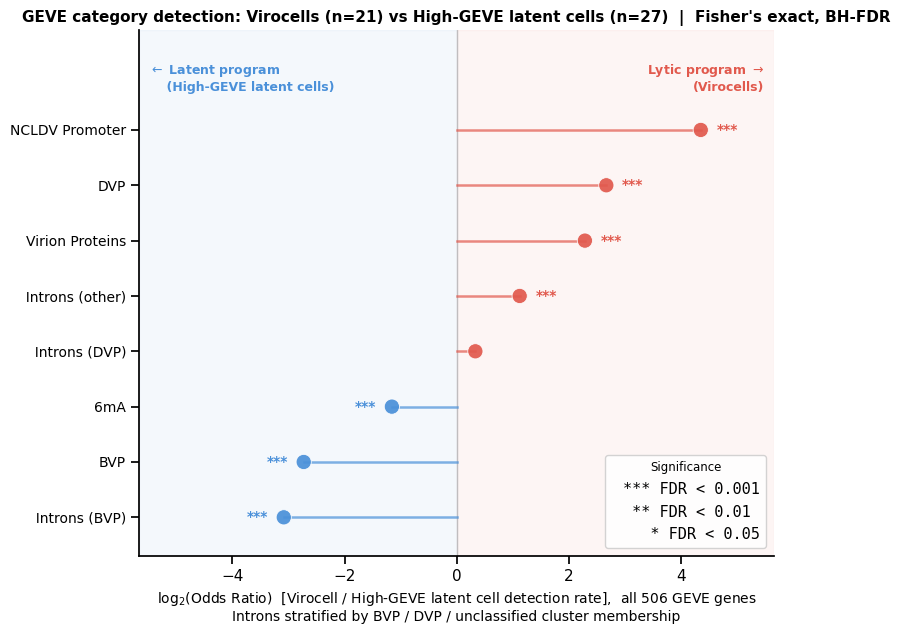

Appendix Figure 5 saved.
Table S8 -> tables/TableS8_GEVE_feature_enrichment.csv


In [28]:
# -- PLOT: Appendix Figure 5 -- GEVE genomic feature enrichment lollipop (single panel) --
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import numpy as np

VIRO_COLOR    = '#e1594d'
PROVIRO_COLOR = '#4a90d9'

# enrich_df_sf9 from pub_sf9_compute: OR > 1 = enriched in Cluster A
# Cluster A = latent GEVE cell (latent) program: BVP, 6mA, Introns
# Cluster B = Virocell (lytic) program:      DVP, NCLDV Promoter, Virion Proteins
_enr = enrich_df_sf9.copy()
_enr['log2OR'] = np.log2(_enr['OR'].clip(lower=1e-3))
_enr = _enr.sort_values('log2OR').reset_index(drop=True)

xlim       = max(abs(_enr['log2OR'].max()), abs(_enr['log2OR'].min())) * 1.30
dot_colors = [VIRO_COLOR if v > 0 else PROVIRO_COLOR for v in _enr['log2OR']]

fig, ax = plt.subplots(figsize=(8, 6.5))

ax.axvspan(-xlim, 0,    color=PROVIRO_COLOR, alpha=0.06, zorder=0)
ax.axvspan(0,     xlim, color=VIRO_COLOR,    alpha=0.06, zorder=0)

for i, row in _enr.iterrows():
    c = VIRO_COLOR if row['log2OR'] > 0 else PROVIRO_COLOR
    ax.plot([0, row['log2OR']], [i, i], color=c, lw=1.8, alpha=0.7, zorder=1)

ax.scatter(_enr['log2OR'], _enr.index, c=dot_colors,
           s=120, edgecolors='white', linewidths=0.6, zorder=2, alpha=0.92)

for i, row in _enr.iterrows():
    if row['sig'] != 'ns':
        xoff = xlim * 0.05 if row['log2OR'] >= 0 else -xlim * 0.05
        ha   = 'left' if row['log2OR'] >= 0 else 'right'
        c    = VIRO_COLOR if row['log2OR'] > 0 else PROVIRO_COLOR
        ax.text(row['log2OR'] + xoff, i, row['sig'],
                fontsize=10, ha=ha, va='center', fontweight='bold', color=c)

ax.axvline(0, color='grey', lw=1.0, ls='-', alpha=0.4, zorder=0)
ax.set_xlim(-xlim, xlim)
ax.set_ylim(-0.7, len(_enr) + 0.8)
ax.set_yticks(_enr.index)
_ylabels = [('  ' + c if c.startswith('Introns (') else c) for c in _enr['Category']]
ax.set_yticklabels(_ylabels, fontsize=10)
ax.set_xlabel('log$_2$(Odds Ratio)  [Virocell / High-GEVE latent cell detection rate],  all 506 GEVE genes\n'
              'Introns stratified by BVP / DVP / unclassified cluster membership', fontsize=10)
ax.set_title(
    f'GEVE category detection: Virocells (n={n_viro_sf9}) vs High-GEVE latent cells (n={n_all_pv_sf9})'
    "  |  Fisher's exact, BH-FDR",
    fontsize=11, fontweight='bold')

ax.text(-xlim * 0.97, len(_enr) - 0.35,
        '$\\leftarrow$ Latent program\n    (High-GEVE latent cells)',
        fontsize=9, color=PROVIRO_COLOR, fontweight='bold', va='bottom', ha='left')
ax.text( xlim * 0.97, len(_enr) - 0.35,
        'Lytic program $\\rightarrow$\n(Virocells)',
        fontsize=9, color=VIRO_COLOR, fontweight='bold', va='bottom', ha='right')

for sp in ['top', 'right']: ax.spines[sp].set_visible(False)

# Significance legend
_leg_handles = [
    mlines.Line2D([], [], color='none', label='*** FDR < 0.001'),
    mlines.Line2D([], [], color='none', label=' ** FDR < 0.01'),
    mlines.Line2D([], [], color='none', label='   * FDR < 0.05'),
]
ax.legend(handles=_leg_handles, fontsize=8.5, framealpha=0.85, loc='lower right',
          title='Significance', title_fontsize=8.5, handlelength=0,
          prop={'family': 'monospace'})

fig.tight_layout()

plt.savefig(FIG_DIR / 'AppFig5_feature_category_enrichment.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig5_feature_category_enrichment.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig5_feature_category_enrichment.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 5 saved.')

# -- Save Table S8 CSV ---------------------------------------------------------
_enr_out = enrich_df_sf9[['Category', 'n_genes', 'det_pct_pv', 'det_pct_viro', 'OR', 'FDR', 'sig']].copy()
_enr_out.columns = [
    'Category', 'N_genes',
    f'Det_pct_HighGEVE_latent_n{n_all_pv_sf9}',
    f'Det_pct_Virocell_n{n_viro_sf9}',
    'Odds_Ratio', 'FDR_BH', 'Significance'
]
_s5_path = TABLE_DIR / 'TableS8_GEVE_feature_enrichment.csv'
_enr_out.to_csv(_s5_path, index=False)
print(f'Table S8 -> {_s5_path.relative_to(BASE)}')


## Appendix Figure 3. Volcano plot of GEVE gene differential expression: Virocells versus top-21 High-GEVE latent cells

Per-gene detection log₂FC vs −log₁₀ FDR. It uses the per-gene test from the S6 compute cell above.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/AppFig3_GEVE_detection_volcano.png`, `.pdf`, `.svg`


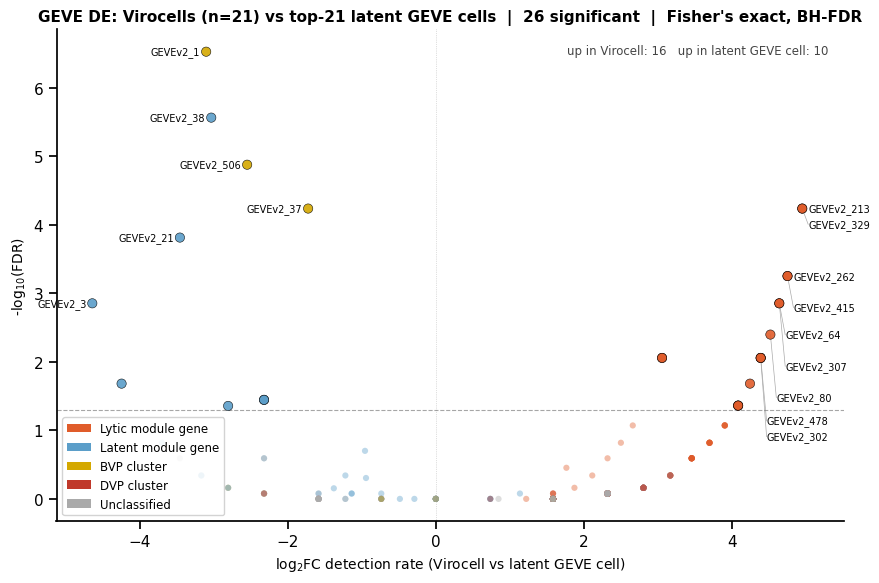

Appendix Figure 3 saved.


In [29]:
# -- PLOT: Appendix Figure 3 -- GEVE DE volcano: Virocells vs latent GEVE cells --
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

FDR_THRESH = 0.05
TOP_LABEL  = 15

CLUST_COL_S9 = {'BVP': '#d4a800', 'DVP': '#c0392b', 'Unclassified': '#aaaaaa'}

def _sf9_color(row):
    if row['in_lytic']:  return '#e05c2a'
    if row['in_latent']: return '#5b9ec9'
    return CLUST_COL_S9.get(row['cluster'], '#aaaaaa')

fig_s9, ax_s9 = plt.subplots(figsize=(9, 6))

_x9   = de_geve_sf10['log2fc_det'].values
_y9   = -np.log10(de_geve_sf10['fdr'].clip(lower=1e-10).values)
_sig9 = de_geve_sf10['fdr'].values < FDR_THRESH
_col9 = [_sf9_color(row) for _, row in de_geve_sf10.iterrows()]

ax_s9.scatter(_x9[~_sig9], _y9[~_sig9],
              c=[_col9[i] for i in range(len(_sig9)) if not _sig9[i]],
              s=20, alpha=0.4, linewidths=0, rasterized=True)
ax_s9.scatter(_x9[_sig9],  _y9[_sig9],
              c=[_col9[i] for i in range(len(_sig9)) if _sig9[i]],
              s=45, alpha=0.9, linewidths=0.4, edgecolors='black', zorder=3)

ax_s9.axhline(-np.log10(FDR_THRESH), color='grey', lw=0.8, ls='--', alpha=0.7)
ax_s9.axvline(0, color='grey', lw=0.5, ls=':', alpha=0.5)

_top9 = (de_geve_sf10[_sig9]
         .assign(_pri=de_geve_sf10[_sig9]['fdr'],
                 _sec=-de_geve_sf10[_sig9]['log2fc_det'].abs())
         .sort_values(['_pri', '_sec']).head(TOP_LABEL))

# Manual label de-overlap (no adjustText dependency): greedily stack labels that would
# collide vertically, per side of x=0, and draw a thin leader line back to the point.
_ylim9 = ax_s9.get_ylim()
_MIN_DY9 = 0.032 * (_ylim9[1] - _ylim9[0])
_placed9 = {'right': [], 'left': []}
for _, _row in _top9.sort_values('_pri').iterrows():
    _xi = _row['log2fc_det']
    _yi = -np.log10(max(_row['fdr'], 1e-10))
    _side = 'right' if _xi >= 0 else 'left'
    _y_lbl = _yi
    while any(abs(_y_lbl - _y_used) < _MIN_DY9 for _y_used in _placed9[_side]):
        _y_lbl -= _MIN_DY9
    _placed9[_side].append(_y_lbl)
    _xoff = 0.08 if _xi >= 0 else -0.08
    if abs(_y_lbl - _yi) > 1e-9:
        ax_s9.plot([_xi, _xi + _xoff], [_yi, _y_lbl], color='#aaaaaa', lw=0.5, zorder=1)
    ax_s9.text(_xi + _xoff, _y_lbl, _row['gene'], fontsize=7,
               va='center', ha='left' if _xi >= 0 else 'right', zorder=5)

ax_s9.set_xlabel('log$_2$FC detection rate (Virocell vs latent GEVE cell)', fontsize=10)
ax_s9.set_ylabel('-log$_{10}$(FDR)', fontsize=10)
_n_up9   = int((_sig9 & (_x9 > 0)).sum())
_n_down9 = int((_sig9 & (_x9 < 0)).sum())
ax_s9.set_title(
    f'GEVE DE: Virocells (n={n_viro_sf9}) vs top-{n_high_sf9} latent GEVE cells'
    f'  |  {int(_sig9.sum())} significant  |  Fisher\'s exact, BH-FDR',
    fontsize=11, fontweight='bold')
ax_s9.text(0.98, 0.97,
           f'up in Virocell: {_n_up9}   up in latent GEVE cell: {_n_down9}',
           transform=ax_s9.transAxes, fontsize=8.5,
           ha='right', va='top', color='#444444')
for sp in ['top', 'right']: ax_s9.spines[sp].set_visible(False)

_hnd9 = [
    mpatches.Patch(fc='#e05c2a', label='Lytic module gene'),
    mpatches.Patch(fc='#5b9ec9', label='Latent module gene'),
    mpatches.Patch(fc='#d4a800', label='BVP cluster'),
    mpatches.Patch(fc='#c0392b', label='DVP cluster'),
    mpatches.Patch(fc='#aaaaaa', label='Unclassified'),
]
ax_s9.legend(handles=_hnd9, fontsize=8.5, framealpha=0.85, loc='lower left')
fig_s9.tight_layout()

plt.savefig(FIG_DIR / 'AppFig3_GEVE_detection_volcano.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig3_GEVE_detection_volcano.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'AppFig3_GEVE_detection_volcano.svg', bbox_inches='tight')

plt.show()
print('Appendix Figure 3 saved.')


## Figure 3. Transcriptomic composition by GEVE activity state

GEVE, Chlamy and organellar UMI fractions per cell state (GEVE-background, GEVE-active, High-GEVE, Virocell), and GEVE vs Chlamy UMIs.

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `figures/Fig3_transcriptomic_composition.png`, `.pdf`, `.svg`


In [30]:
# -- COMPUTE: Figure 3 -- Transcriptomic composition by cell state --
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy import stats
from pathlib import Path

_adata_s10 = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')

# Cell state taxonomy: threshold-based Virocell (n=21, consistent with Figure S3 and Fig 2)
# Virocell = GEVE>=10 AND log2(lytic/latent)>0 AND GEVE/Chlamy>0.02
_lytic_genes = pd.Series(LYTIC_GENES).tolist()
_latent_genes = pd.Series(LATENT_GENES).tolist()
_lytic_g  = [g for g in _lytic_genes  if g in _adata_s10.var_names]
_latent_g = [g for g in _latent_genes if g in _adata_s10.var_names]

_geve_s10    = _adata_s10.obs['geve_raw'].values.copy()
_chlamy_g    = _adata_s10.var_names[_adata_s10.var['gene_type'] == 'chlamy']
_chlamy_umi  = np.array(_adata_s10[:, _chlamy_g].X.sum(axis=1)).flatten()
_lytic_mean  = np.array(_adata_s10[:, _lytic_g].X.mean(axis=1)).flatten()
_latent_mean = np.array(_adata_s10[:, _latent_g].X.mean(axis=1)).flatten()
_ratio_s10   = np.log2((_lytic_mean + 1) / (_latent_mean + 1))
_gc_ratio    = (_geve_s10 + 0.5) / (_chlamy_umi + 0.5)

# Cell-state taxonomy (UMI-threshold based, Virocell carved out by 3-criteria rule):
#   GEVE-background : GEVE UMIs < 10
#   GEVE-active     : 10 <= GEVE UMIs < 43, excluding Virocells
#   High-GEVE       : GEVE UMIs >= 43, excluding Virocells
#   Virocell        : GEVE >= 10, log2(lytic/latent) > 0, GEVE/Chlamy > 0.02  (n=21)
_HG_MIN  = HG_MIN   # 43, from the threshold compute cell
_is_viro = (_geve_s10 >= GEVE_MIN) & (_ratio_s10 > 0) & (_gc_ratio > 0.02)

_cs = pd.Series('GEVE-background', index=_adata_s10.obs_names)
_cs[(_geve_s10 >= GEVE_MIN) & (_geve_s10 < _HG_MIN) & ~_is_viro] = 'GEVE-active'
_cs[(_geve_s10 >= _HG_MIN) & ~_is_viro]                    = 'High-GEVE'
_cs[_is_viro]                                              = 'Virocell'
_adata_s10.obs['cell_state'] = pd.Categorical(
    _cs, categories=['GEVE-background', 'GEVE-active', 'High-GEVE', 'Virocell'], ordered=True)

# Gene-type UMI fractions
for _t in ['chlamy', 'GEVE', 'chloro', 'mito']:
    _genes = _adata_s10.var_names[_adata_s10.var['gene_type'] == _t]
    _raw   = _adata_s10[:, _genes].X.sum(axis=1)
    if hasattr(_raw, 'A1'): _raw = _raw.A1
    _adata_s10.obs[f'count_{_t}'] = np.asarray(_raw).ravel()
    _adata_s10.obs[f'pct_{_t}']   = (
        _adata_s10.obs[f'count_{_t}'] / _adata_s10.obs['total_counts'] * 100)

STATE_ORDER_s10  = ['GEVE-background', 'GEVE-active', 'High-GEVE', 'Virocell']
STATE_COLORS_s10 = {'GEVE-background': '#cccccc', 'GEVE-active': '#4a90d9',
                     'High-GEVE': '#f5a623', 'Virocell': '#e1594d'}
TYPE_COLORS_s10  = ['#aaaaaa', '#e1594d', '#2ca02c', '#9467bd']
TYPE_LABELS_s10  = ['Nuclear Chlamydomonas', 'GEVE (viral)', 'Chloroplast', 'Mitochondrial']

frac_by_state_s10 = (_adata_s10.obs
    .groupby('cell_state', observed=True)[['pct_chlamy','pct_GEVE','pct_chloro','pct_mito']]
    .mean()
    .loc[STATE_ORDER_s10])

obs_s10 = _adata_s10.obs[['cell_state','count_GEVE','count_chlamy','total_counts']].copy()
del _adata_s10

print('N cells per state:')
print(obs_s10['cell_state'].value_counts().loc[STATE_ORDER_s10].to_string())
print()
print('Mean UMI % by cell state:')
print(frac_by_state_s10.round(1).to_string())
print()
print('Spearman (GEVE vs Chlamy UMIs) by cell state:')
for _state in STATE_ORDER_s10:
    _sub = obs_s10[obs_s10['cell_state'] == _state]
    if len(_sub) < 5: continue
    _r, _p = stats.spearmanr(_sub['count_GEVE'], _sub['count_chlamy'])
    print(f'  {_state:<16} r={_r:+.3f}  p={_p:.2e}  n={len(_sub)}')


N cells per state:
cell_state
GEVE-background    20686
GEVE-active         1687
High-GEVE             27
Virocell              21

Mean UMI % by cell state:
                 pct_chlamy   pct_GEVE  pct_chloro  pct_mito
cell_state                                                  
GEVE-background   92.400002   0.400000         7.0       0.0
GEVE-active       90.300003   0.600000         8.9       0.1
High-GEVE         89.400002   0.600000         9.8       0.1
Virocell          78.400002  17.299999         4.2       0.0

Spearman (GEVE vs Chlamy UMIs) by cell state:
  GEVE-background  r=+0.697  p=0.00e+00  n=20686
  GEVE-active      r=+0.637  p=1.90e-192  n=1687
  High-GEVE        r=+0.328  p=9.53e-02  n=27
  Virocell         r=+0.335  p=1.38e-01  n=21


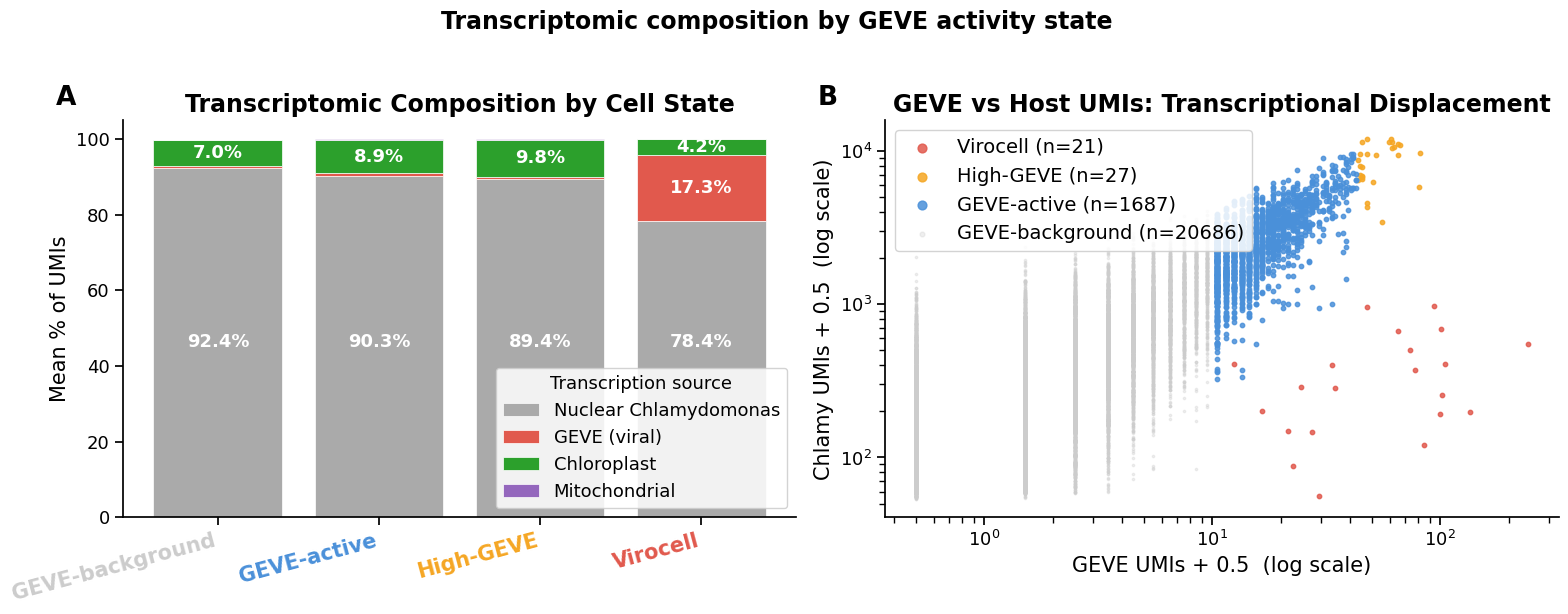

Figure 3 saved.


In [31]:
# -- PLOT: Figure 3 -- Transcriptomic composition by cell state --
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: stacked bar of mean UMI fractions
ax = axes[0]
bottom = np.zeros(len(STATE_ORDER_s10))
for col, color, label in zip(
        ['pct_chlamy', 'pct_GEVE', 'pct_chloro', 'pct_mito'],
        TYPE_COLORS_s10, TYPE_LABELS_s10):
    vals = frac_by_state_s10[col].values
    ax.bar(range(len(STATE_ORDER_s10)), vals, bottom=bottom,
           color=color, label=label, edgecolor='white', linewidth=0.5)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 2:
            # Nuclear Chlamydomonas label height is fixed to the GEVE-background
            # bar's segment center so all four bars' numbers line up (the Virocell
            # segment is shorter and its own center would collide with the legend).
            y_text = vals[0] / 2 if col == 'pct_chlamy' else b + v / 2
            ax.text(i, y_text, f'{v:.1f}%',
                    ha='center', va='center', fontsize=13,
                    color='white', fontweight='bold')
    bottom += vals
ax.set_xticks(range(len(STATE_ORDER_s10)))
ax.set_xticklabels(STATE_ORDER_s10, rotation=15, ha='right', fontsize=15)
for tick, state in zip(ax.get_xticklabels(), STATE_ORDER_s10):
    tick.set_color(STATE_COLORS_s10[state])
    tick.set_fontweight('bold')
ax.set_ylabel('Mean % of UMIs', fontsize=15)
ax.set_title('Transcriptomic Composition by Cell State', fontsize=17, fontweight='bold')
ax.legend(fontsize=13, loc='lower right', framealpha=0.85,
          title='Transcription source', title_fontsize=13)
ax.tick_params(axis='y', labelsize=13)
ax.spines[['top', 'right']].set_visible(False)
ax.text(-0.10, 1.04, 'A', transform=ax.transAxes, fontsize=19, fontweight='bold')

# Panel B: GEVE vs Chlamy UMI scatter (log scale)
ax = axes[1]
for state in STATE_ORDER_s10[::-1]:
    mask = obs_s10['cell_state'] == state
    ax.scatter(obs_s10.loc[mask, 'count_GEVE'] + 0.5,
               obs_s10.loc[mask, 'count_chlamy'] + 0.5,
               c=STATE_COLORS_s10[state],
               s=3 if state == 'GEVE-background' else 10,
               alpha=0.3 if state == 'GEVE-background' else 0.85,
               label=f'{state} (n={mask.sum()})',
               zorder=3 if state == 'Virocell' else 1,
               rasterized=True)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('GEVE UMIs + 0.5  (log scale)', fontsize=15)
ax.set_ylabel('Chlamy UMIs + 0.5  (log scale)', fontsize=15)
ax.set_title('GEVE vs Host UMIs: Transcriptional Displacement', fontsize=17, fontweight='bold')
ax.legend(fontsize=14, markerscale=2, loc='upper left', framealpha=0.85)
ax.tick_params(axis='both', labelsize=13)
ax.spines[['top', 'right']].set_visible(False)
ax.text(-0.10, 1.04, 'B', transform=ax.transAxes, fontsize=19, fontweight='bold')

fig.suptitle('Transcriptomic composition by GEVE activity state',
             fontsize=17, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'Fig3_transcriptomic_composition.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'Fig3_transcriptomic_composition.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'Fig3_transcriptomic_composition.svg', bbox_inches='tight')

plt.show()
print('Figure 3 saved.')


## Figure 3 robustness (STAR Methods, "Transcriptional displacement analysis"): depth-corrected host displacement

Partial Spearman correlation controlling for depth, and regression-residual tests. Their statistics are quoted in the Methods.

**Source**: `GEVE_manuscript_figures.ipynb`

**File**: — (no figure; values used downstream)


In [32]:
# -- COMPUTE: Figure 3 (robustness check) -- depth-corrected host transcript displacement --
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

df_disp = obs_s10.rename(columns={'count_GEVE': 'geve_umi', 'count_chlamy': 'chlamy_umi',
                                   'total_counts': 'total_umi'}).copy()
df_disp['pct_chlamy'] = df_disp['chlamy_umi'] / df_disp['total_umi']

# ---- Analysis 1: Mann-Whitney U on host UMI fraction, High-GEVE vs Virocell ----
hg_pct = df_disp.loc[df_disp.cell_state == 'High-GEVE', 'pct_chlamy']
vc_pct = df_disp.loc[df_disp.cell_state == 'Virocell',  'pct_chlamy']
u1, p1 = stats.mannwhitneyu(hg_pct, vc_pct, alternative='two-sided')
rbc1 = 1 - (2 * u1) / (len(hg_pct) * len(vc_pct))

print('=== Analysis 1: host UMI fraction, High-GEVE vs Virocell (Mann-Whitney U) ===')
print(f'n(High-GEVE)={len(hg_pct)}, n(Virocell)={len(vc_pct)}')
print(f'median host fraction: High-GEVE={hg_pct.median():.3f}  Virocell={vc_pct.median():.3f}')
print(f'U={u1:.0f}, p={p1:.2e}, rank-biserial r={rbc1:+.3f}')
print()

# ---- Analysis 2: partial Spearman correlation (GEVE vs Chlamy | total_umi) ----
def _partial_spearman(x, y, z):
    xr, yr, zr = stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)
    xres = xr - np.polyval(np.polyfit(zr, xr, 1), zr)
    yres = yr - np.polyval(np.polyfit(zr, yr, 1), zr)
    return stats.spearmanr(xres, yres)

def _perm_partial_spearman(x, y, z, n_perm=10000, seed=0):
    rng = np.random.default_rng(seed)
    r_obs, _ = _partial_spearman(x, y, z)
    x = np.asarray(x)
    count = sum(abs(_partial_spearman(rng.permutation(x), y, z)[0]) >= abs(r_obs)
                for _ in range(n_perm))
    return r_obs, (count + 1) / (n_perm + 1)

print('=== Analysis 2: partial Spearman correlation, GEVE vs Chlamy UMIs | total_umi ===')
for state in ['High-GEVE', 'Virocell']:
    sub = df_disp[df_disp.cell_state == state]
    r_a, p_a = _partial_spearman(sub['geve_umi'], sub['chlamy_umi'], sub['total_umi'])
    r_p, p_p = _perm_partial_spearman(sub['geve_umi'].values, sub['chlamy_umi'].values,
                                       sub['total_umi'].values, n_perm=10000, seed=0)
    print(f'{state:<12} n={len(sub):3d}  partial_r={r_a:+.3f}  '
          f'p(asymptotic)={p_a:.2e}  p(permutation,10000x)={p_p:.2e}')
print()

# ---- Analysis 3: expected-vs-observed host UMI regression residual ----
baseline_disp = df_disp[df_disp.cell_state.isin(['GEVE-background', 'GEVE-active'])]
X_base = sm.add_constant(np.log1p(baseline_disp['total_umi']))
y_base = np.log1p(baseline_disp['chlamy_umi'])
model_disp = sm.OLS(y_base, X_base).fit()

X_all_disp = sm.add_constant(np.log1p(df_disp['total_umi']))
df_disp['chlamy_residual'] = np.log1p(df_disp['chlamy_umi']) - model_disp.predict(X_all_disp)

hg_resid = df_disp.loc[df_disp.cell_state == 'High-GEVE', 'chlamy_residual']
vc_resid = df_disp.loc[df_disp.cell_state == 'Virocell',  'chlamy_residual']
u3, p3 = stats.mannwhitneyu(hg_resid, vc_resid, alternative='two-sided')
rbc3 = 1 - (2 * u3) / (len(hg_resid) * len(vc_resid))
w_vc, pw_vc = stats.wilcoxon(vc_resid)

print('=== Analysis 3: expected-vs-observed host UMI count (OLS residual) ===')
print(f'baseline fit (GEVE-background+active, n={len(baseline_disp)}): '
      f'log1p(chlamy)={model_disp.params.iloc[0]:.3f} + {model_disp.params.iloc[1]:.3f}*log1p(total_umi), '
      f'R2={model_disp.rsquared:.4f}')
print(f'median residual: High-GEVE={hg_resid.median():+.3f}  Virocell={vc_resid.median():+.3f}')
print(f'High-GEVE vs Virocell: U={u3:.0f}, p={p3:.2e}, rank-biserial r={rbc3:+.3f}')
print(f'Virocell residuals vs 0 (one-sample Wilcoxon): W={w_vc:.0f}, p={pw_vc:.2e}, n={len(vc_resid)}')


=== Analysis 1: host UMI fraction, High-GEVE vs Virocell (Mann-Whitney U) ===
n(High-GEVE)=27, n(Virocell)=21
median host fraction: High-GEVE=0.892  Virocell=0.800
U=504, p=4.83e-06, rank-biserial r=-0.778

=== Analysis 2: partial Spearman correlation, GEVE vs Chlamy UMIs | total_umi ===


High-GEVE    n= 27  partial_r=+0.097  p(asymptotic)=6.30e-01  p(permutation,10000x)=5.74e-01


Virocell     n= 21  partial_r=-0.736  p(asymptotic)=1.41e-04  p(permutation,10000x)=5.00e-04

=== Analysis 3: expected-vs-observed host UMI count (OLS residual) ===
baseline fit (GEVE-background+active, n=22373): log1p(chlamy)=-0.056 + 0.996*log1p(total_umi), R2=0.9991
median residual: High-GEVE=-0.019  Virocell=-0.136
High-GEVE vs Virocell: U=518, p=1.16e-06, rank-biserial r=-0.827
Virocell residuals vs 0 (one-sample Wilcoxon): W=2, p=2.86e-06, n=21


## Supplementary Tables S1–S8

Builds every supplementary table from the source data in `data/` (gene annotation, FIMO hits, virion proteome) and from the S5/S8 statistics computed above. Each table is written as CSV, and all eight are combined into one formatted workbook with a Contents sheet (titles and legends).

**Source**: `GEVE_manuscript_figures.ipynb`

**Files**: `tables/TableS1_GEVE_gene_annotation.csv` … `tables/TableS8_GEVE_feature_enrichment.csv`, `tables/GEVE_supplementary_tables.xlsx`

In [33]:
# -- COMPUTE: Supplementary Tables S1–S8 (CSV + formatted xlsx) --
import numpy as np
import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.utils import get_column_letter

_a = pd.read_excel(BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx', sheet_name='GEVEv2_full_ano')
_a = _a.rename(columns={'Unnamed: 0': 'gene_num'}).sort_values('gene_num').reset_index(drop=True)
_a.loc[_a['strand'] == 'g', 'strand'] = '+'

# Virion proteome: coordinate match to ViralRecall protein IDs (same mapping as c003)
_vr = pd.read_csv(VIRION_CSV)
_smap = dict(zip(_vr['start_in_complete_contig_536'], _vr['protein_ids']))
_emap = dict(zip(_vr['end_in_complete_contig_536'], _vr['protein_ids']))
_pacc = [_smap.get(int(s), _emap.get(int(e))) for s, e in zip(_a['start'], _a['end'])]
_virion_acc = set(_vr.loc[_vr['detected_in_virion_proteome'], 'protein_ids'])

with open(BASE / 'data' / 'GEVE_promoters' / 'late_promoter_fimo_q05.txt') as fh:
    _prom = set(line.strip() for line in fh if line.strip())

# ---- S1: all 506 canonical GEVE genes
s1 = pd.DataFrame({
    'Gene_ID': _a['gene'], 'Gene_number': _a['gene_num'], 'Contig': _a['contig'],
    'Start': _a['start'], 'End': _a['end'], 'Strand': _a['strand'],
    'BVP_DVP_cluster': _a['cluster'].fillna('Unclassified'),
    'Has_6mA_methylation': _a['mod_6mA'].eq('yes'),
    'Has_spliceosomal_intron': (_a['introns'].eq('yes') & ~_a['gene'].isin(SELF_SPLICING_INTRON_GENES)).astype(object),
    'introns_per_gene': _a['introns_per_gene'].fillna(0).astype(int),
    'Has_NCLDV_promoter_FIMO_q05': _a['gene'].isin(_prom),
    'Is_virion_structural_protein': pd.Series(_pacc).isin(_virion_acc),
    'Virion_protein_accession': _pacc,
    'NCLDV_marker': _a['ncldv_marker'], 'Pfam_domain': _a['pfam_desc'], 'GVOG_family': _a['gvog'],
    'EggNOG_description': _a['eggnog_desc'], 'HHpred_top_hit': _a['top_descriptions'],
})
# MCP (GEVEv2_329) carries a group IC1 self-splicing intron: flagged, but not in the spliceosomal intron set
s1.loc[s1['Gene_ID'].isin(SELF_SPLICING_INTRON_GENES), 'Has_spliceosomal_intron'] = 'Self-splicing intron'

_core = ['Gene_ID', 'Gene_number', 'BVP_DVP_cluster', 'Contig', 'Start', 'End', 'Strand']
_ann_cols = ['NCLDV_marker', 'Pfam_domain', 'GVOG_family', 'EggNOG_description', 'HHpred_top_hit']
# ---- S2: spliceosomal-intron genes; S3: 6mA genes; S4: BVP/DVP genes
s2 = s1[s1['Has_spliceosomal_intron'].eq(True)][
    _core + ['introns_per_gene', 'Has_6mA_methylation', 'Has_NCLDV_promoter_FIMO_q05',
             'Is_virion_structural_protein'] + _ann_cols].reset_index(drop=True)
s3 = s1[s1['Has_6mA_methylation']][
    _core + ['Has_spliceosomal_intron', 'Has_NCLDV_promoter_FIMO_q05', 'Is_virion_structural_protein']
    + _ann_cols].reset_index(drop=True)
s4 = s1[s1['BVP_DVP_cluster'].isin(['BVP', 'DVP'])].sort_values(['BVP_DVP_cluster', 'Gene_number'])[
    _core + ['Has_6mA_methylation', 'Has_spliceosomal_intron', 'Has_NCLDV_promoter_FIMO_q05',
             'Is_virion_structural_protein'] + _ann_cols].reset_index(drop=True)

# ---- S5: pairwise co-occurrence (computed in c005 / written in c008)
s5 = pd.read_csv(TABLE_DIR / 'TableS5_pairwise_feature_cooccurrence.csv')

# ---- S6: NCLDV late-promoter genes, best FIMO hit (lowest p) per gene
_fimo = pd.read_csv(BASE / 'data' / 'GEVE_promoters' / 'fimo.tsv', sep='\t', comment='#')
_fimo = _fimo[_fimo['q-value'] < 0.05].sort_values('p-value').drop_duplicates('sequence_name')
assert set(_fimo['sequence_name']) == _prom
_s1i = s1.set_index('Gene_ID')
s6 = pd.DataFrame({'Gene_ID': _fimo['sequence_name'].values})
s6['BVP_DVP_cluster'] = s6['Gene_ID'].map(_s1i['BVP_DVP_cluster'])
for _new, _old in [('Motif_ID', 'motif_id'), ('Hit_strand', 'strand'), ('FIMO_score', 'score'),
                   ('FIMO_p_value', 'p-value'), ('FIMO_q_value', 'q-value'), ('Matched_sequence', 'matched_sequence')]:
    s6[_new] = _fimo[_old].values
s6['Is_virion_protein'] = s6['Gene_ID'].map(_s1i['Is_virion_structural_protein'])
for _c in ['NCLDV_marker', 'Pfam_domain', 'GVOG_family']:
    s6[_c] = s6['Gene_ID'].map(_s1i[_c])
s6 = s6.sort_values('Gene_ID').reset_index(drop=True)

# ---- S7: virion structural protein genes
_v = s1[s1['Is_virion_structural_protein']]
s7 = pd.DataFrame({
    'Gene_ID': _v['Gene_ID'], 'Gene_number': _v['Gene_number'], 'Start': _v['Start'], 'End': _v['End'],
    'Strand': _v['Strand'], 'BVP_DVP_cluster': _v['BVP_DVP_cluster'],
    'Has_NCLDV_promoter': _v['Has_NCLDV_promoter_FIMO_q05'], 'Has_6mA': _v['Has_6mA_methylation'],
    'Has_intron': _v['Has_spliceosomal_intron'], 'Virion_protein_accession': _v['Virion_protein_accession'],
    'NCLDV_marker': _v['NCLDV_marker'], 'Pfam_domain': _v['Pfam_domain'], 'GVOG_family': _v['GVOG_family'],
    'EggNOG_description': _v['EggNOG_description']}).reset_index(drop=True)

# ---- S8: feature enrichment, virocells vs High-GEVE latent (written in c041)
s8 = pd.read_csv(TABLE_DIR / 'TableS8_GEVE_feature_enrichment.csv')[
    ['Category', 'N_genes', 'Det_pct_Virocell_n21', 'Det_pct_HighGEVE_latent_n27', 'Odds_Ratio', 'FDR_BH', 'Significance']]

N_INTRON = len(s2)
N_INTRON_6MA = int(s2['Has_6mA_methylation'].sum())
N_INTRON_BVP = int(s2['BVP_DVP_cluster'].eq('BVP').sum())
assert (len(s1), N_INTRON, len(s3), len(s4), len(s6), len(s7)) == (506, 61, 53, 181, 105, 42)
assert s7['Has_6mA'].sum() == 0

_WORDS = 'Zero One Two Three Four Five Six Seven Eight Nine Ten Eleven Twelve Thirteen Fourteen'.split()
_pairs = lambda d: ', '.join(f'{a}–{b}' for a, b in zip(d['Feature A'], d['Feature B']))
_sig = s5[s5['Significant']]
_pos, _neg = _sig[_sig['Odds Ratio'] > 1], _sig[_sig['Odds Ratio'] < 1]
S5_SIG_TEXT = (f"{_WORDS[len(_sig)]} of 14 pairs reach significance at q < 0.05: {_WORDS[len(_pos)].lower()} positive "
               f"associations ({_pairs(_pos)}) and {_WORDS[len(_neg)].lower()} negative associations ({_pairs(_neg)}).")

# ---- titles and legends: (csv name, sheet name, table, title, legend)
SUPP_TABLES = [
    ('TableS1_GEVE_gene_annotation', 'Table S1 - GEVE Gene Annotation', s1,
     'Supplementary Table 1. Complete annotation of the 506 canonical GEVE genes.',
     'Each row is one annotated GEVE gene. Columns: genomic coordinates (contig, start, end, strand), BVP/DVP cluster '
     'assignment, binary feature flags (6mA modification [ONT], spliceosomal intron, NCLDV-type late promoter [FIMO q < 0.05], '
     'virion structural protein [LC-MS/MS]), number of introns per gene, virion protein accession, and functional annotations (NCLDV marker, Pfam '
     'domain, GVOG family, EggNOG description, HHpred top hit). The major capsid protein gene (GEVEv2_329) carries a '
     "group IC1 self-splicing intron rather than a spliceosomal intron (marked 'Self-splicing intron'); it is not "
     f'counted among the {N_INTRON} spliceosomal-intron genes.'),
    ('TableS2_intron_genes', 'Table S2 - Intron Genes', s2,
     'Supplementary Table 2. GEVE genes bearing spliceosomal introns.',
     f'The {N_INTRON} GEVE genes containing spliceosomal introns. The major capsid protein gene (GEVEv2_329), which '
     'carries a group IC1 self-splicing intron, is not included (see Table S1). Columns: BVP/DVP/Unclassified cluster '
     'assignment, genomic coordinates, number of introns per gene, 6mA modification flag, NCLDV-type late promoter motif '
     f'(FIMO q < 0.05), virion structural protein flag, and functional annotations. Of {N_INTRON} intron-bearing genes, '
     f'{N_INTRON_6MA} also carry 6mA modification and {N_INTRON_BVP} are in the BVP cluster, consistent with '
     'co-enrichment of introns with the latent gene program.'),
    ('TableS3_6mA_genes', 'Table S3 - 6mA Genes', s3,
     'Supplementary Table 3. GEVE genes bearing N6-methyladenine (6mA) modification.',
     f'The {len(s3)} GEVE genes with upstream N6-methyladenine (6mA) modification, called from Oxford Nanopore Technologies '
     '(ONT) reads (> 50% modified in the GEVE+ isolates G1 and G2; see STAR Methods). Columns: BVP/DVP/Unclassified '
     'cluster assignment, genomic coordinates, spliceosomal intron flag, NCLDV-type late promoter motif (FIMO q < 0.05), '
     'virion structural protein flag, and functional annotations.'),
    ('TableS4_BVP_DVP_genes', 'Table S4 - BVP DVP Genes', s4,
     'Supplementary Table 4. BVP and DVP cluster gene list.',
     f"All {len(s4)} GEVE genes assigned to the Before Viral Production (BVP; n = {s4['BVP_DVP_cluster'].eq('BVP').sum()}) "
     f"or During Viral Production (DVP; n = {s4['BVP_DVP_cluster'].eq('DVP').sum()}) transcriptional cluster "
     '(Erazo-Garcia et al. 2025). Binary feature flags: 6mA modification, spliceosomal '
     'intron, NCLDV-type late promoter motif (FIMO q < 0.05), virion structural protein identity. Functional '
     'annotations: NCLDV marker, Pfam domain, GVOG family, EggNOG description, HHpred top hit. The MCP gene '
     "(GEVEv2_329) is marked 'Self-splicing intron' in the intron column."),
    ('TableS5_pairwise_feature_cooccurrence', 'Table S5 - Co-occurrence Stats', s5,
     "Supplementary Table 5. Pairwise Fisher's exact test statistics for co-occurrence of six binary GEVE genomic "
     'features.',
     'All non-exclusive combinations of BVP, DVP, 6mA, Introns, NCLDV Promoter, and Virion Proteins across 506 annotated '
     'GEVE genes (14 tested pairs; BVP vs. DVP excluded as mutually exclusive). Columns: co-occurrence count n(A & B), '
     'marginal counts, odds ratio, raw two-sided p-value, and BH-FDR-corrected q-value. Introns = spliceosomal '
     f'introns ({N_INTRON} genes; the MCP self-splicing intron is excluded). ' + S5_SIG_TEXT),
    ('TableS6_NCLDV_promoter_genes', 'Table S6 - NCLDV Promoter Genes', s6,
     'Supplementary Table 6. GEVE genes bearing an NCLDV-type late promoter motif, identified by FIMO.',
     f'The {len(s6)} GEVE genes with a significant FIMO hit (q < 0.05, BH-FDR) for the STREME-1 motif (consensus '
     'AAANAACATAAG; 12 bp) upstream of each gene (see STAR Methods). Columns: Gene ID, BVP/DVP/Unclassified cluster, '
     'motif ID, hit strand, FIMO score, p-value, q-value, matched sequence, virion structural protein flag, and '
     'functional annotations.'),
    ('TableS7_virion_protein_genes', 'Table S7 - Virion Protein Genes', s7,
     'Supplementary Table 7. GEVE virion structural protein genes identified by LC-MS/MS proteomics.',
     f'The {len(s7)} GEVE genes encoding proteins detected in isolated GEVE virions by LC-MS/MS (Erazo-Garcia et al. 2025). '
     'Columns: Gene ID, coordinates, strand, BVP/DVP/Unclassified cluster, NCLDV-type late promoter flag, 6mA '
     "modification flag, spliceosomal intron flag (the MCP gene GEVEv2_329 is marked 'Self-splicing intron'), virion "
     'protein accession, and functional annotations. No virion protein gene carries 6mA modification.'),
    ('TableS8_GEVE_feature_enrichment', 'Table S8 - Feature Enrichment', s8,
     'Supplementary Table 8. GEVE genomic feature enrichment: virocells versus High-GEVE latent cells.',
     'Detection-rate enrichment of eight GEVE genomic feature categories in 21 virocells versus 27 High-GEVE latent '
     'cells (GEVE ≥ 43 UMIs, not meeting the virocell criteria; all from DPI 4), tested across all 506 canonical GEVE '
     "genes using Fisher's exact test with Benjamini-Hochberg FDR correction across all 8 tests. Intron-bearing genes "
     'are split by BVP-cluster, DVP-cluster, or unclassified membership. Columns: Category, n genes, detection % in '
     'virocells, detection % in High-GEVE latent cells, odds ratio (virocell / High-GEVE latent detection), FDR, '
     'significance (*** FDR < 0.001, ** < 0.01, * < 0.05, ns). OR > 1 = enriched in virocells (lytic program); '
     'OR < 1 = enriched in High-GEVE latent cells (latent program).'),
]

# ---- write CSVs
for _csv, _sheet, _df, _title, _legend in SUPP_TABLES:
    _df.to_csv(TABLE_DIR / f'{_csv}.csv', index=False)

# ---- write the formatted workbook
_SCI = {'p-value', 'q-value (BH)', 'FIMO_p_value', 'FIMO_q_value', 'FDR_BH'}
_BOLD, _HFILL, _THIN = Font(bold=True), PatternFill('solid', fgColor='D9D9D9'), Border(bottom=Side(style='thin'))
wb = Workbook()
ws = wb.active
ws.title = 'Contents'
ws['A1'] = 'Supplementary Tables'
ws['A1'].font = Font(bold=True, size=14)
ws['A2'] = ('Cell groups and GEVE gene sets follow the analysis notebook (GEVE_manuscript_figures.ipynb) '
            'and the GEVE annotation of 2026-09-29. Boolean flags: TRUE/FALSE. Empty cells: no annotation available.')
ws['A2'].alignment = Alignment(wrap_text=True, vertical='top')
ws.merge_cells('A2:D2')
ws.row_dimensions[2].height = 30
for j, h in enumerate(['Table', 'Sheet', 'Title', 'Legend'], 1):
    c = ws.cell(row=4, column=j, value=h)
    c.font, c.fill = _BOLD, _HFILL
for i, (_csv, _sheet, _df, _title, _legend) in enumerate(SUPP_TABLES, 5):
    for j, v in enumerate([f'S{i - 4}', _sheet, _title.split('. ', 1)[1], _legend], 1):
        ws.cell(row=i, column=j, value=v).alignment = Alignment(wrap_text=True, vertical='top')
for col, w in zip('ABCD', [7, 32, 45, 110]):
    ws.column_dimensions[col].width = w
ws.freeze_panes = 'A5'

for _csv, _sheet, _df, _title, _legend in SUPP_TABLES:
    w = wb.create_sheet(_sheet)
    w['A1'] = _title
    w['A1'].font = Font(bold=True, size=12)
    for j, col in enumerate(_df.columns, 1):
        c = w.cell(row=2, column=j, value=col)
        c.font, c.fill, c.border = _BOLD, _HFILL, _THIN
    for i, rec in enumerate(_df.itertuples(index=False), 3):
        for j, v in enumerate(rec, 1):
            if isinstance(v, float) and np.isnan(v):
                v = None
            elif isinstance(v, np.generic):
                v = v.item()
            c = w.cell(row=i, column=j, value=v)
            if _df.columns[j - 1] in _SCI and v is not None:
                c.number_format = '0.00E+00'
            elif _df.columns[j - 1] in ('Odds Ratio', 'Odds_Ratio') and v is not None:
                c.number_format = '0.000'
    for j, col in enumerate(_df.columns, 1):
        vals = [len(str(col))] + [len(str(x)) for x in _df.iloc[:, j - 1].head(200) if pd.notna(x)]
        w.column_dimensions[get_column_letter(j)].width = min(max(vals) + 2, 60)
    w.freeze_panes = 'B3'
    w.auto_filter.ref = f'A2:{get_column_letter(_df.shape[1])}{_df.shape[0] + 2}'

wb.save(TABLE_DIR / 'GEVE_supplementary_tables.xlsx')
for _csv, _sheet, _df, *_ in SUPP_TABLES:
    print(f'{_sheet:34} {_df.shape}  -> tables/{_csv}.csv')
print('Workbook saved: tables/GEVE_supplementary_tables.xlsx')

Table S1 - GEVE Gene Annotation    (506, 18)  -> tables/TableS1_GEVE_gene_annotation.csv
Table S2 - Intron Genes            (61, 16)  -> tables/TableS2_intron_genes.csv
Table S3 - 6mA Genes               (53, 15)  -> tables/TableS3_6mA_genes.csv
Table S4 - BVP DVP Genes           (181, 16)  -> tables/TableS4_BVP_DVP_genes.csv
Table S5 - Co-occurrence Stats     (14, 10)  -> tables/TableS5_pairwise_feature_cooccurrence.csv
Table S6 - NCLDV Promoter Genes    (105, 12)  -> tables/TableS6_NCLDV_promoter_genes.csv
Table S7 - Virion Protein Genes    (42, 14)  -> tables/TableS7_virion_protein_genes.csv
Table S8 - Feature Enrichment      (8, 7)  -> tables/TableS8_GEVE_feature_enrichment.csv
Workbook saved: tables/GEVE_supplementary_tables.xlsx
